# Workshop No. 4 — Autoencoders and Variational Autoencoders
## Machine Learning (Semester 2026-III) — Universidad Distrital Francisco José de Caldas
### Domain: Representation Learning and Transaction-Anomaly Analysis with Ames Housing

**Instructor:** Eng. Carlos Andrés Sierra, M.Sc.  
**Team (Group 1):**
- Miguel Alejandro Chávez Porras (20212020033)
- Luisa Fernanda Guerrero Ordóñez (20212020099)
- Dilan Stive Arboleda Zambrano (20212020105)

---

This notebook is an executable academic record assembled from the saved CSV,
JSON, NPZ, checkpoint, and figure artifacts produced during Workshop 4. It does
**not** train a model, select a checkpoint, recalibrate an anomaly threshold, or
refit t-SNE/UMAP. Validation results and final test results are identified
separately throughout the document.

In [1]:
from pathlib import Path
import hashlib
import json
import os
import sys
import tempfile

os.environ.setdefault(
    "MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "ames_workshop4_matplotlib")
)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, Markdown, display


def find_repository_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "data" / "splits.json").exists():
            return candidate
    raise FileNotFoundError("Could not locate the repository root.")


def read_json(path: Path):
    return json.loads(path.read_text(encoding="utf-8"))


def show_images(items, width=1050):
    for caption, path in items:
        if not path.exists():
            raise FileNotFoundError(path)
        display(Markdown(f"**{caption}**"))
        display(Image(filename=str(path), width=width, alt=caption))


def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


ROOT = find_repository_root(Path.cwd())
WORKSHOP = ROOT / "workshop4_autoencoders"
RESULTS = WORKSHOP / "results"
FIGURES = RESULTS / "figures"
CHECKPOINTS = WORKSHOP / "checkpoints"

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.6f}")
plt.style.use("seaborn-v0_8-whitegrid")

required = [
    ROOT / "data" / "splits.json",
    RESULTS / "ae_comparison.csv",
    RESULTS / "vae_comparison.csv",
    RESULTS / "reconstruction_metrics.csv",
    RESULTS / "anomaly_metrics.csv",
    RESULTS / "latent_metrics.csv",
    RESULTS / "latent_representations.npz",
    RESULTS / "latent_tsne_embeddings.npz",
    RESULTS / "latent_umap_embeddings.npz",
    CHECKPOINTS / "ae_best.pt",
    CHECKPOINTS / "vae_best.pt",
]
missing = [str(path.relative_to(ROOT)) for path in required if not path.exists()]
assert not missing, f"Missing required saved artifacts: {missing}"

print("Repository root located successfully.")
print("All required Workshop 4 artifacts are available.")
print("Execution mode: artifact loading only; no training or reducer fitting.")

Repository root located successfully.
All required Workshop 4 artifacts are available.
Execution mode: artifact loading only; no training or reducer fitting.


## 1. Introduction and Objectives

Autoencoders learn compressed representations by reconstructing their inputs.
This provides an unsupervised alternative to the supervised multilayer
perceptron developed in Workshop 2. The present study addresses four questions:

1. How does latent dimension affect standard-autoencoder reconstruction?
2. How does the VAE regularization weight $\beta$ affect reconstruction, latent
   usage, and posterior collapse?
3. Can reconstruction error identify transactions labeled `Abnorml` when the
   anomaly protocol is fitted exclusively on `Normal` training sales?
4. How do unsupervised AE/VAE representations differ from the supervised MLP
   representation under t-SNE, UMAP, Silhouette, and trustworthiness analyses?

The fixed train/validation/test split is preserved. Validation selects models
and thresholds; test is used only for the frozen final evaluations.

## 2. Ames Housing Dataset and Preprocessing

Ames Housing contains 2,930 sales with numerical, ordinal, and nominal
attributes. The immutable split contains 2,050 training, 440 validation, and
440 test observations. Workshop 4 excludes `SalePrice`, identifiers, and the
exported index from the general AE/VAE inputs. The Workshop 1 feature pipeline
performs structural-absence handling, train-fitted imputation, domain feature
engineering, ordinal conversion, one-hot encoding, and robust scaling. A
second train-fitted mean/standard-deviation transform produces 262 inputs.

One-hot values are reconstructed as unconstrained continuous outputs; they are
not categorical probabilities. The anomaly protocol is separate: it removes
`Sale Condition` before preprocessing and fits all transformations only on
`Normal` training transactions, resulting in 248 inputs.

In [2]:
splits = read_json(ROOT / "data" / "splits.json")
data_metadata = read_json(RESULTS / "data_metadata.json")
anomaly_protocol = read_json(RESULTS / "anomaly_protocol_metadata.json")

dataset_table = pd.DataFrame(
    {
        "Property": [
            "Total observations", "Training observations", "Validation observations",
            "Test observations", "General AE/VAE inputs", "Continuous inputs",
            "One-hot inputs", "Normal anomaly-training observations",
            "Anomaly-protocol inputs", "Split random seed",
        ],
        "Value": [
            splits["metadata"]["total_samples"], len(splits["train"]), len(splits["val"]),
            len(splits["test"]), data_metadata["input_dim"],
            len(data_metadata["preprocessing"]["continuous_columns"]),
            data_metadata["input_dim"] - len(data_metadata["preprocessing"]["continuous_columns"]),
            anomaly_protocol["train_normal_count"],
            anomaly_protocol["input_dim_after_excluding_sale_condition"],
            splits["metadata"]["random_seed"],
        ],
    }
)
display(dataset_table)

assert len(splits["test"]) == 440
assert data_metadata["split_file_sha256"] == anomaly_protocol["split_file_sha256"]
print(f"Verified split SHA-256: {data_metadata['split_file_sha256']}")

,Property,Value
0,Total observations,2930
1,Training observations,2050
2,Validation observations,440
3,Test observations,440
4,General AE/VAE inputs,262
5,Continuous inputs,62
6,One-hot inputs,200
7,Normal anomaly-training observations,1694
8,Anomaly-protocol inputs,248
9,Split random seed,42


Verified split SHA-256: cb2572a0e61676c02c5957107a59975353cbaffd2750f5baf3d7a46d3208683f


## 3. Standard Autoencoder Architecture

The standard AE is a symmetric fully connected network:

$$262 \rightarrow 192 \rightarrow 128 \rightarrow z
\rightarrow 128 \rightarrow 192 \rightarrow 262.$$

Hidden layers use ReLU. The latent layer and reconstruction output are linear.
Kaiming initialization is used for ReLU-connected layers and Xavier
initialization for the latent/output projections. Training minimizes featurewise
MSE in the standardized mixed feature space with Adam, learning rate $10^{-3}$,
batch size 64, maximum 50 epochs, and validation-only checkpoint selection.

In [3]:
ae_checkpoint = torch.load(CHECKPOINTS / "ae_best.pt", map_location="cpu", weights_only=False)
ae_architecture = pd.DataFrame(
    {
        "Checkpoint field": [
            "Model type", "Input dimension", "Hidden dimensions", "Selected latent dimension",
            "Output activation", "Trainable parameters", "Best epoch",
            "Validation reconstruction MSE", "Test used for selection",
        ],
        "Stored value": [
            ae_checkpoint["model_type"], ae_checkpoint["architecture"]["input_dim"],
            str(ae_checkpoint["architecture"]["hidden_dims"]), ae_checkpoint["architecture"]["latent_dim"],
            ae_checkpoint["architecture"]["output_activation"], ae_checkpoint["parameter_count"],
            ae_checkpoint["best_epoch"], ae_checkpoint["best_validation_mse"],
            ae_checkpoint["test_partition_used"],
        ],
    }
)
display(ae_architecture)

,Checkpoint field,Stored value
0,Model type,standard_autoencoder
1,Input dimension,262
2,Hidden dimensions,"[192, 128]"
3,Selected latent dimension,128
4,Output activation,linear
5,Trainable parameters,183558
6,Best epoch,50
7,Validation reconstruction MSE,0.452771
8,Test used for selection,False


## 4. AE Training Results: z=32, 64 and 128

Latent dimensions 32, 64, and 128 were compared under the same seed and
training protocol. Selection used minimum validation reconstruction MSE only.
Increasing capacity improved validation reconstruction across the evaluated
range, and z=128 was selected before any test reconstruction was calculated.

,Latent dimension,Parameters,Best epoch,Validation MSE,Exact reload
0,32,158886,50,0.525126,True
1,64,167110,50,0.492260,True
2,128,183558,50,0.452771,True


**Training and validation reconstruction curves**

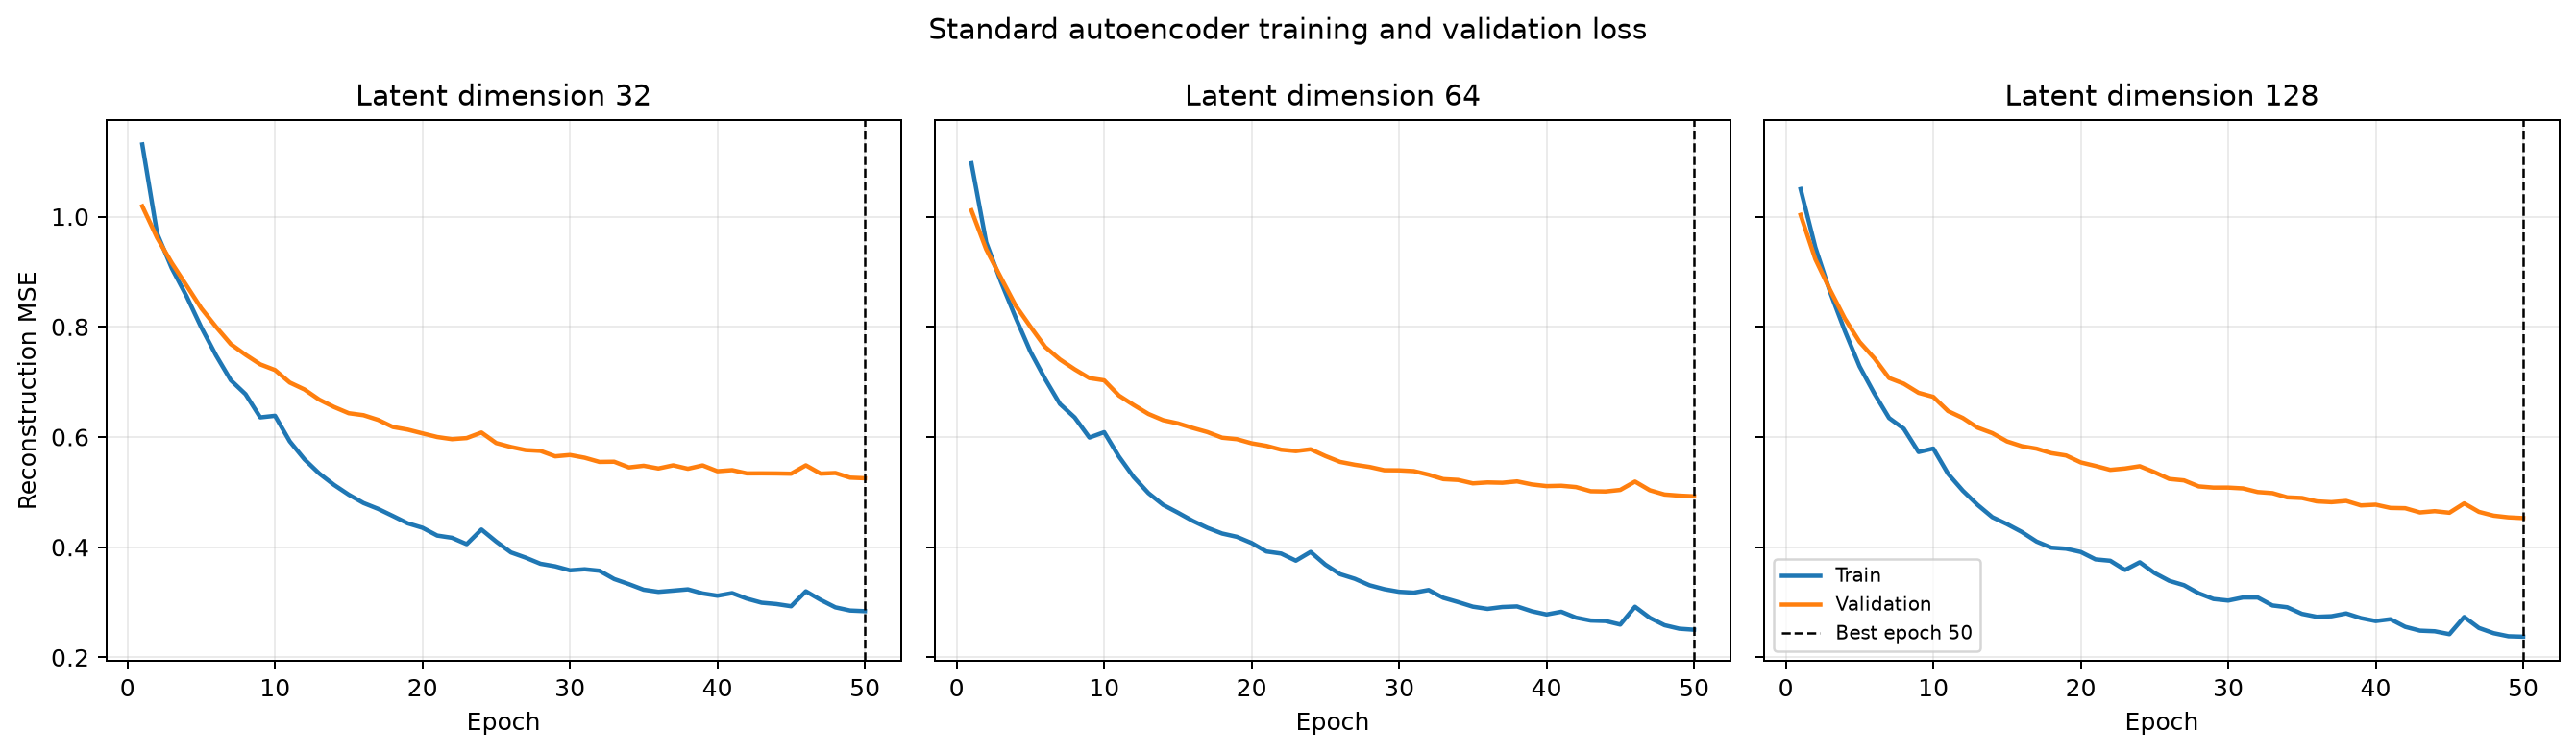

**Validation reconstruction MSE by latent dimension**

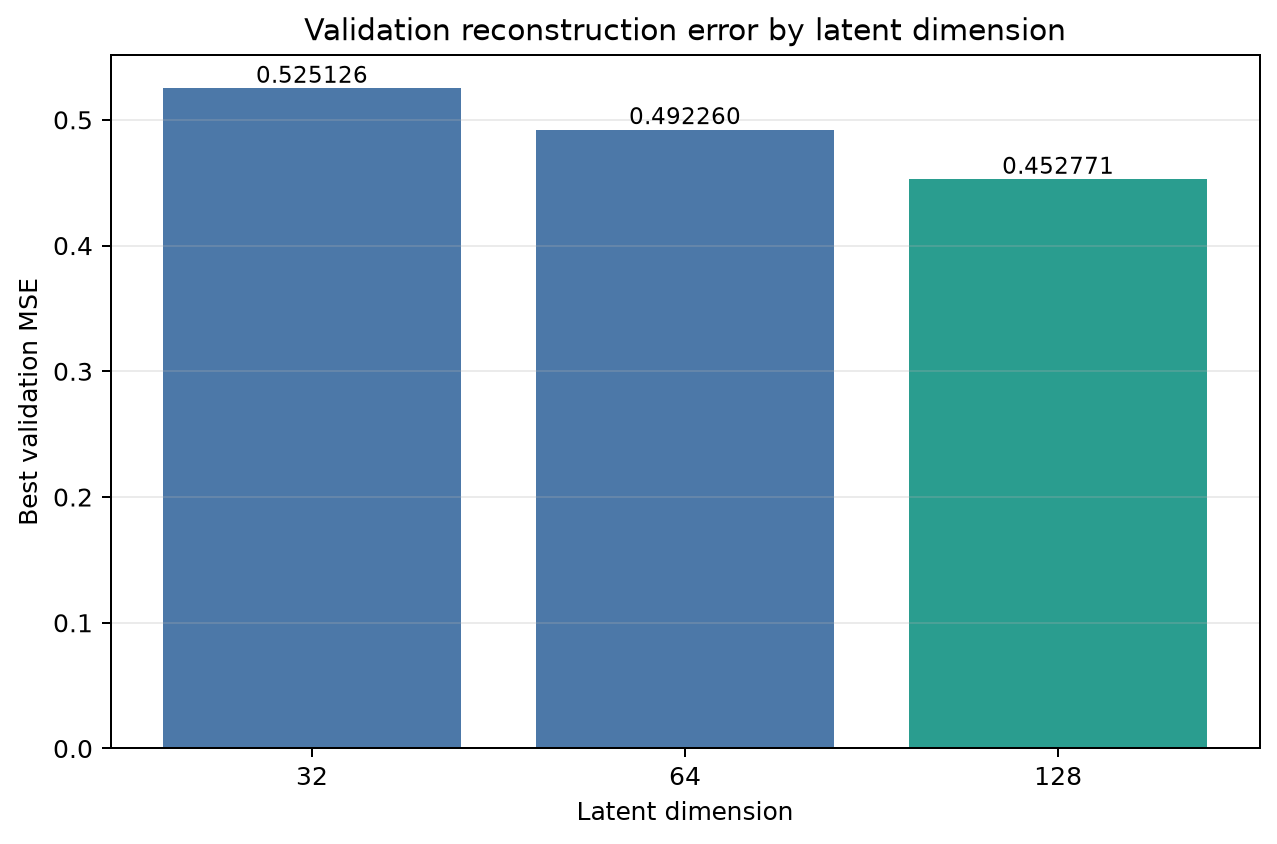

In [4]:
ae_results = pd.read_csv(RESULTS / "ae_comparison.csv")
display(
    ae_results[
        ["latent_dim", "parameter_count", "best_epoch", "best_validation_mse", "checkpoint_reload_exact"]
    ].rename(columns={
        "latent_dim": "Latent dimension", "parameter_count": "Parameters",
        "best_epoch": "Best epoch", "best_validation_mse": "Validation MSE",
        "checkpoint_reload_exact": "Exact reload",
    })
)

show_images([
    ("Training and validation reconstruction curves", FIGURES / "ae_training_curves.png"),
    ("Validation reconstruction MSE by latent dimension", FIGURES / "ae_validation_mse_comparison.png"),
])

## 5. Variational Autoencoder Architecture

The VAE uses the same 262-192-128 encoder backbone, followed by separate
64-dimensional mean and log-variance heads. A stochastic training code is
obtained through the reparameterization trick:

$$z=\mu+\exp\left(\tfrac{1}{2}\log\sigma^2\right)\odot\epsilon,
\qquad \epsilon\sim\mathcal N(0,I).$$

The decoder is $64\rightarrow128\rightarrow192\rightarrow262$. Evaluation
decodes $\mu$ rather than a random sample, making reconstruction and embedding
extraction deterministic. Reconstruction MSE is averaged over observations and
features. Gaussian KL is summed across latent dimensions, averaged across
observations, and divided by latent dimension in the optimized objective:

$$\mathcal L = \operatorname{MSE}(x,\hat x)
+\beta\frac{1}{D_z}\operatorname{KL}\bigl(q_\phi(z|x)\|\mathcal N(0,I)\bigr).$$

Because of this normalization, the logged objective is not presented as an
exact evidence lower bound.

In [5]:
vae_checkpoint = torch.load(CHECKPOINTS / "vae_best.pt", map_location="cpu", weights_only=False)
vae_architecture = pd.DataFrame(
    {
        "Checkpoint field": [
            "Input dimension", "Hidden dimensions", "Latent dimension", "Posterior",
            "Selected beta", "Warmup", "Parameters", "Best epoch",
            "Validation reconstruction MSE", "Posterior collapse detected",
        ],
        "Stored value": [
            vae_checkpoint["architecture"]["input_dim"], str(vae_checkpoint["architecture"]["hidden_dims"]),
            vae_checkpoint["architecture"]["latent_dim"], vae_checkpoint["architecture"]["posterior"],
            vae_checkpoint["training_config"]["target_beta"],
            f"{vae_checkpoint['warmup']['type']}, {vae_checkpoint['warmup']['epochs']} epochs",
            vae_checkpoint["parameter_count"], vae_checkpoint["best_epoch"],
            vae_checkpoint["best_validation_metrics"]["reconstruction_mse"],
            vae_checkpoint["posterior_collapse_detected"],
        ],
    }
)
display(vae_architecture)
display(pd.DataFrame([vae_checkpoint["loss_definition"]]).T.rename(columns={0: "Definition"}))

,Checkpoint field,Stored value
0,Input dimension,262
1,Hidden dimensions,"[192, 128]"
2,Latent dimension,64
3,Posterior,diagonal Gaussian
4,Selected beta,0.500000
5,Warmup,"linear, 10 epochs"
6,Parameters,175366
7,Best epoch,50
8,Validation reconstruction MSE,1.012741
9,Posterior collapse detected,False


,Definition
reconstruction,MSE averaged over observations and input features
kl_reported,Gaussian KL summed over latent dimensions and ...
kl_in_objective,reported KL divided by latent dimension
objective,reconstruction_mse + effective_beta * kl_per_l...
is_exact_elbo,False


## 6. VAE Beta Experiments: 0.5, 1.0 and 4.0

All VAE comparisons use latent dimension 64, seed 42, a ten-epoch linear beta
warmup, and selection after the minimum 30-epoch training period. The selected
configuration is the lowest validation reconstruction MSE among runs without
severe posterior collapse. Beta 0.5 satisfied that rule; beta 1 and beta 4
ended with very few active latent units.

,Beta,Best epoch,Validation reconstruction MSE,Validation KL / observation,Active units at checkpoint,Final active units,Severe collapse
0,0.500000,50,1.012741,0.626941,34,34,False
1,1.000000,30,1.021578,0.286190,9,2,True
2,4.000000,37,1.021564,0.227492,3,3,True


**Deterministic VAE reconstruction curves**

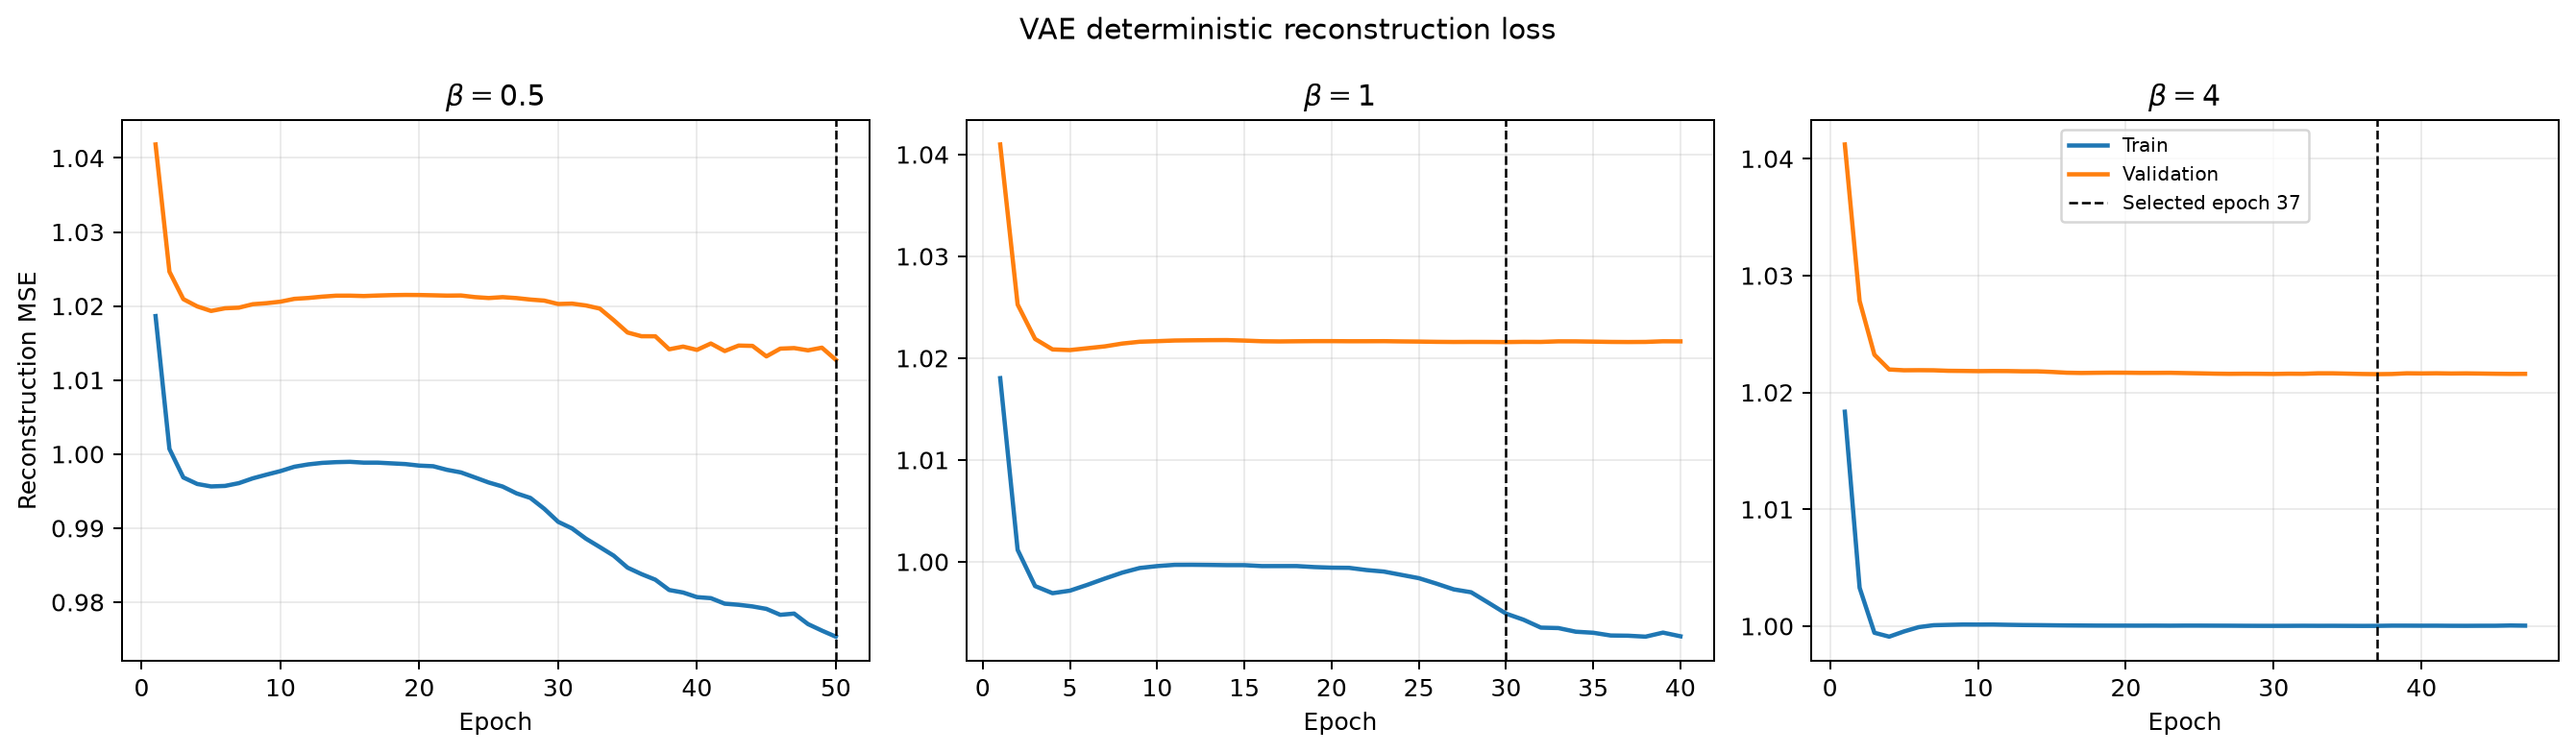

**VAE latent KL regularization**

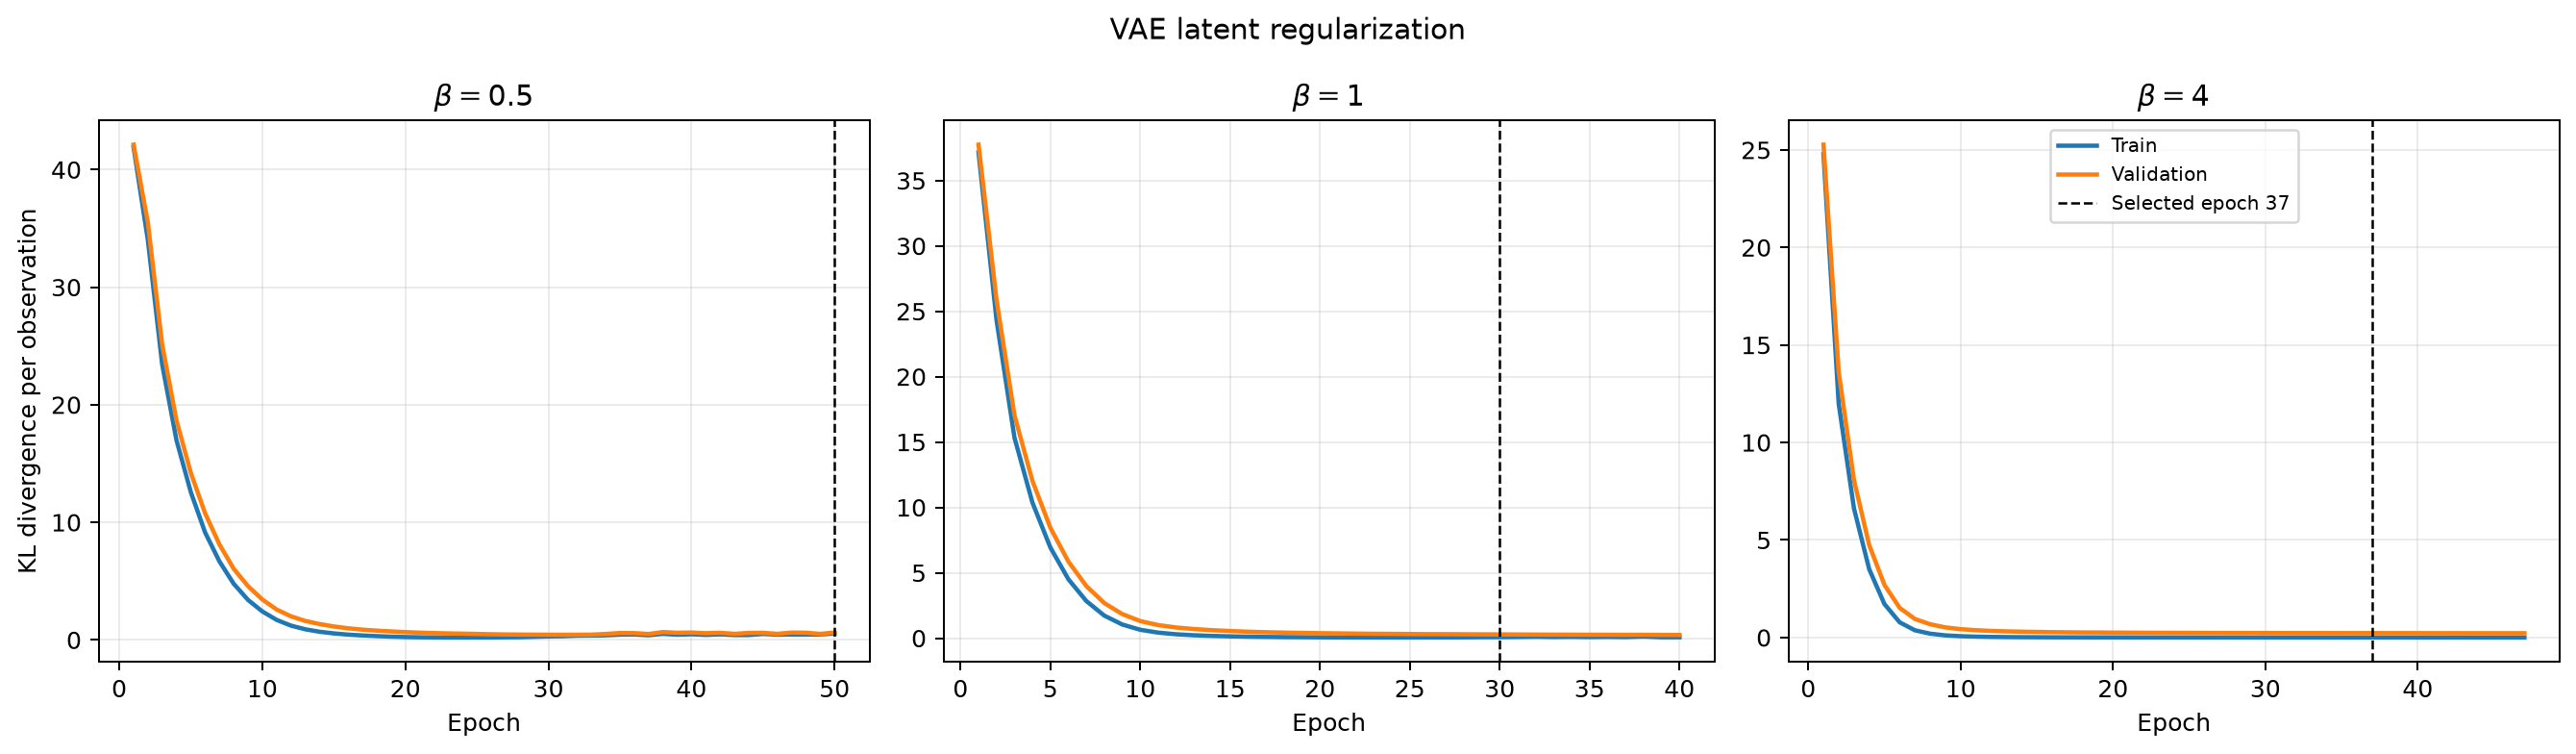

**Validation reconstruction by beta**

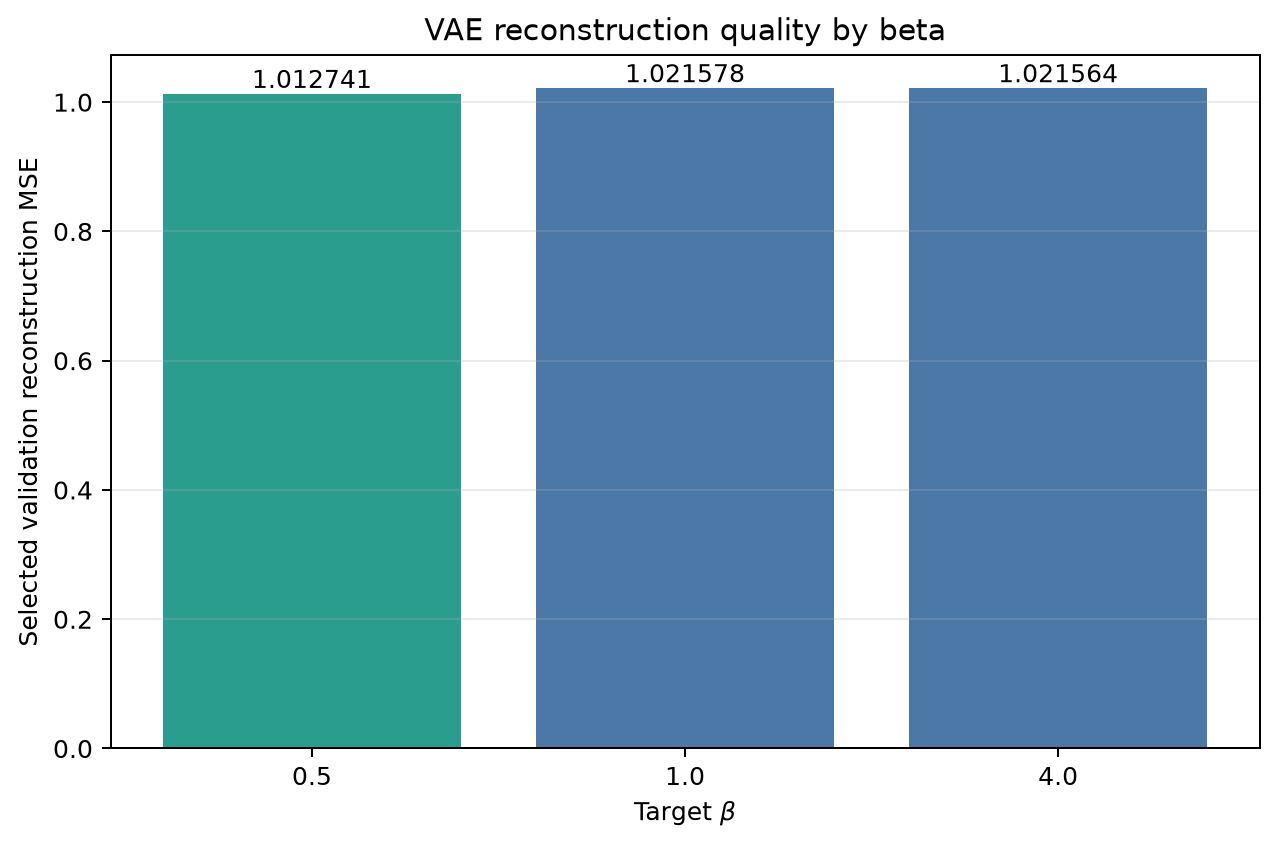

**Controlled AE z=64 and VAE z=64 comparison**

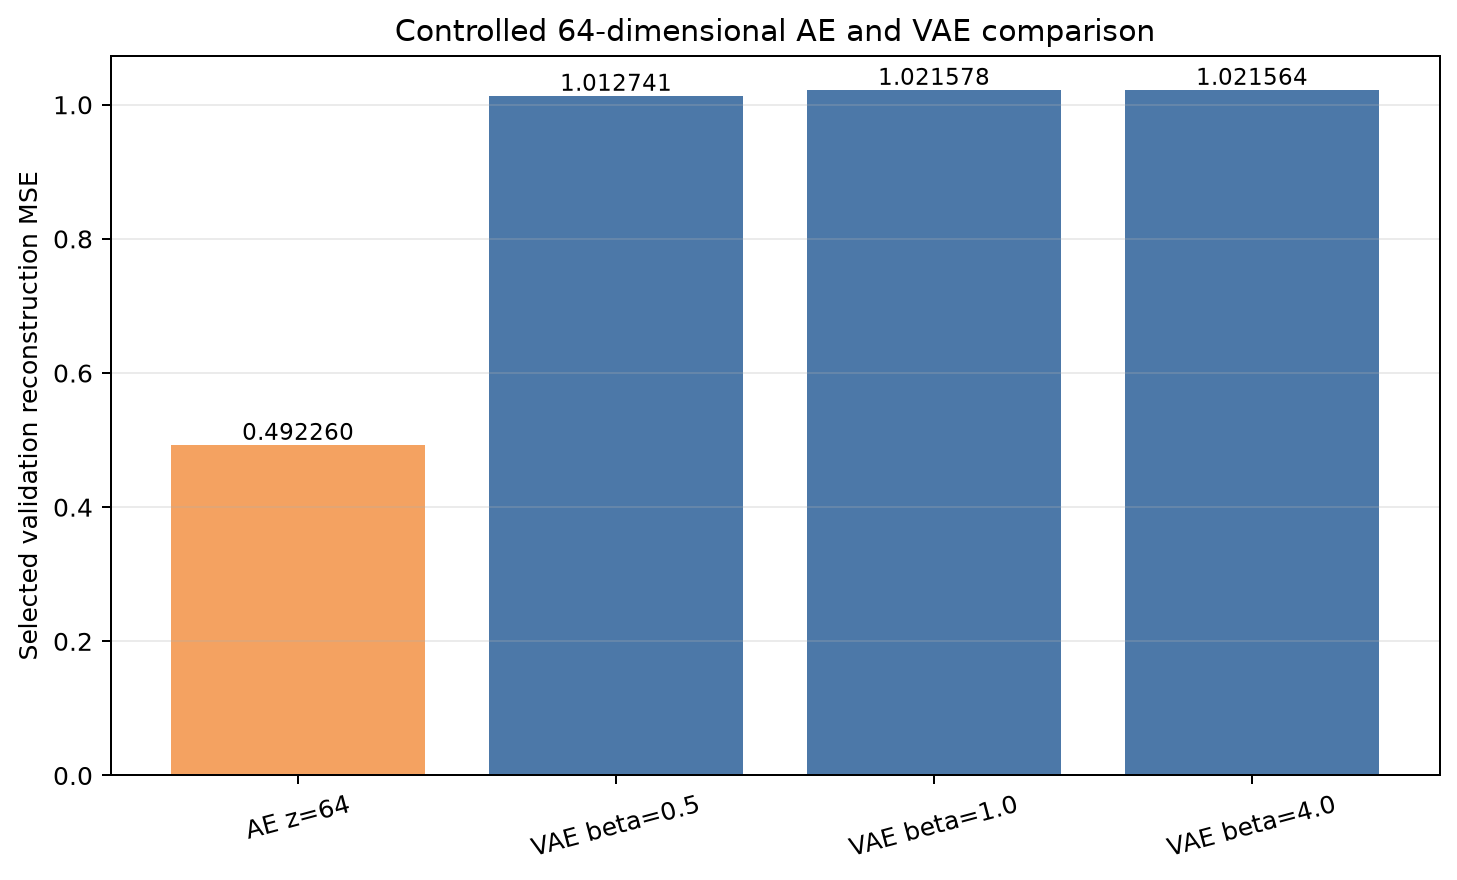

In [6]:
vae_results = pd.read_csv(RESULTS / "vae_comparison.csv")
display(
    vae_results[
        ["target_beta", "best_epoch", "validation_reconstruction_mse",
         "validation_kl_per_observation", "validation_active_units",
         "final_active_units", "posterior_collapse_detected"]
    ].rename(columns={
        "target_beta": "Beta", "best_epoch": "Best epoch",
        "validation_reconstruction_mse": "Validation reconstruction MSE",
        "validation_kl_per_observation": "Validation KL / observation",
        "validation_active_units": "Active units at checkpoint",
        "final_active_units": "Final active units",
        "posterior_collapse_detected": "Severe collapse",
    })
)

show_images([
    ("Deterministic VAE reconstruction curves", FIGURES / "vae_reconstruction_curves.png"),
    ("VAE latent KL regularization", FIGURES / "vae_kl_curves.png"),
    ("Validation reconstruction by beta", FIGURES / "vae_validation_reconstruction_by_beta.png"),
    ("Controlled AE z=64 and VAE z=64 comparison", FIGURES / "ae64_vae_validation_comparison.png"),
])

## 7. Training Stability and Posterior Collapse

The selected AE z=128 and VAE beta 0.5 were repeated with seeds 7, 42, and
2026. The AE was both more accurate and more stable. VAE outcomes varied in KL,
active-unit usage, and reconstruction, showing that the variational solution is
sensitive to initialization on this small tabular dataset. Posterior collapse
diagnostics use the final KL per latent dimension and active-unit count; they
are diagnostics, not a substitute for validation reconstruction.

,Configuration,Seeds,Mean validation MSE,Sample standard deviation,Minimum,Maximum
0,AE z=128,"[7, 42, 2026]",0.457292,0.011050,0.449218,0.469885
1,VAE z=64 beta=0.5,"[7, 42, 2026]",0.921033,0.082330,0.853488,1.012741


,target_beta,validation_active_units,minimum_active_units_at_full_beta,final_active_units,final_kl_per_latent,posterior_collapse_detected
0,0.500000,34,21,34,0.009796,False
1,1.000000,9,2,2,0.003835,True
2,4.000000,3,3,3,0.003439,True


**AE and VAE validation stability across seeds**

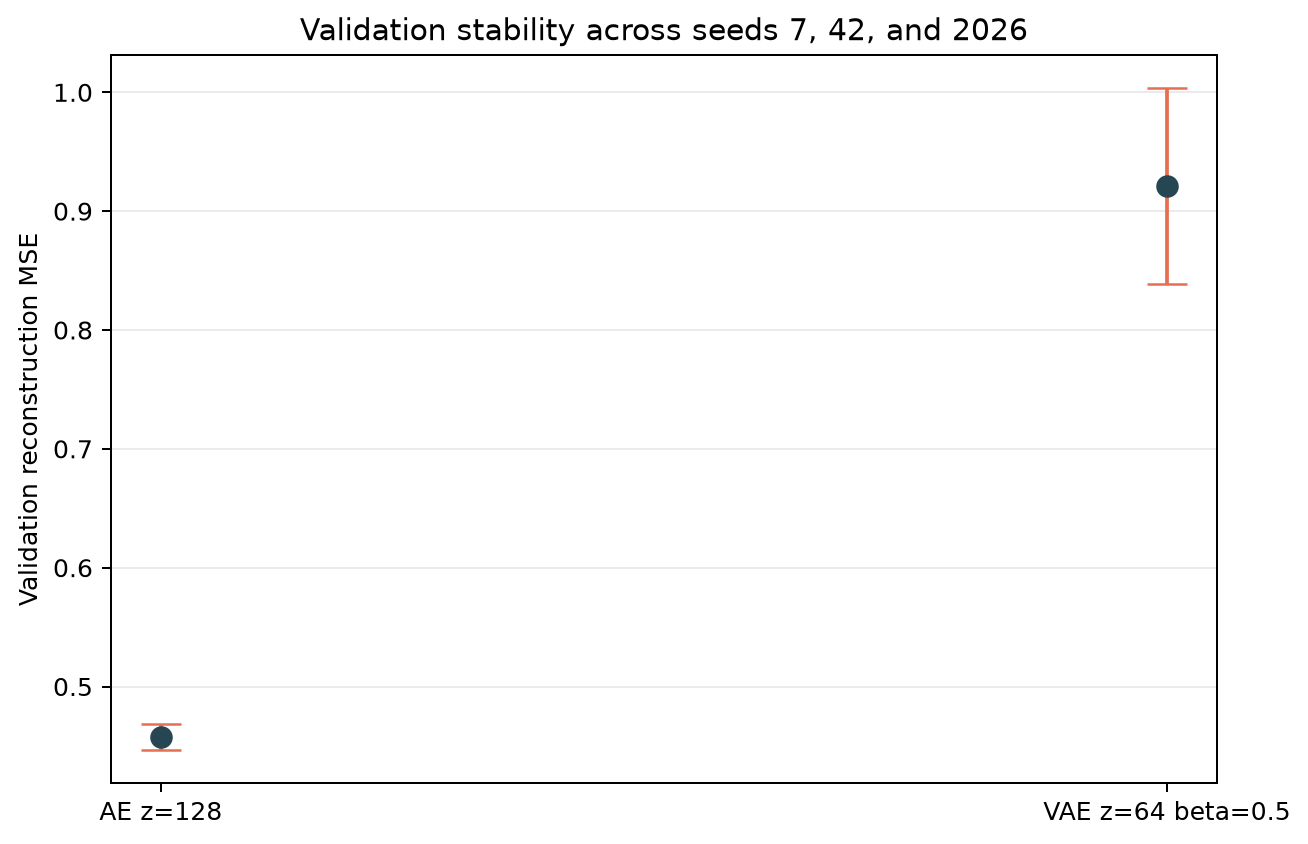

**Beta-specific normalized training objectives**

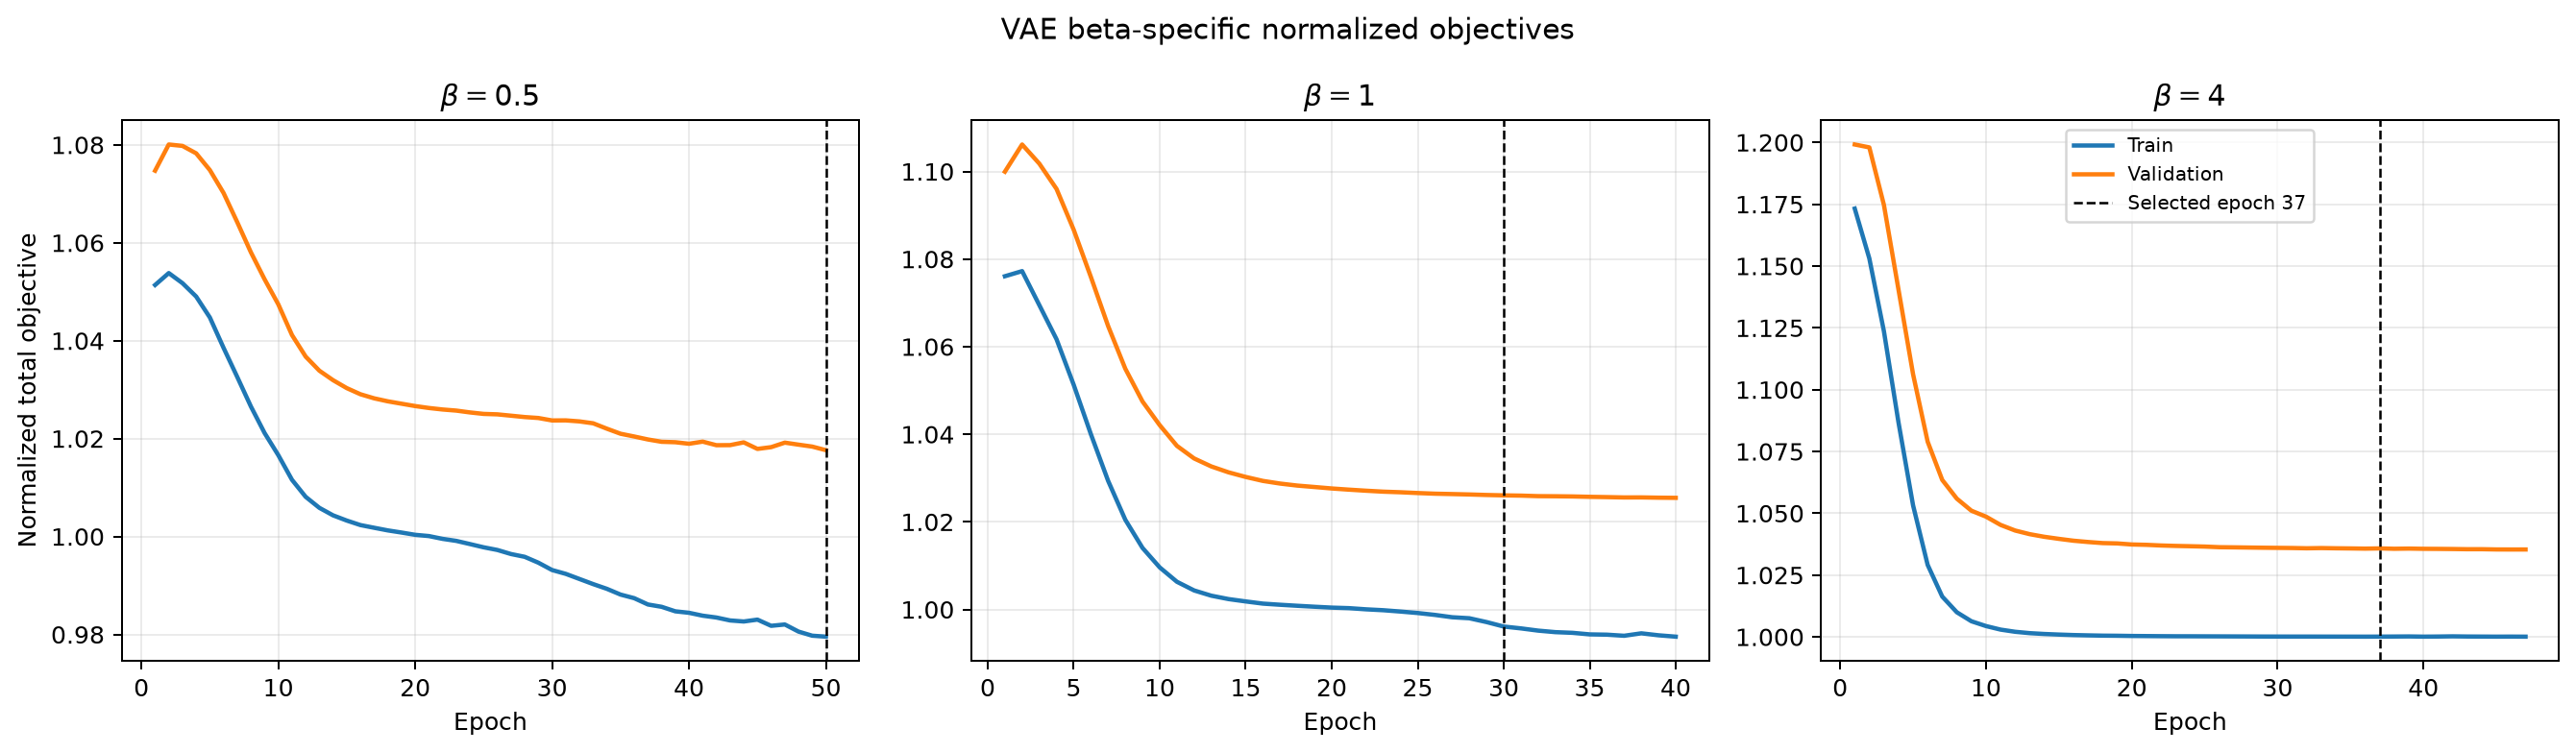

In [7]:
ae_seeds = pd.read_csv(RESULTS / "ae128_seed_runs.csv")
vae_seeds = pd.read_csv(RESULTS / "vae_selected_seed_runs.csv")
stability = read_json(RESULTS / "ae_vae_stability_summary.json")

stability_table = pd.DataFrame(stability)[
    ["model_configuration", "seeds", "mean_validation_mse", "std_validation_mse", "min_validation_mse", "max_validation_mse"]
].rename(columns={
    "model_configuration": "Configuration", "seeds": "Seeds",
    "mean_validation_mse": "Mean validation MSE", "std_validation_mse": "Sample standard deviation",
    "min_validation_mse": "Minimum", "max_validation_mse": "Maximum",
})
display(stability_table)

collapse_table = vae_results[
    ["target_beta", "validation_active_units", "minimum_active_units_at_full_beta",
     "final_active_units", "final_kl_per_latent", "posterior_collapse_detected"]
]
display(collapse_table)

show_images([
    ("AE and VAE validation stability across seeds", FIGURES / "ae_vae_seed_stability.png"),
    ("Beta-specific normalized training objectives", FIGURES / "vae_total_objective_curves.png"),
])

## 8. Final Reconstruction Evaluation

After validation-only selection, `ae_best.pt` and `vae_best.pt` were loaded
without retraining and evaluated on all 440 original test observations. These
are **test** metrics and must not be used to revise the selected latent
dimension or beta. MSE, MAE, per-observation errors, per-feature errors, and
Pearson correlation are calculated in the train-standardized transformed
feature space.

The AE reconstructs the held-out matrix substantially better. The VAE's lower
one-hot MAE does not imply categorical correctness because its outputs are
continuous and its one-hot MSE/correlation remain worse.

,model,feature_group,feature_count,reconstruction_mse,reconstruction_mae,pearson_correlation,evaluation_observations,scale
0,AE,all,262,0.399277,0.359611,0.762230,440,train-standardized transformed feature space
1,AE,continuous,62,0.442426,0.438086,0.754514,440,train-standardized transformed feature space
2,AE,one_hot,200,0.385901,0.335283,0.764806,440,train-standardized transformed feature space
3,VAE,all,262,0.940321,0.419778,0.091476,440,train-standardized transformed feature space
4,VAE,continuous,62,1.017783,0.709241,0.075016,440,train-standardized transformed feature space
5,VAE,one_hot,200,0.916308,0.330044,0.097469,440,train-standardized transformed feature space


Per-observation score rows: 440
Per-feature metric rows: 524


**Distribution of test reconstruction errors**

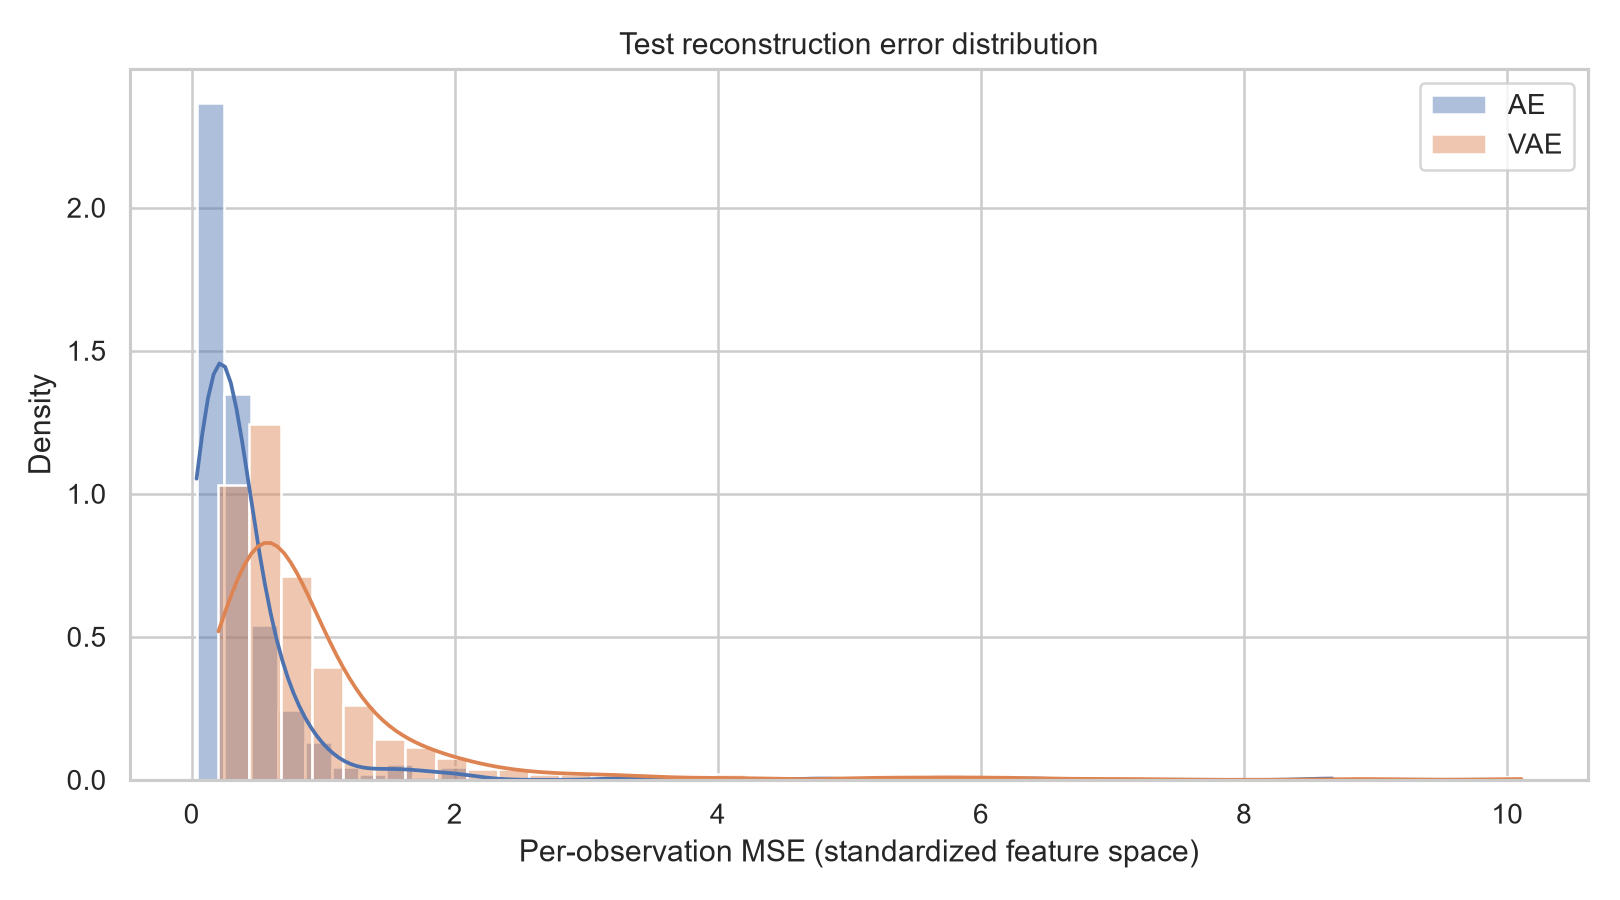

**Quantile-selected reconstruction profiles**

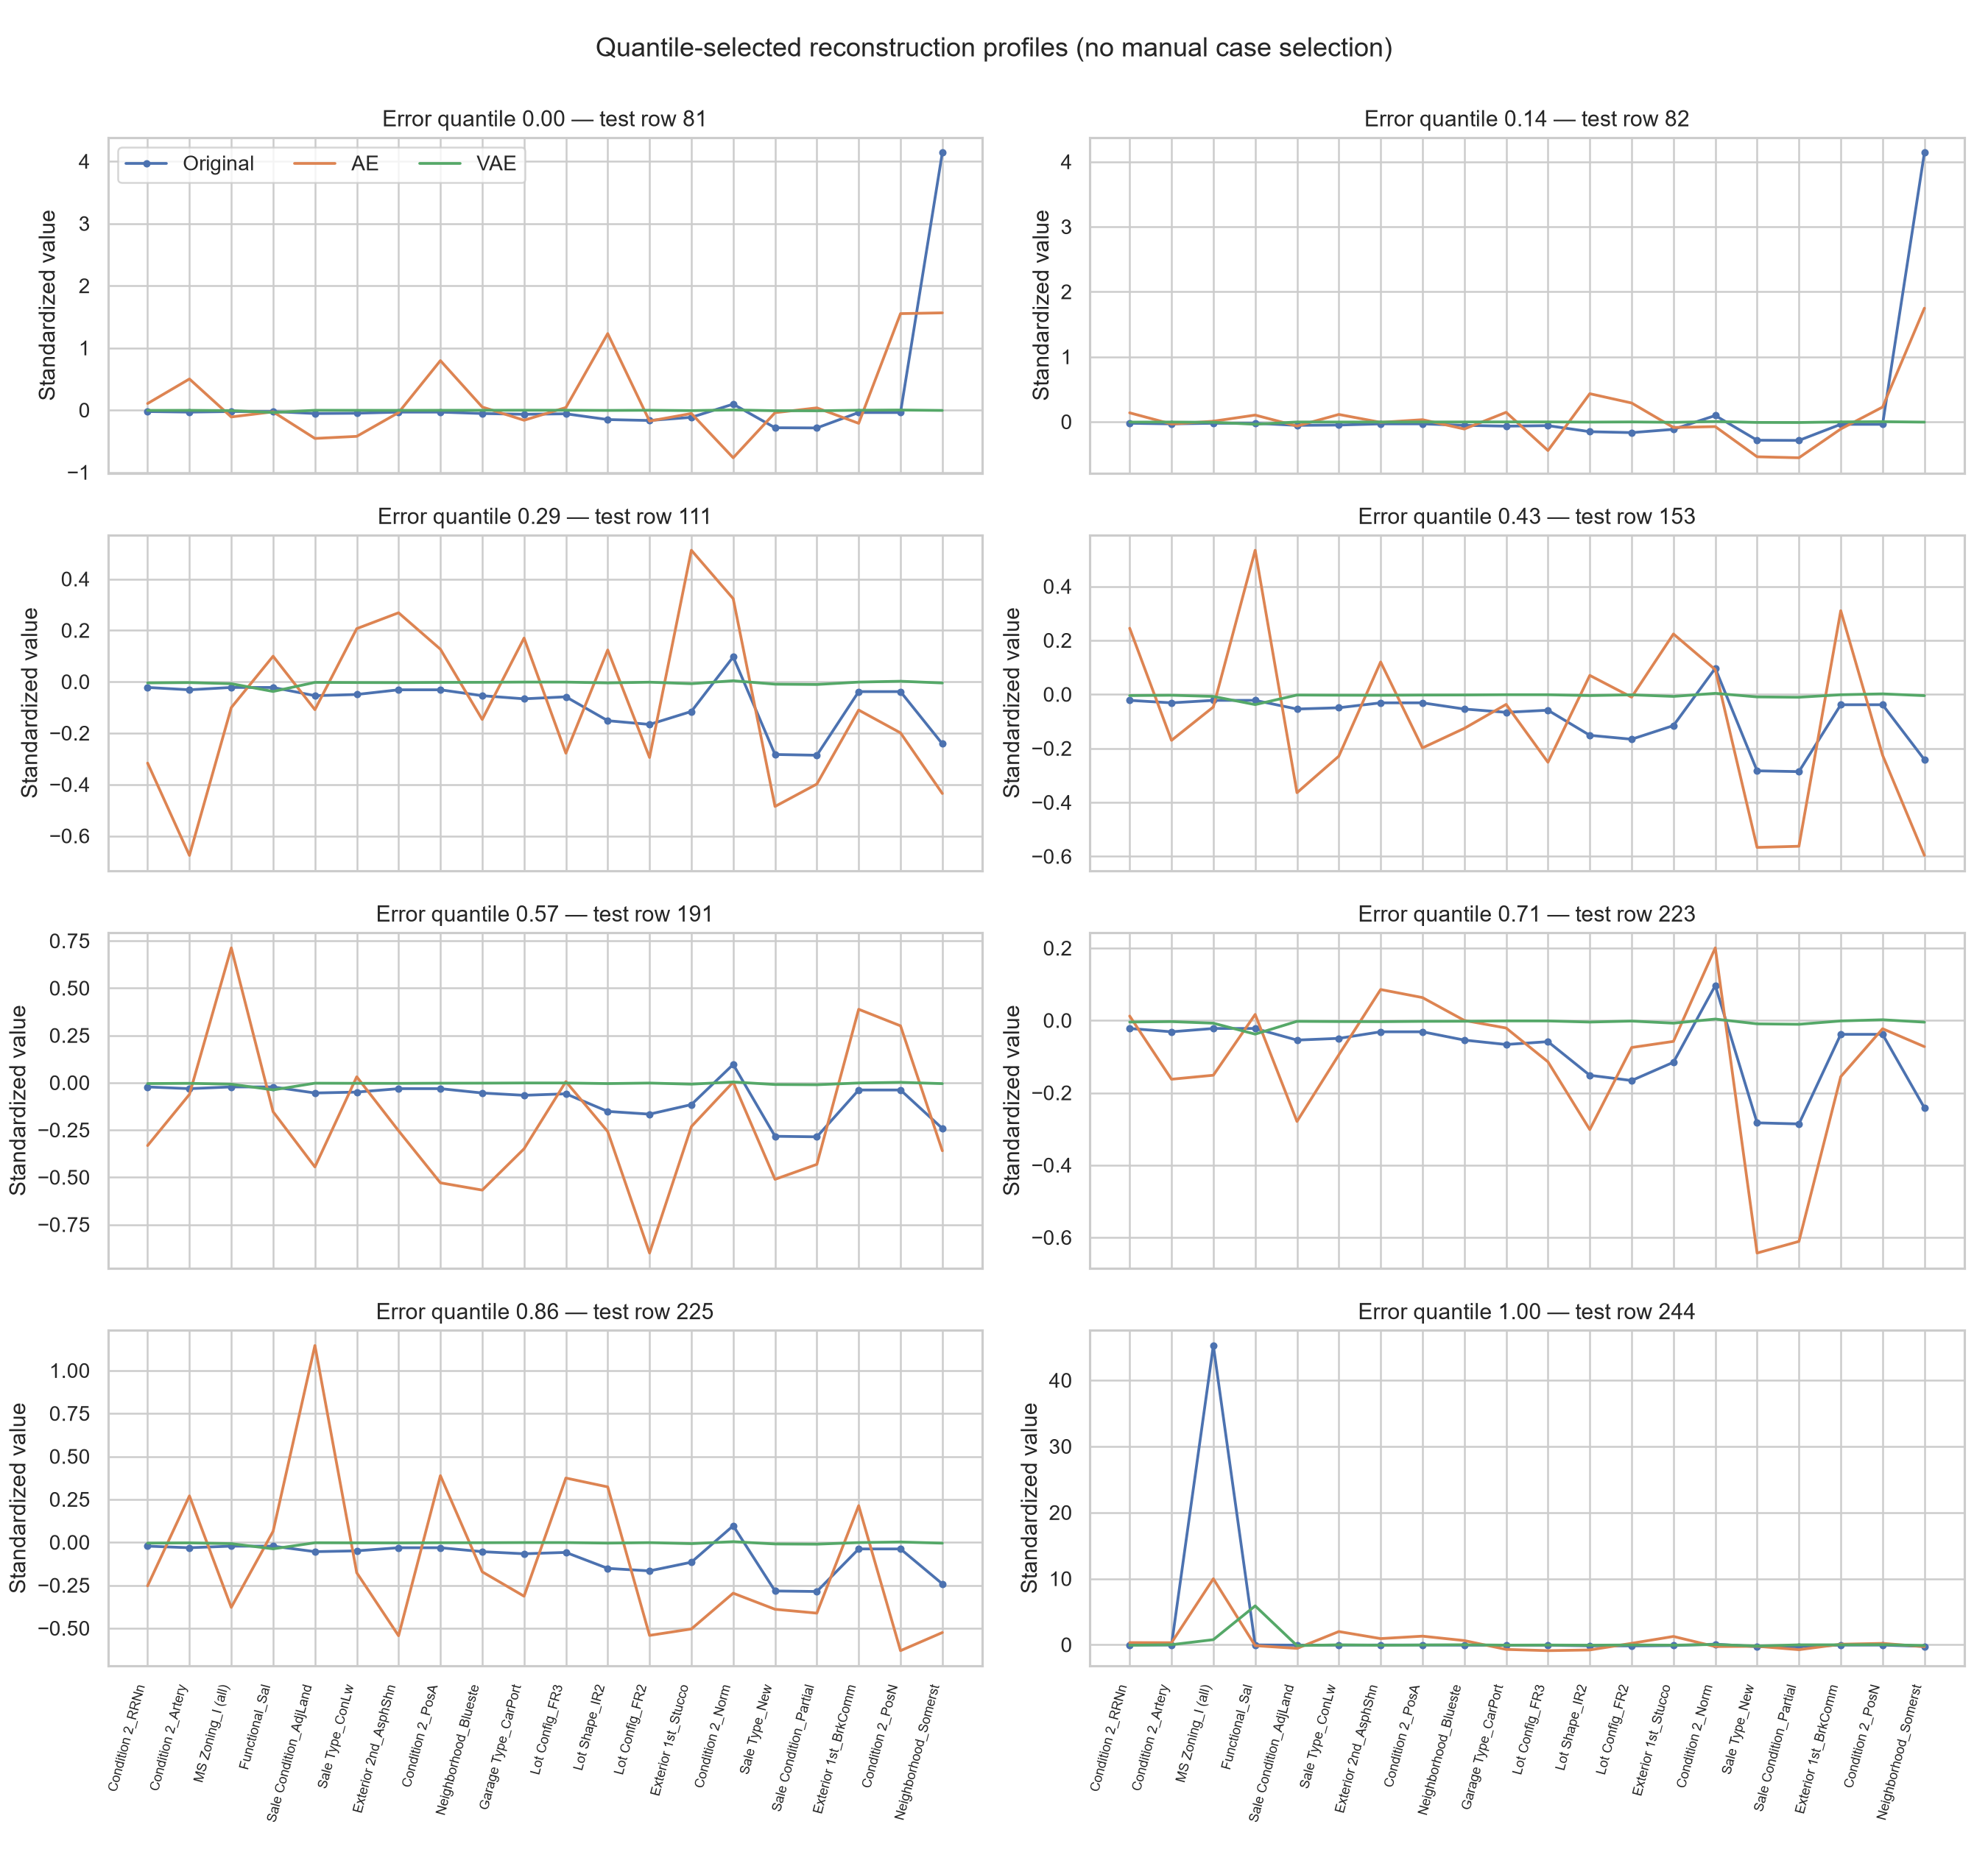

**Original values, reconstructions, and absolute differences**

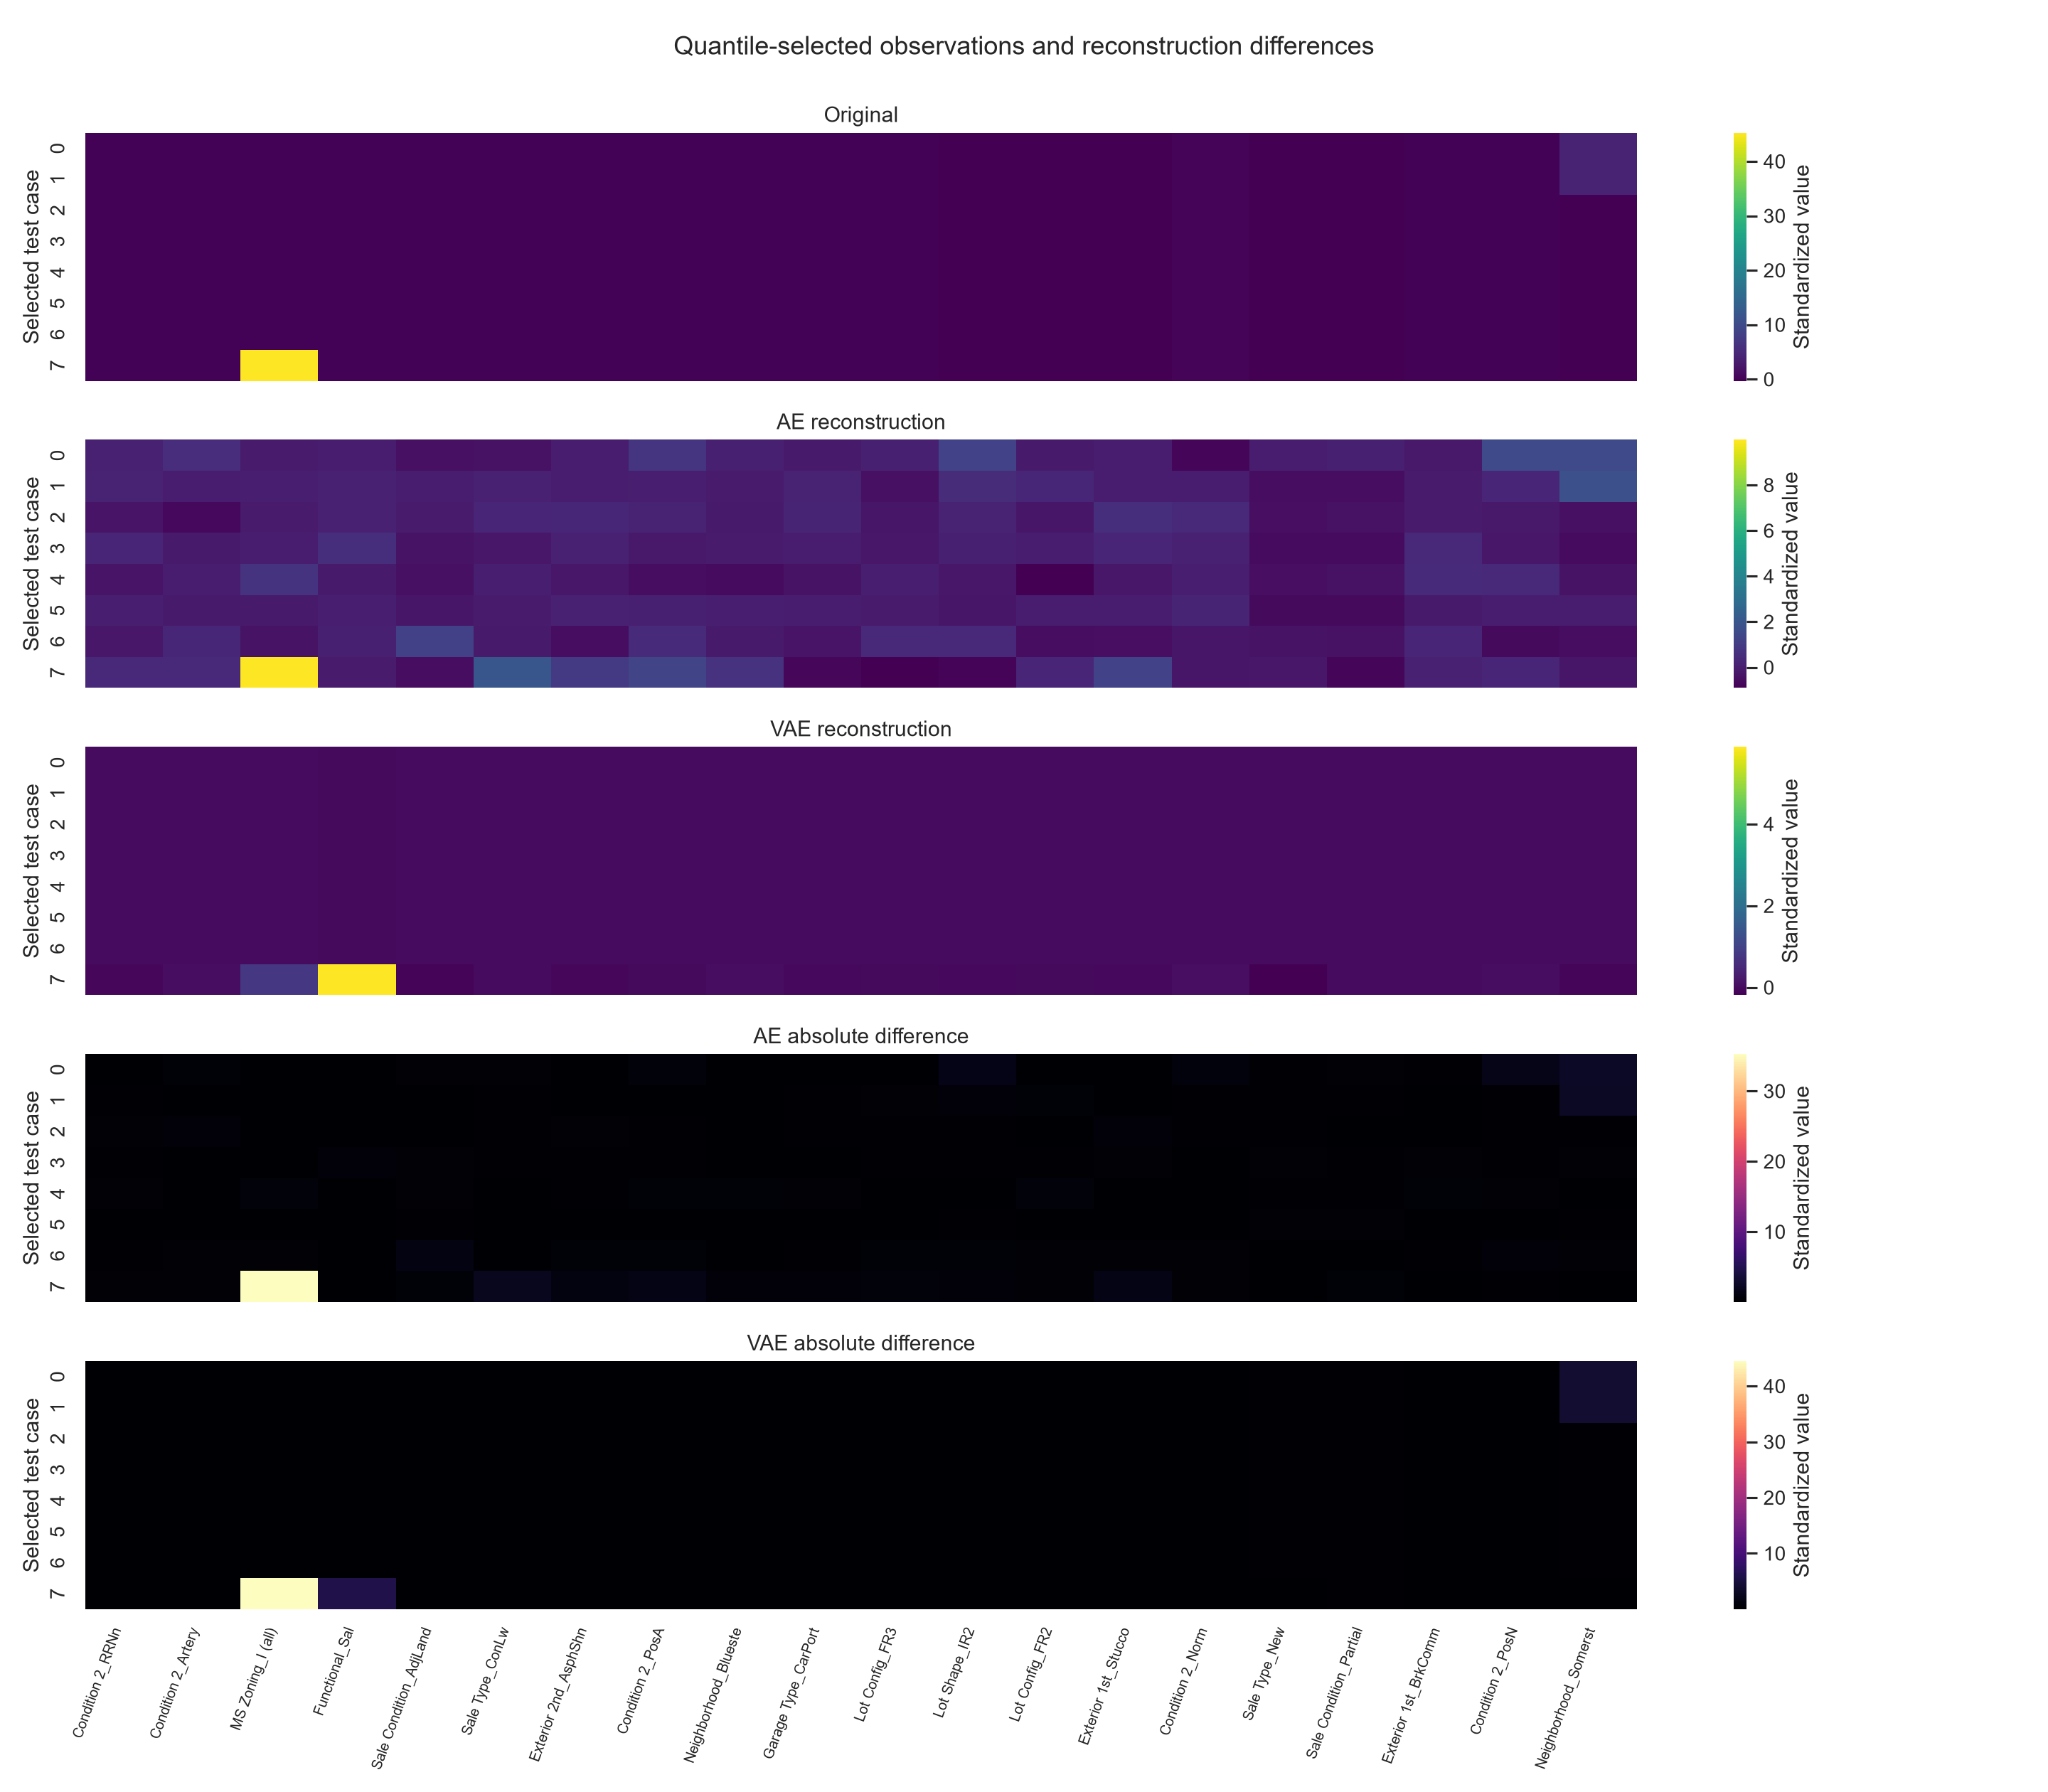

**Features with the largest mean reconstruction error**

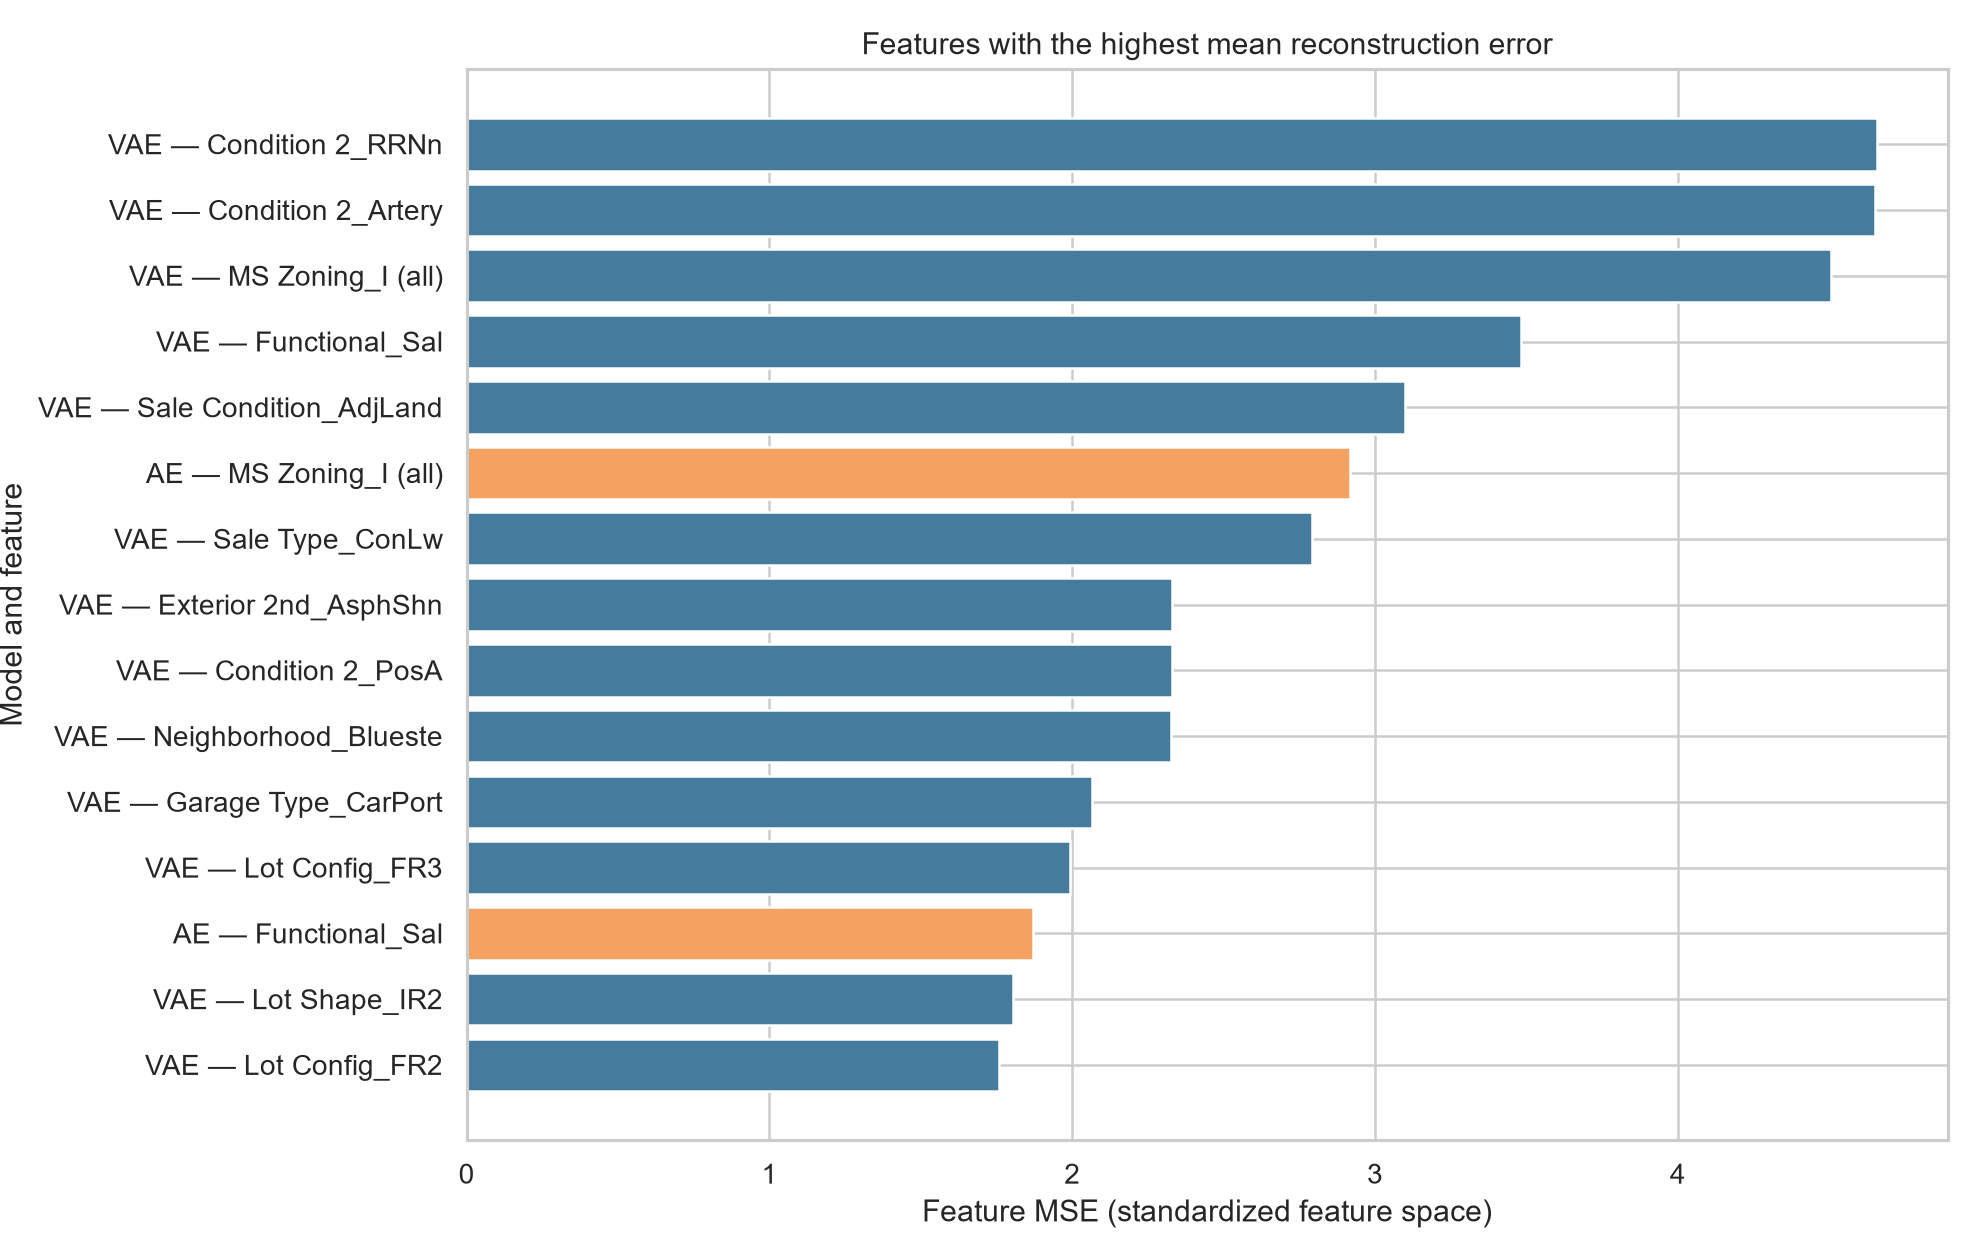

**Frozen-model test MSE and MAE**

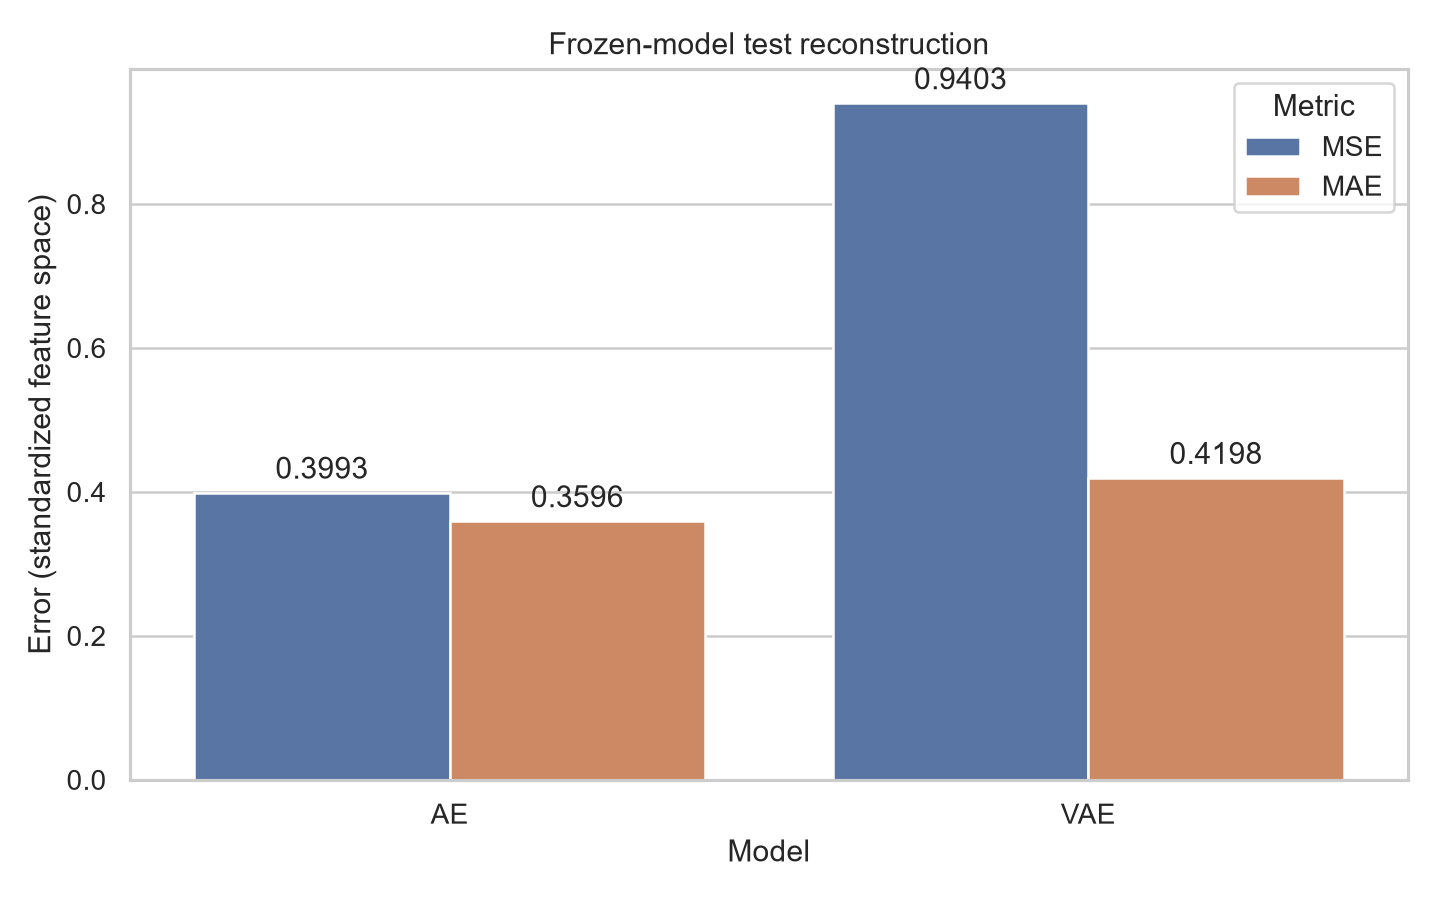

In [8]:
reconstruction = pd.read_csv(RESULTS / "reconstruction_metrics.csv")
display(reconstruction)

observation_scores = pd.read_csv(RESULTS / "reconstruction_observation_scores.csv")
feature_scores = pd.read_csv(RESULTS / "reconstruction_feature_metrics.csv")
print(f"Per-observation score rows: {len(observation_scores)}")
print(f"Per-feature metric rows: {len(feature_scores)}")

show_images([
    ("Distribution of test reconstruction errors", FIGURES / "reconstruction" / "reconstruction_error_distribution.png"),
    ("Quantile-selected reconstruction profiles", FIGURES / "reconstruction" / "quantile_reconstruction_profiles.png"),
    ("Original values, reconstructions, and absolute differences", FIGURES / "reconstruction" / "reconstruction_heatmaps.png"),
    ("Features with the largest mean reconstruction error", FIGURES / "reconstruction" / "highest_error_features.png"),
    ("Frozen-model test MSE and MAE", FIGURES / "reconstruction" / "test_mse_mae_comparison.png"),
])

## 9. Anomaly Detection Methodology

This experiment is independent from the general reconstruction evaluation.
Only `Normal` training transactions are used to fit preprocessing and the
anomaly-specific AE/VAE. `Sale Condition`, `SalePrice`, identifiers, and the
exported index are removed before fitting any transformation. Checkpoint
selection uses only `Normal` validation observations.

AE anomaly score is per-observation reconstruction MSE. The VAE is assessed
with reconstruction MSE and with
$\operatorname{MSE}+0.5\operatorname{KL}/D_z$. Each decision threshold is the
95th percentile of the corresponding score among `Normal` validation cases.
The primary binary test evaluation maps `Normal=0`, `Abnorml=1` and excludes
`Partial`, `Family`, `Alloca`, and `AdjLand`. `Abnorml` describes a transaction
condition, not necessarily a structurally anomalous dwelling.

,Protocol item,Value
0,Normal training observations,1694
1,Validation Normal observations,366
2,Anomaly input dimension,248
3,Excluded input columns,"Unnamed: 0, Order, PID, SalePrice, Sale Condition"
4,Threshold rule,Normal validation transactions only
5,Primary test Normal,353
6,Primary test Abnorml,19
7,Bootstrap replicates,2000


,Score,Validation-only threshold
0,AE reconstruction MSE,1.521338
1,VAE reconstruction MSE,2.973312
2,VAE reconstruction MSE + beta*KL/latent,2.997790


**Training histories for anomaly-specific models**

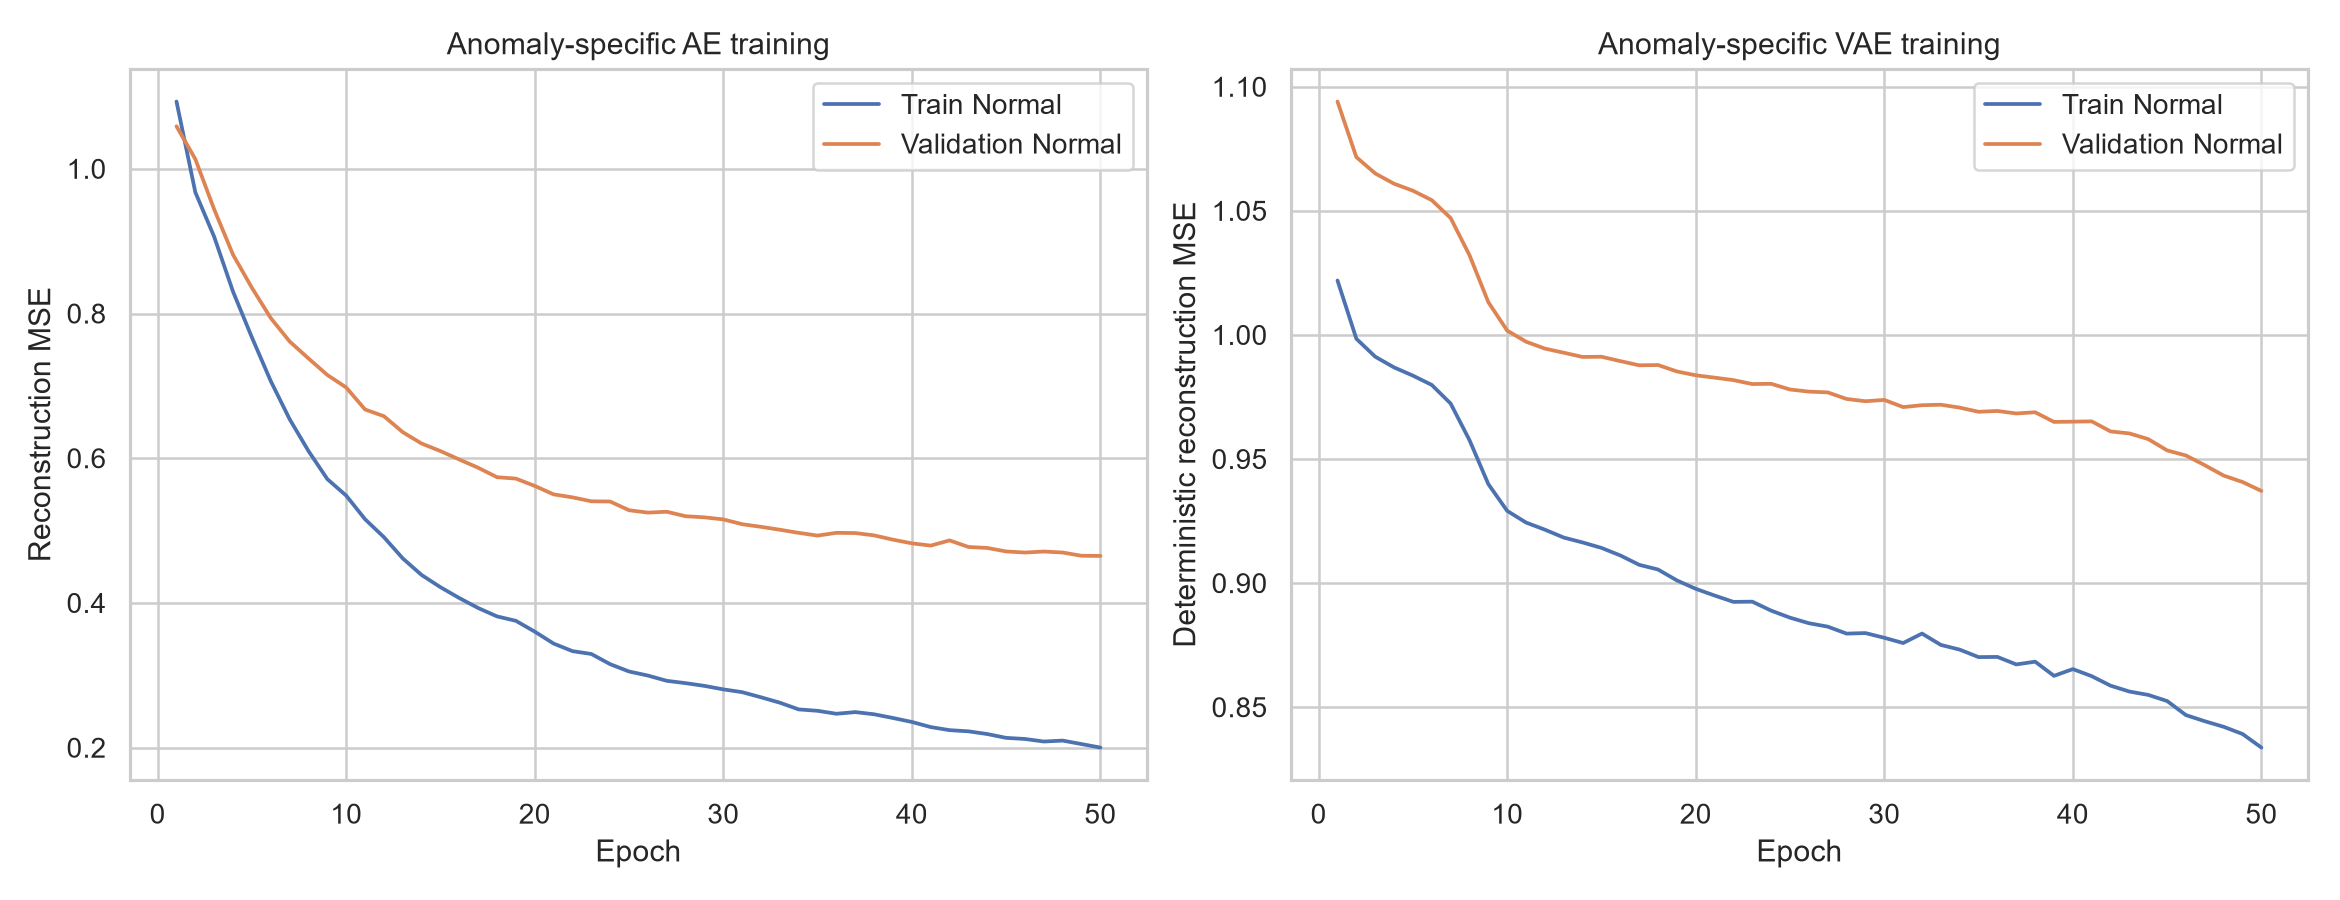

In [9]:
methodology_table = pd.DataFrame(
    {
        "Protocol item": [
            "Normal training observations", "Validation Normal observations",
            "Anomaly input dimension", "Excluded input columns", "Threshold rule",
            "Primary test Normal", "Primary test Abnorml", "Bootstrap replicates",
        ],
        "Value": [
            anomaly_protocol["train_normal_count"],
            anomaly_protocol["validation_label_counts"]["Normal"],
            anomaly_protocol["input_dim_after_excluding_sale_condition"],
            ", ".join(anomaly_protocol["excluded_columns"]),
            anomaly_protocol["threshold_fit_data"],
            anomaly_protocol["primary_test_counts"]["Normal"],
            anomaly_protocol["primary_test_counts"]["Abnorml"],
            anomaly_protocol["bootstrap"]["replicates"],
        ],
    }
)
display(methodology_table)
display(pd.DataFrame(anomaly_protocol["thresholds"].items(), columns=["Score", "Validation-only threshold"]))

show_images([
    ("Training histories for anomaly-specific models", FIGURES / "anomaly" / "anomaly_training_curves.png"),
])

## 10. Anomaly Detection Results

The AE obtains the highest ROC-AUC, recall, and F1 under the validation-only
threshold, but detects only 3 of 19 `Abnorml` test cases. VAE reconstruction has
a marginally higher PR-AUC point estimate, while all bootstrap intervals are
wide. Adding normalized KL does not improve discrimination. Score distributions
overlap strongly, illustrating why lower general reconstruction error does not
automatically imply effective anomaly detection.

,score_definition,threshold,threshold_source,normal_test_count,abnorml_test_count,roc_auc,pr_auc,precision,recall,f1,true_negative,false_positive,false_negative,true_positive,replicates,roc_auc_ci_low,roc_auc_ci_high,pr_auc_ci_low,pr_auc_ci_high,limitation
0,AE reconstruction MSE,1.521338,95th percentile of Normal validation scores,353,19,0.631728,0.132986,0.230769,0.157895,0.187500,343,10,16,3,2000,0.497081,0.760116,0.065613,0.307392,Percentile intervals use a small positive clas...
1,VAE reconstruction MSE,2.973312,95th percentile of Normal validation scores,353,19,0.607127,0.141447,0.181818,0.105263,0.133333,344,9,17,2,2000,0.464433,0.743261,0.059162,0.293383,Percentile intervals use a small positive clas...
2,VAE reconstruction MSE + beta*KL/latent,2.997790,95th percentile of Normal validation scores,353,19,0.606381,0.141300,0.166667,0.105263,0.129032,343,10,17,2,2000,0.465465,0.744897,0.058940,0.294007,Percentile intervals use a small positive clas...


,sale_condition,score,count,mean,median,q25,q75
0,Normal,ae_reconstruction_mse,353,0.405777,0.254061,0.162187,0.456033
1,Normal,vae_reconstruction_mse,353,0.809583,0.569521,0.355092,0.880649
2,Normal,vae_combined_score,353,0.841470,0.588791,0.376222,0.919708
3,Abnorml,ae_reconstruction_mse,19,0.883030,0.418994,0.204508,0.728504
4,Abnorml,vae_reconstruction_mse,19,1.458386,0.791847,0.390158,1.231148
5,Abnorml,vae_combined_score,19,1.499708,0.848920,0.419556,1.273375


**Anomaly-score distributions by native Sale Condition**

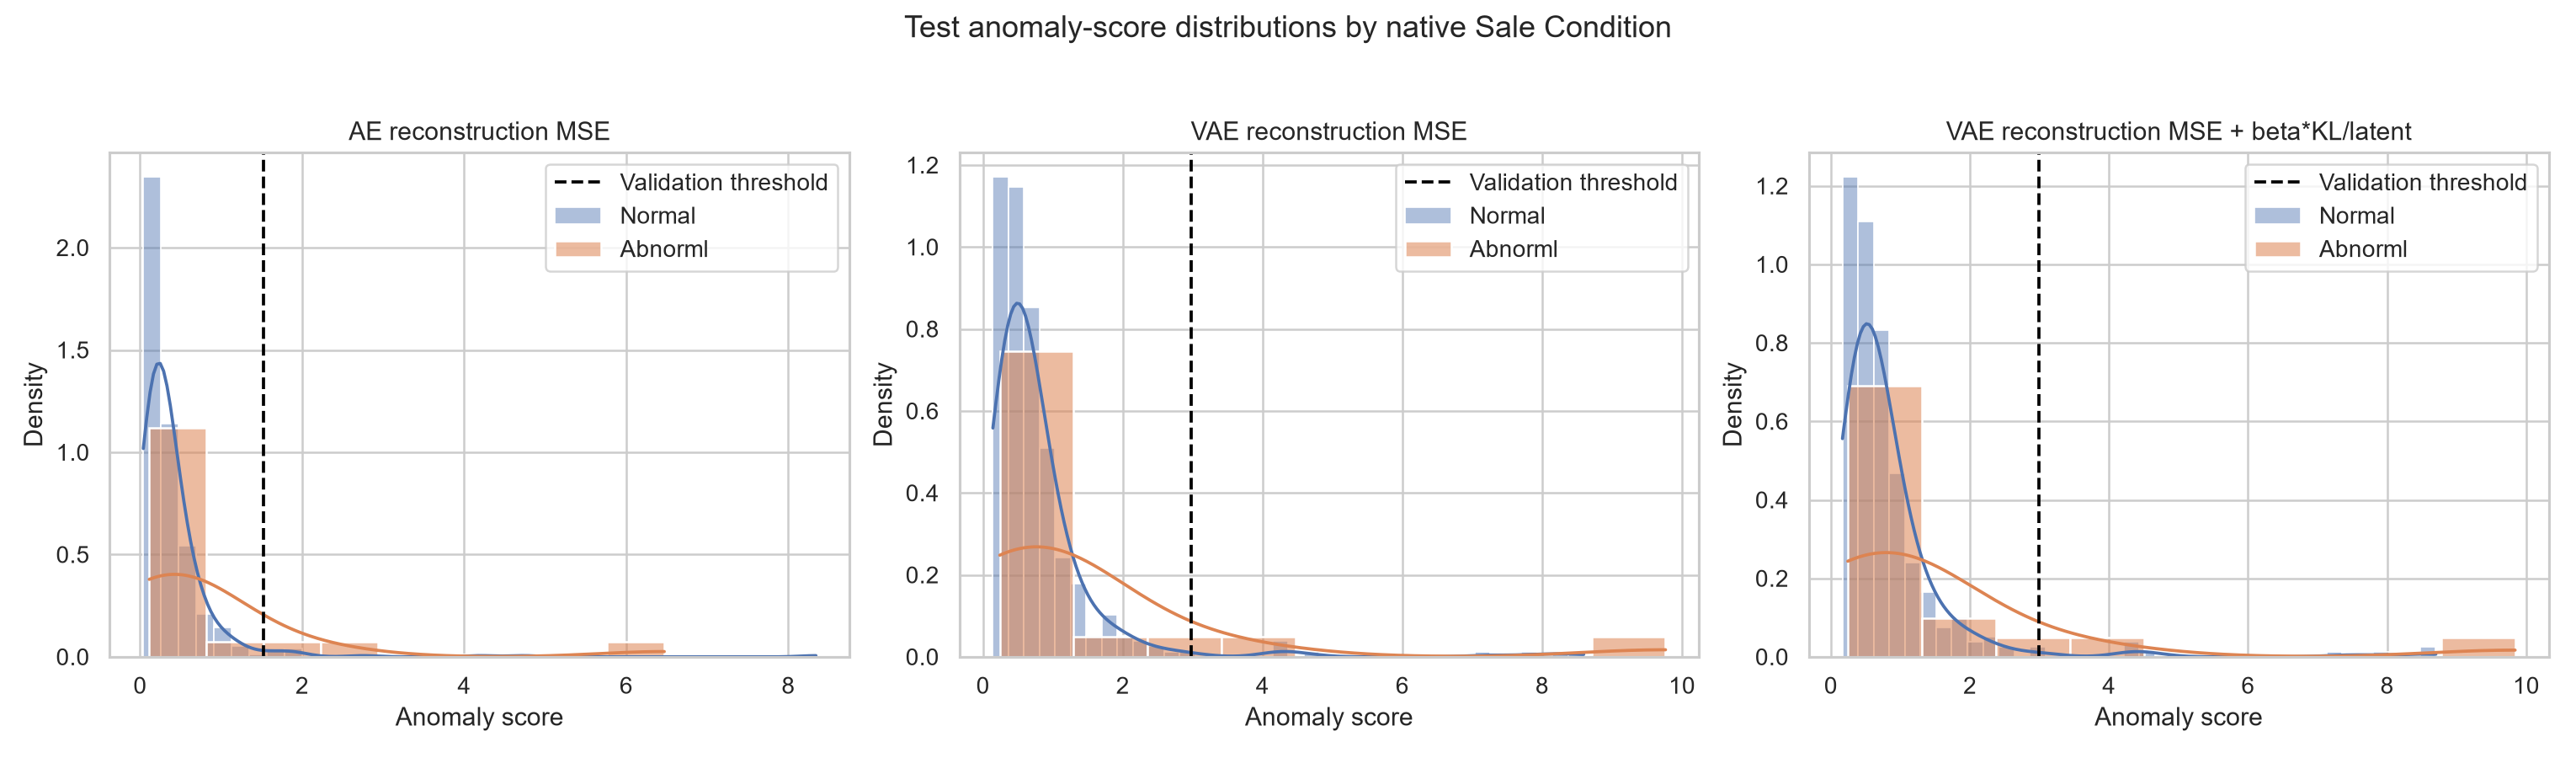

**ROC and Precision–Recall curves**

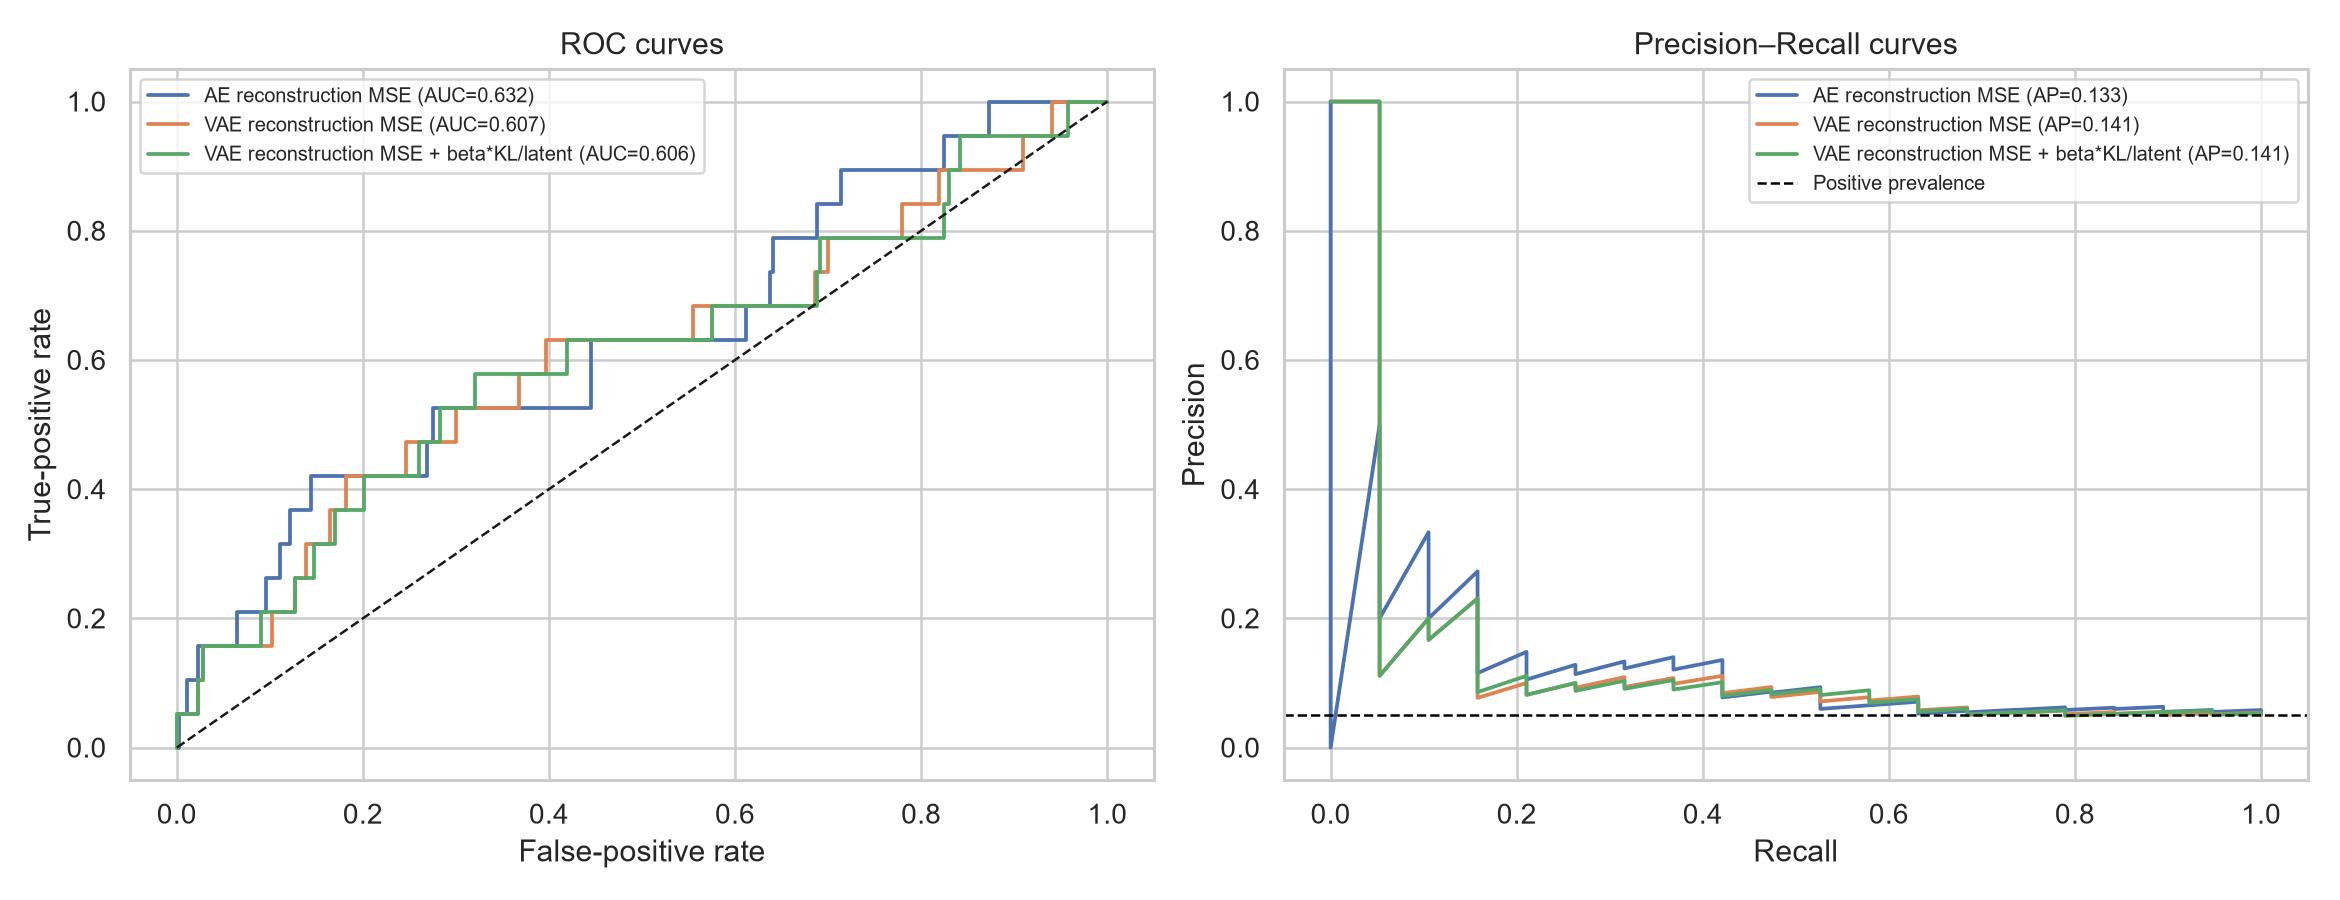

**Confusion matrices using validation-only thresholds**

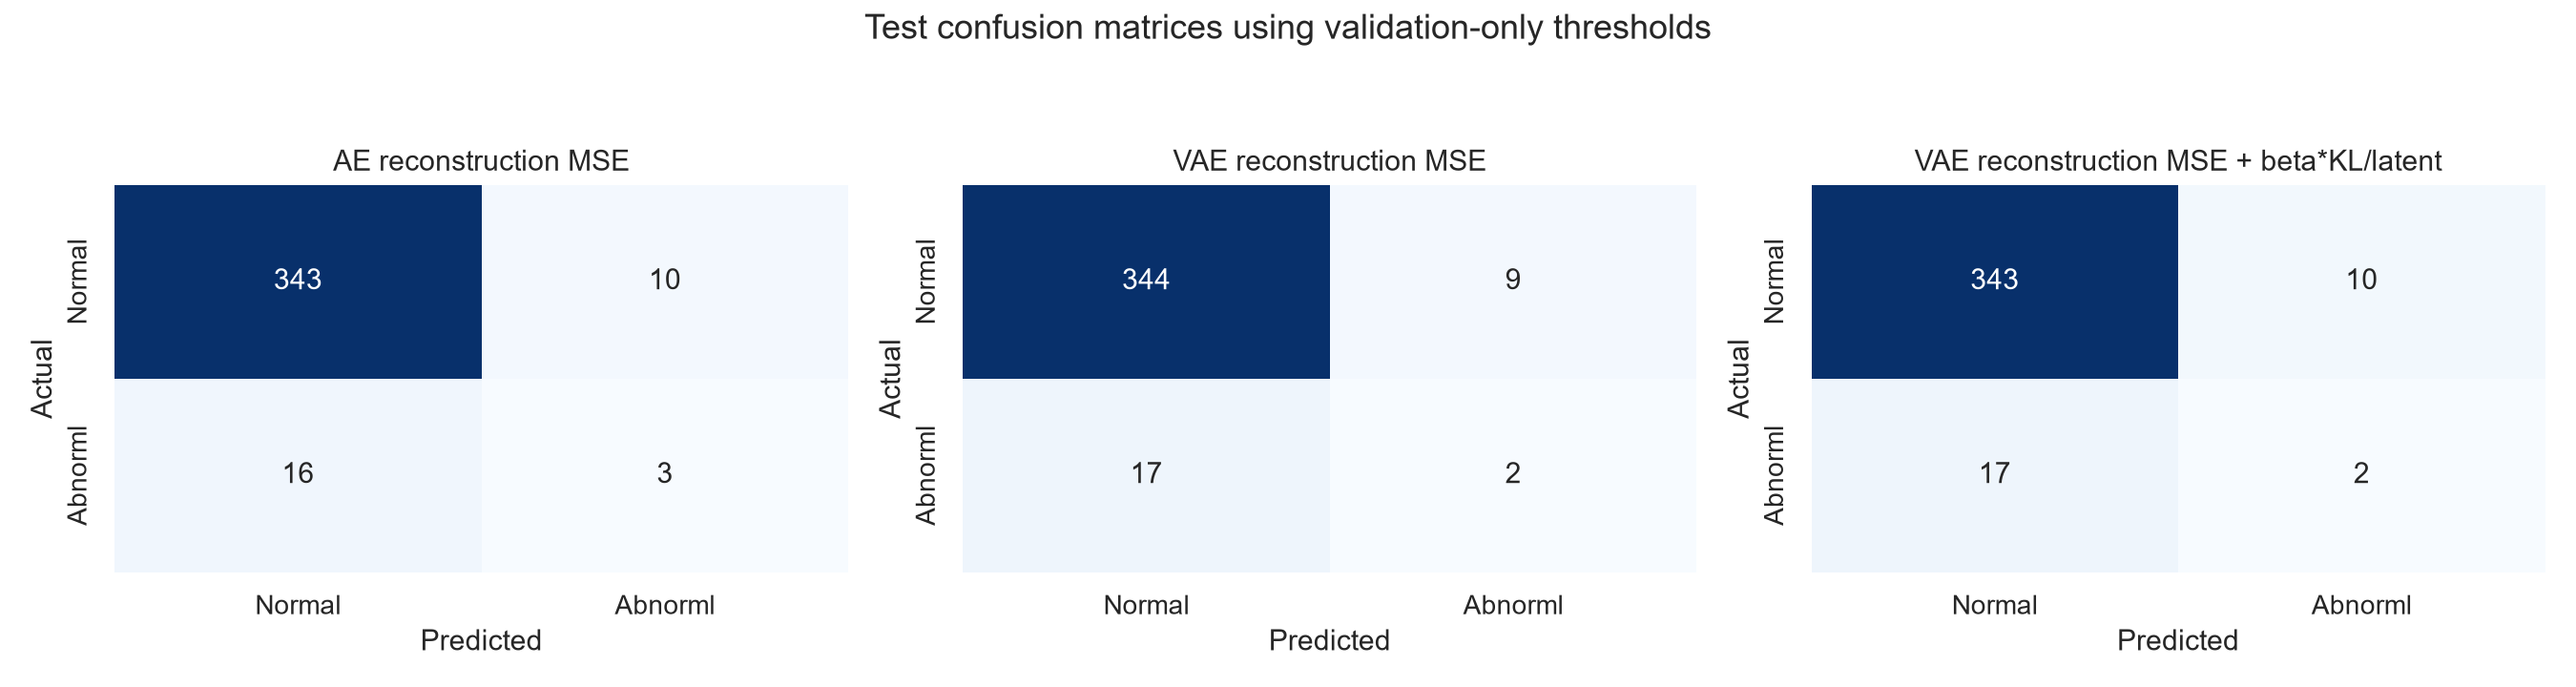

In [10]:
anomaly_metrics = pd.read_csv(RESULTS / "anomaly_metrics.csv")
anomaly_summary = pd.read_csv(RESULTS / "anomaly_score_summary.csv")
display(anomaly_metrics)
display(anomaly_summary)

show_images([
    ("Anomaly-score distributions by native Sale Condition", FIGURES / "anomaly" / "anomaly_score_distributions.png"),
    ("ROC and Precision–Recall curves", FIGURES / "anomaly" / "anomaly_roc_precision_recall.png"),
    ("Confusion matrices using validation-only thresholds", FIGURES / "anomaly" / "anomaly_confusion_matrices.png"),
])

## 11. Latent Space Analysis with t-SNE

Frozen test representations are extracted from AE z=128, AE z=64, the VAE
posterior mean, and the supervised MLP activation after its second ReLU. Each
latent matrix is standardized independently. t-SNE is then fitted separately
per model with random state 42, PCA initialization, automatic learning rate,
perplexity 30, and 1,000 iterations. The notebook loads the saved coordinates;
it does not refit t-SNE.

The MLP shows the clearest continuous SalePrice and Overall Qual gradients,
consistent with its supervised target. AE z=64 also displays a price/quality
progression even though SalePrice was not used in AE training. Neighborhood
colors form local patches but remain broadly mixed.

,Representation,Latent shape,t-SNE shape
0,AE z=128,"(440, 128)","(440, 2)"
1,AE z=64,"(440, 64)","(440, 2)"
2,VAE z=64 beta=0.5,"(440, 64)","(440, 2)"
3,MLP z=64,"(440, 64)","(440, 2)"


,random_state,init,learning_rate,perplexity,max_iter,fit_separately_per_model
0,42,pca,auto,30,1000,True


**t-SNE colored by SalePrice**

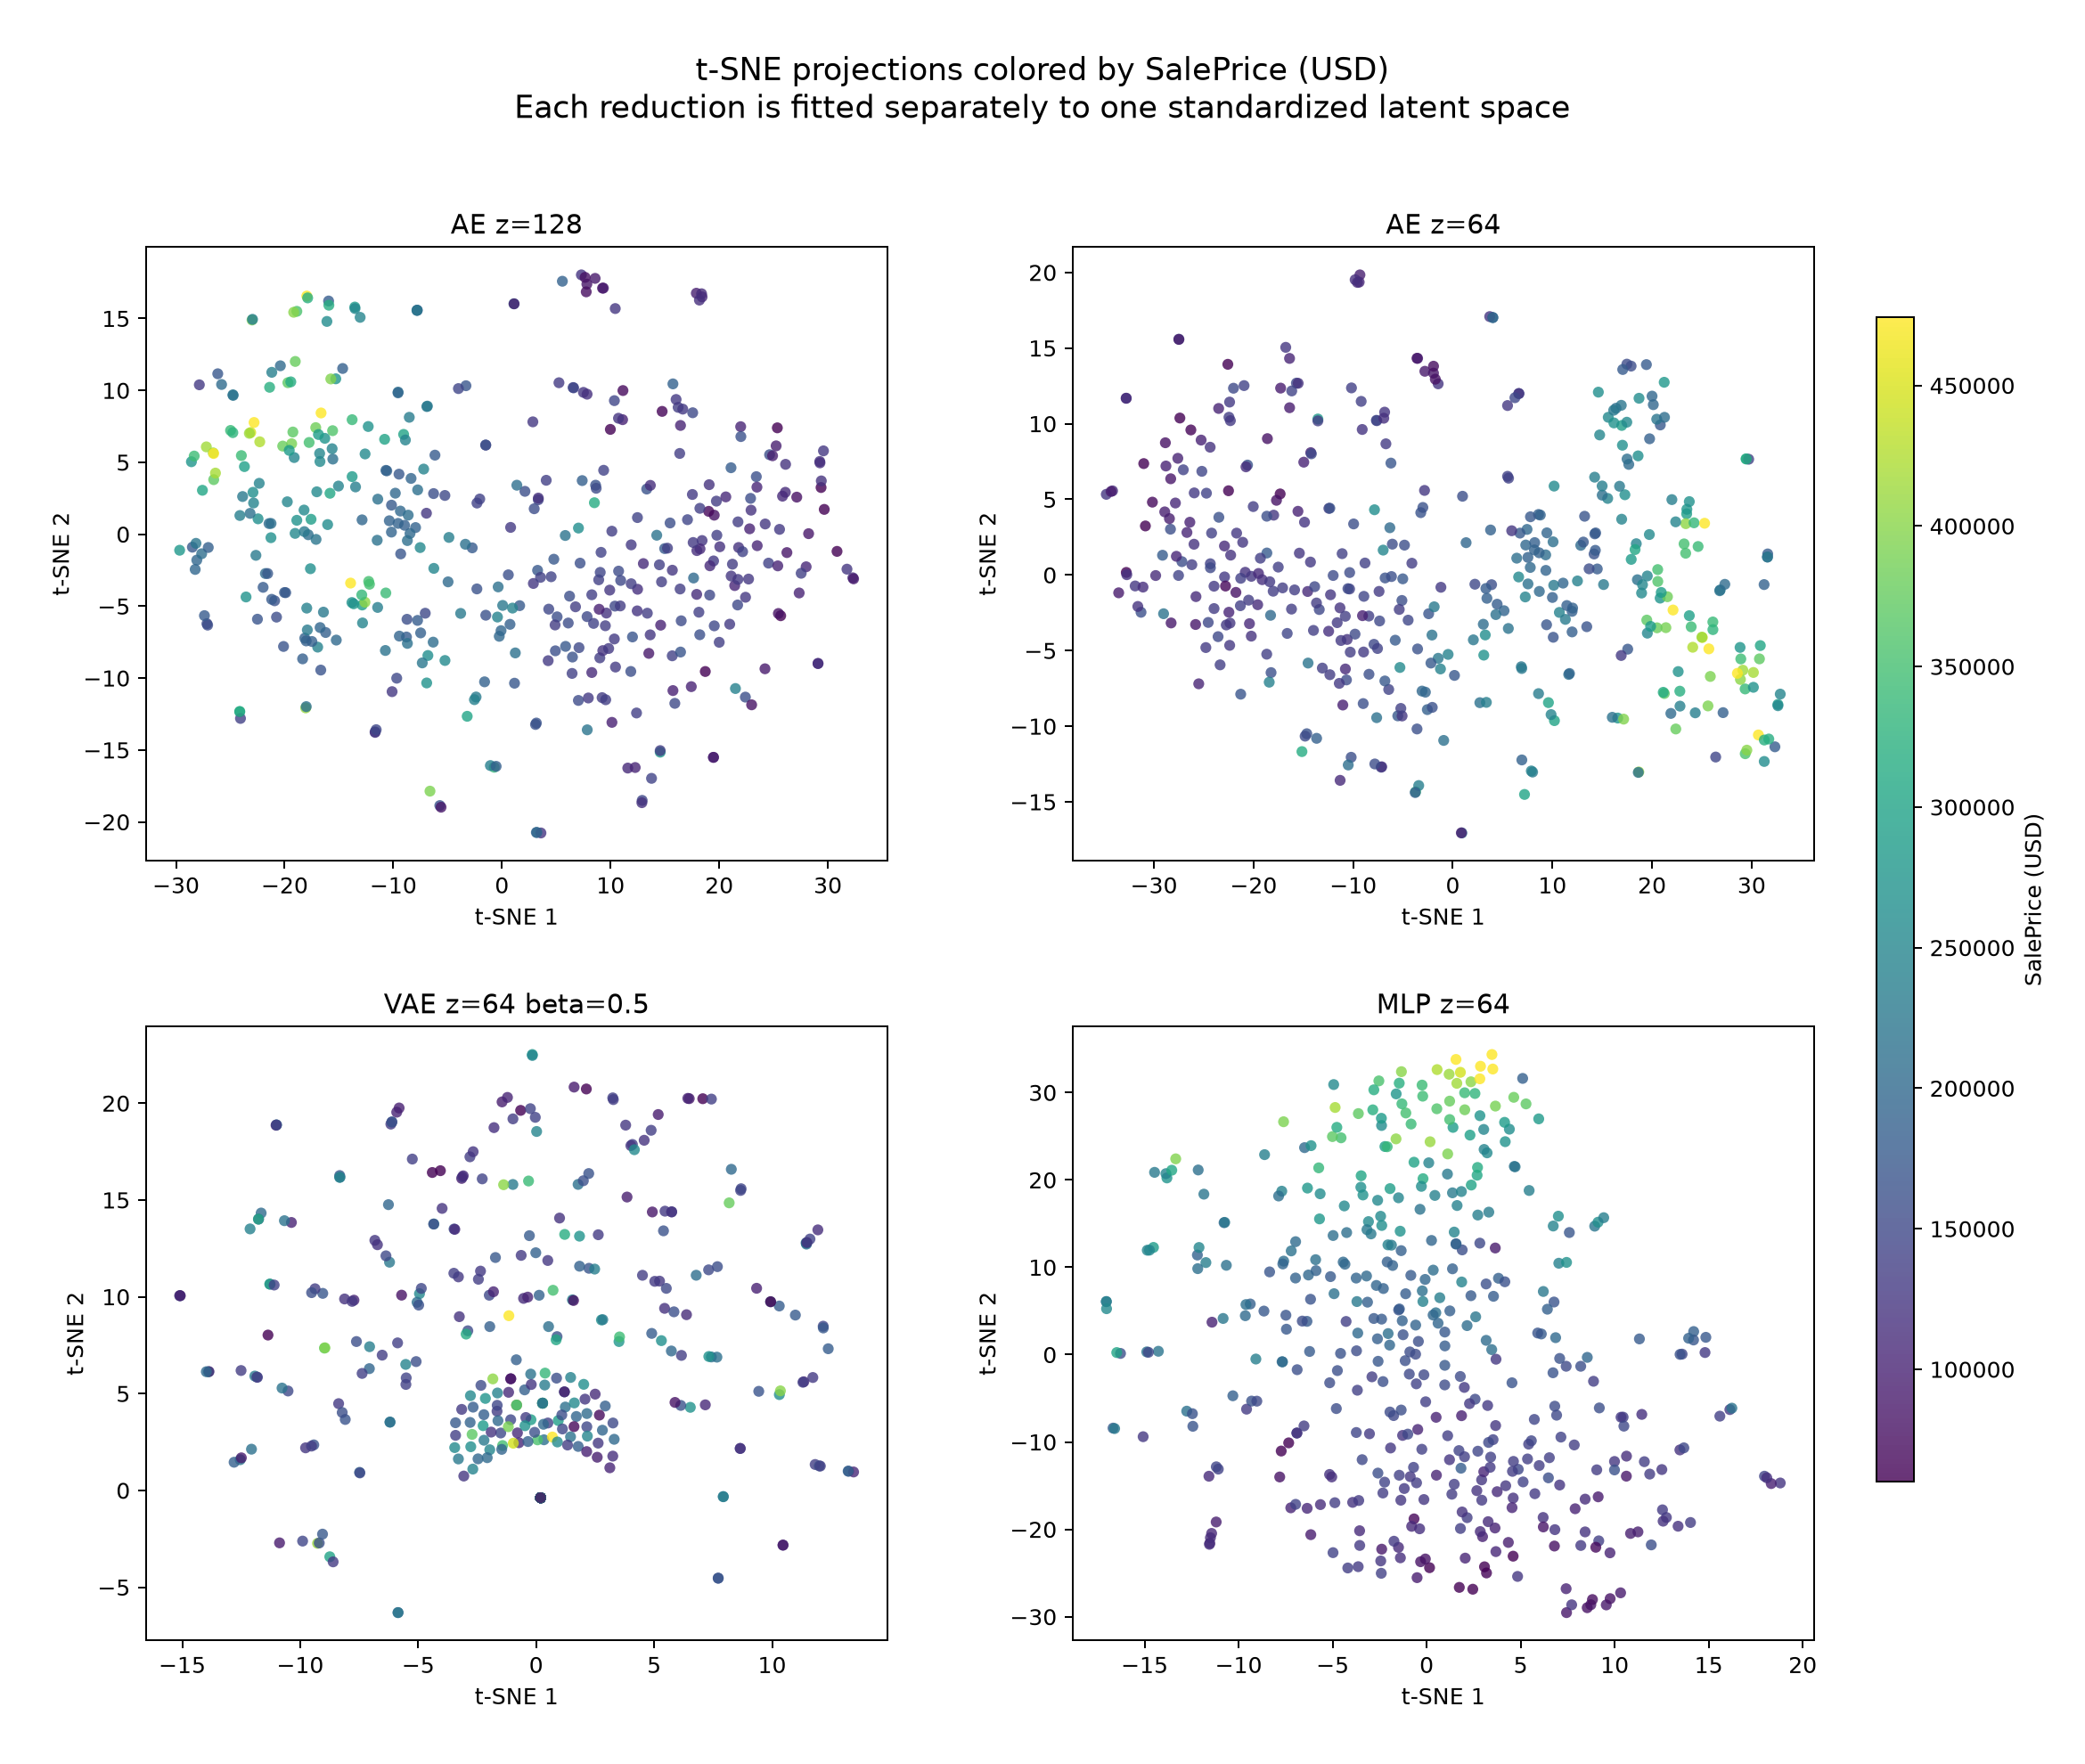

**t-SNE colored by Overall Qual**

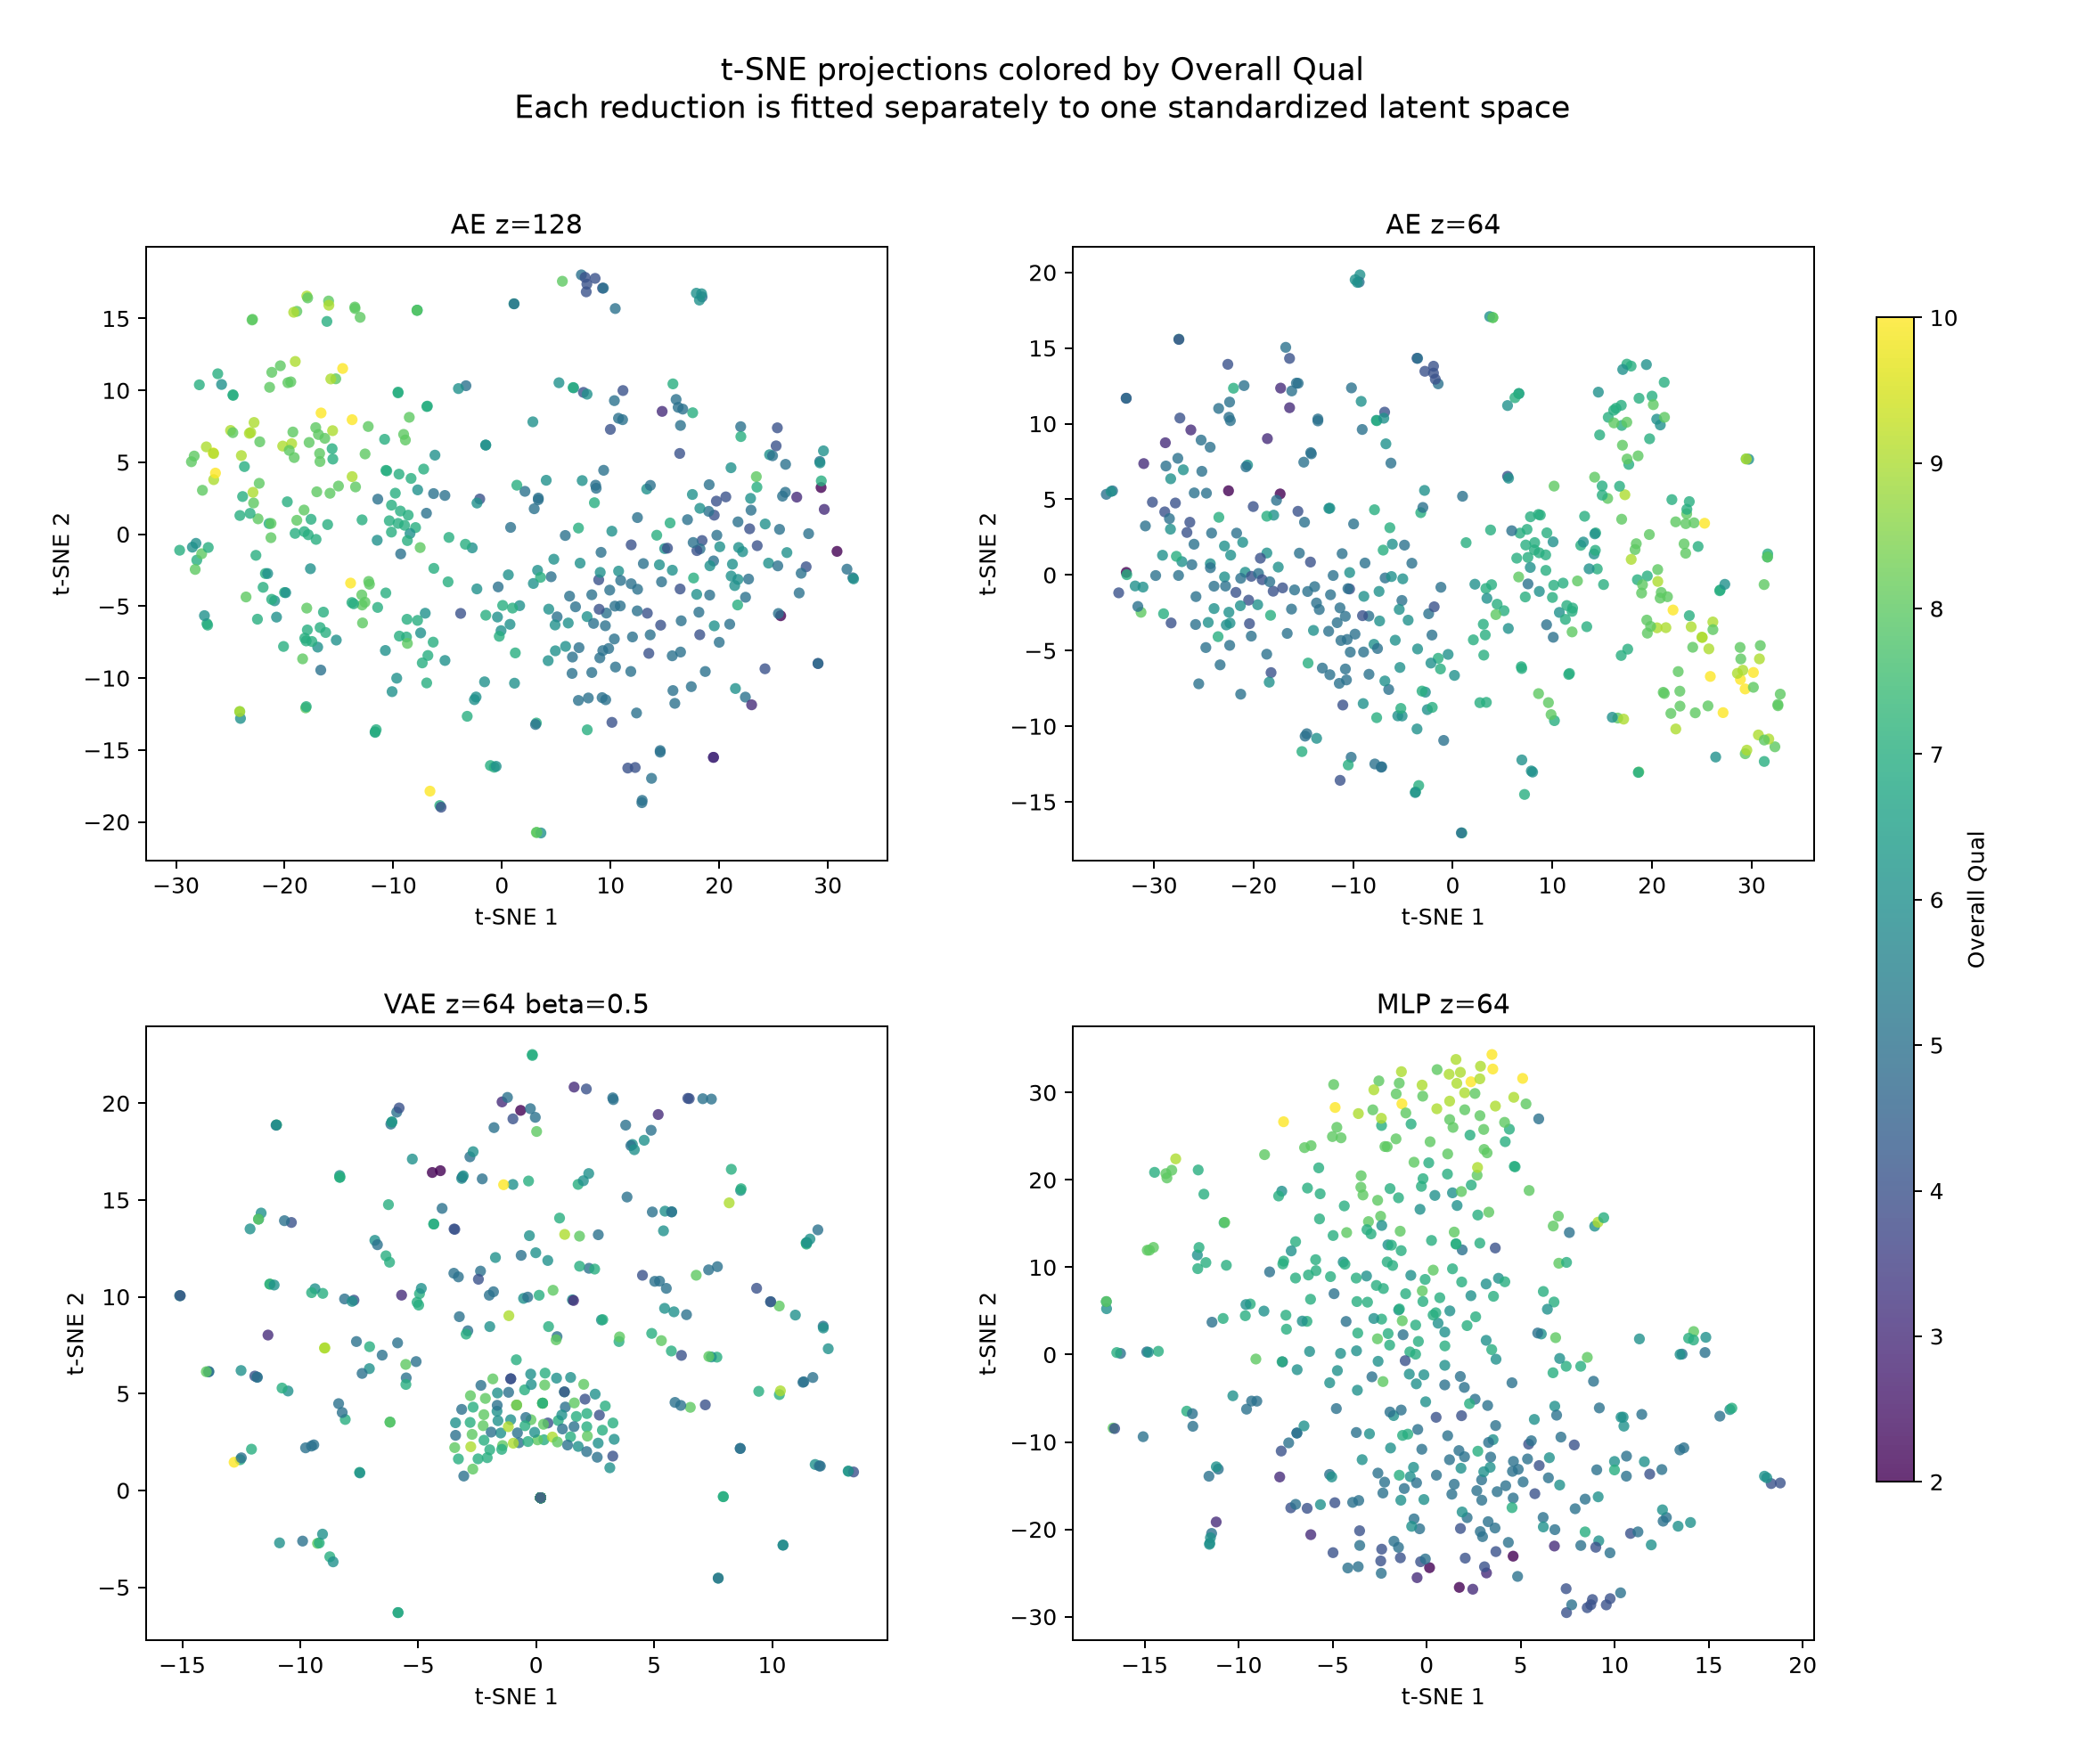

**t-SNE colored by Neighborhood**

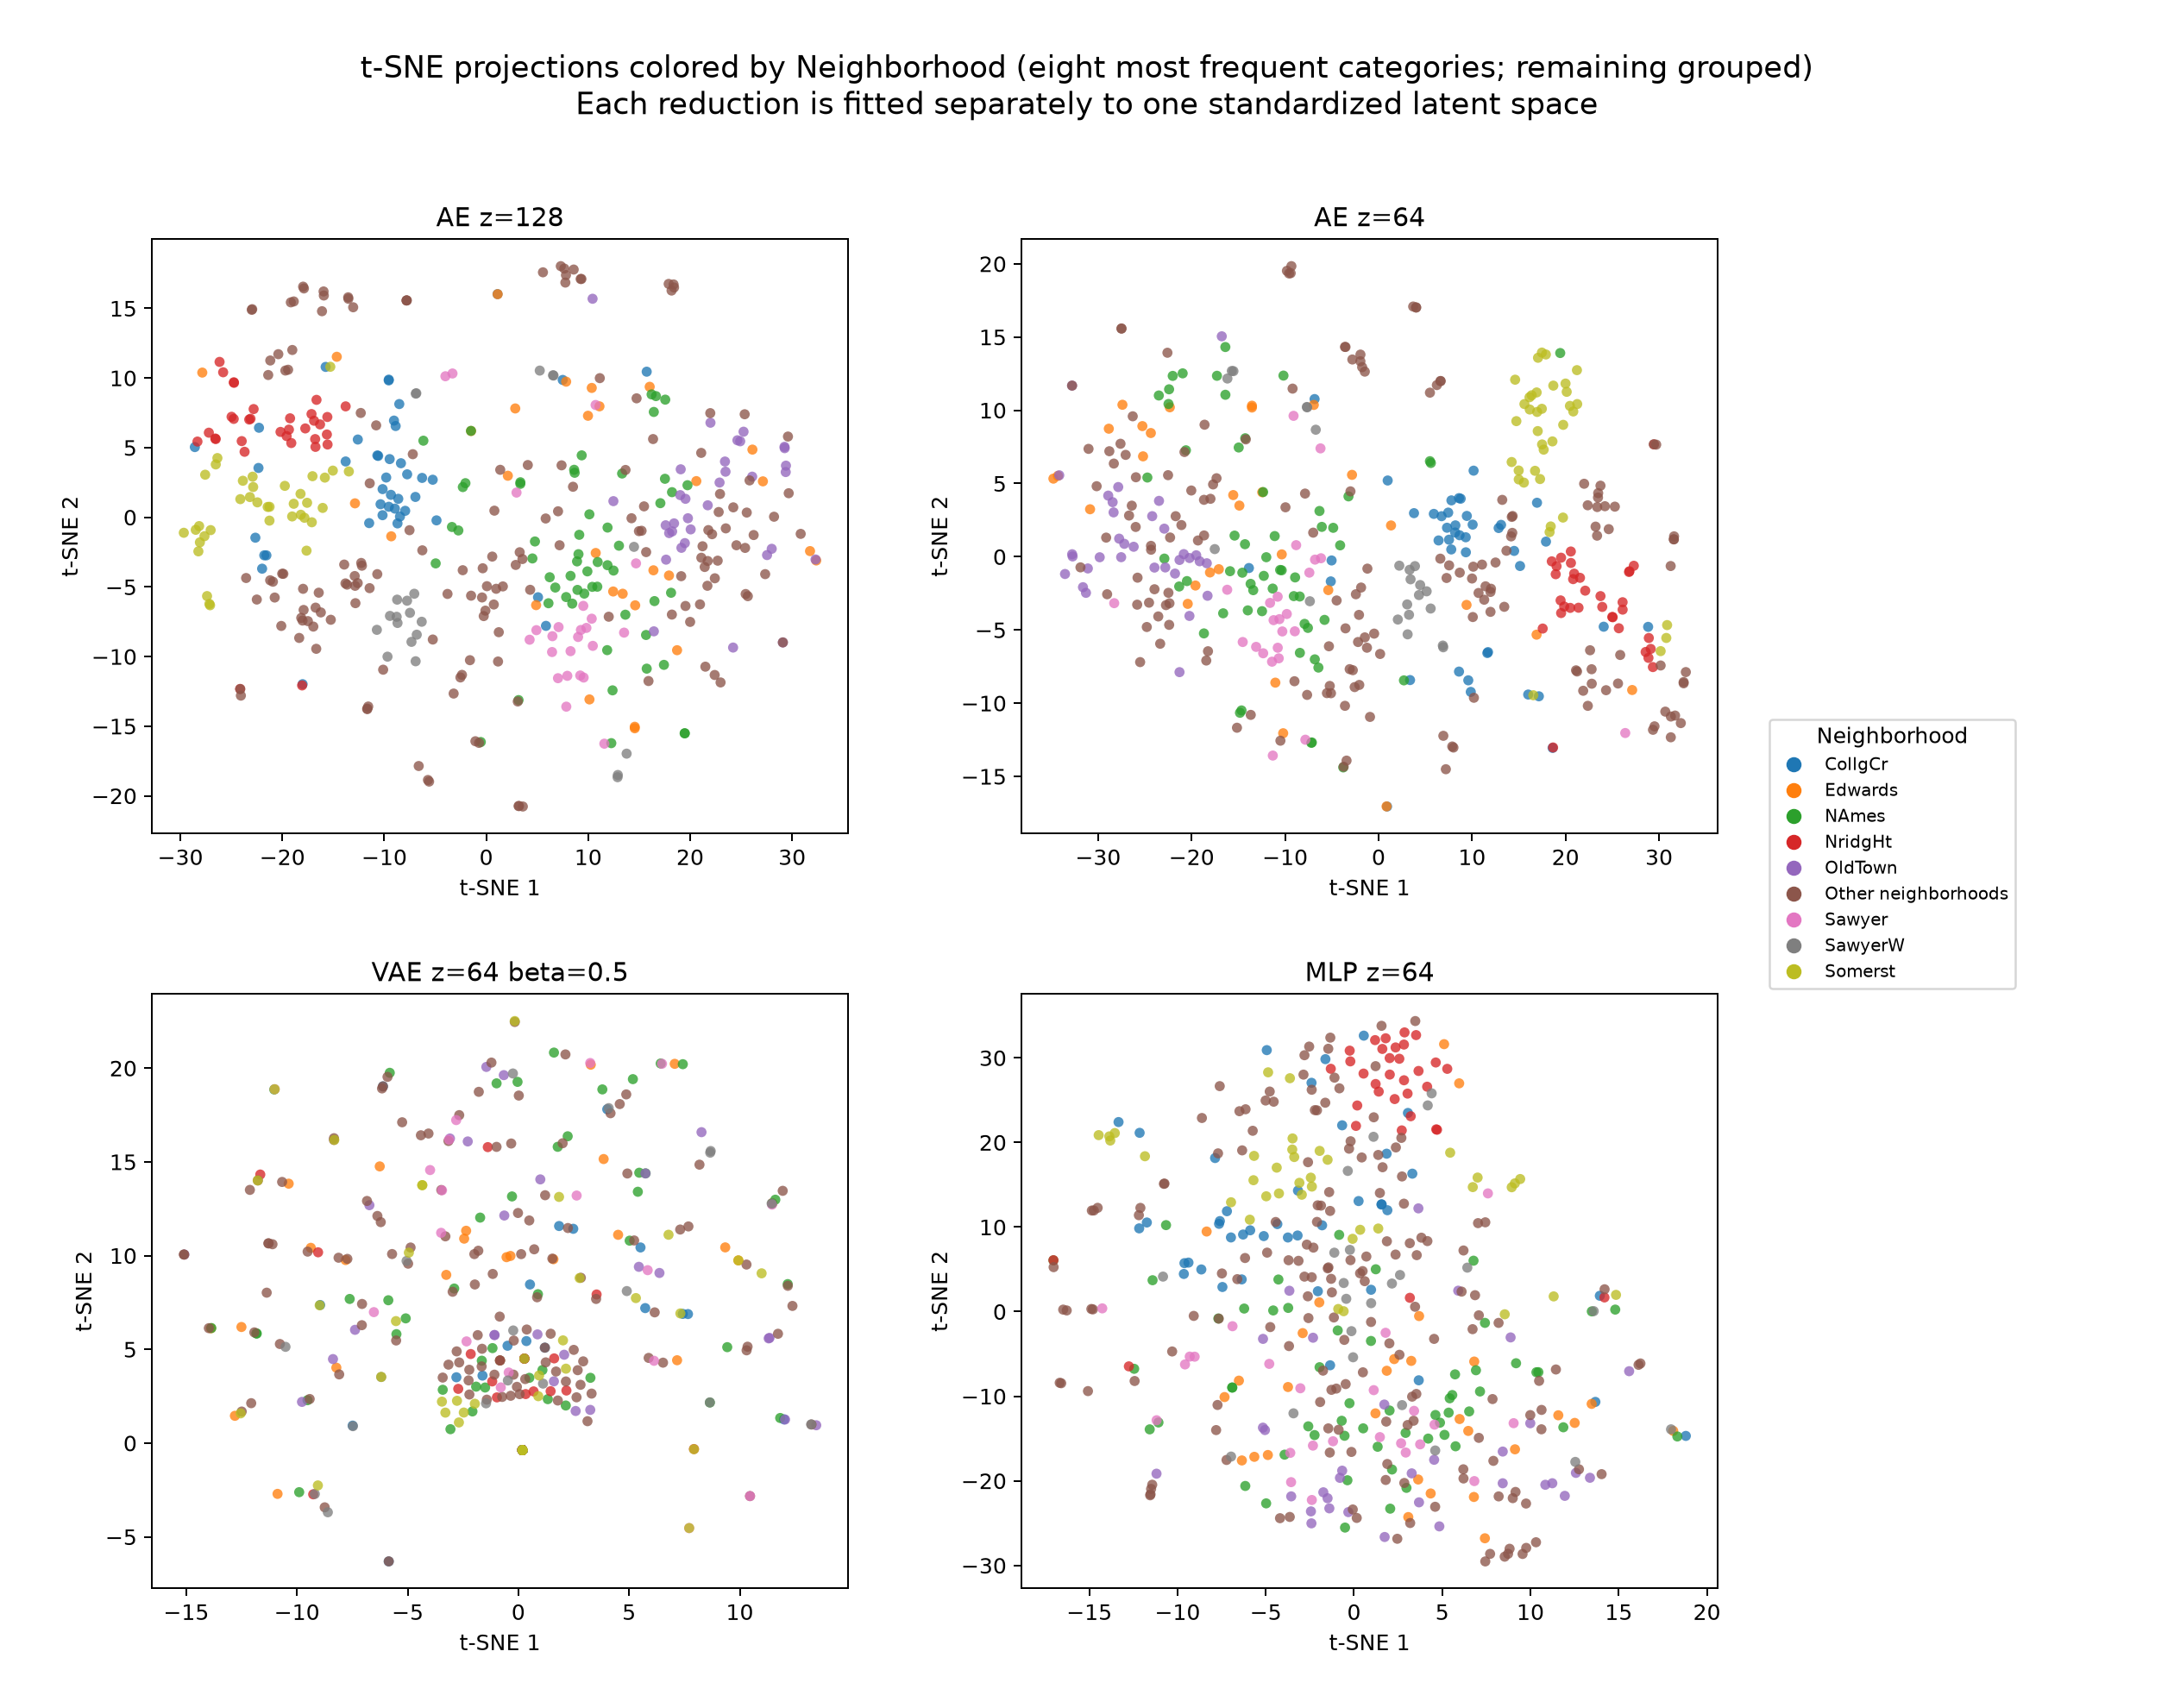

**t-SNE colored by Sale Condition**

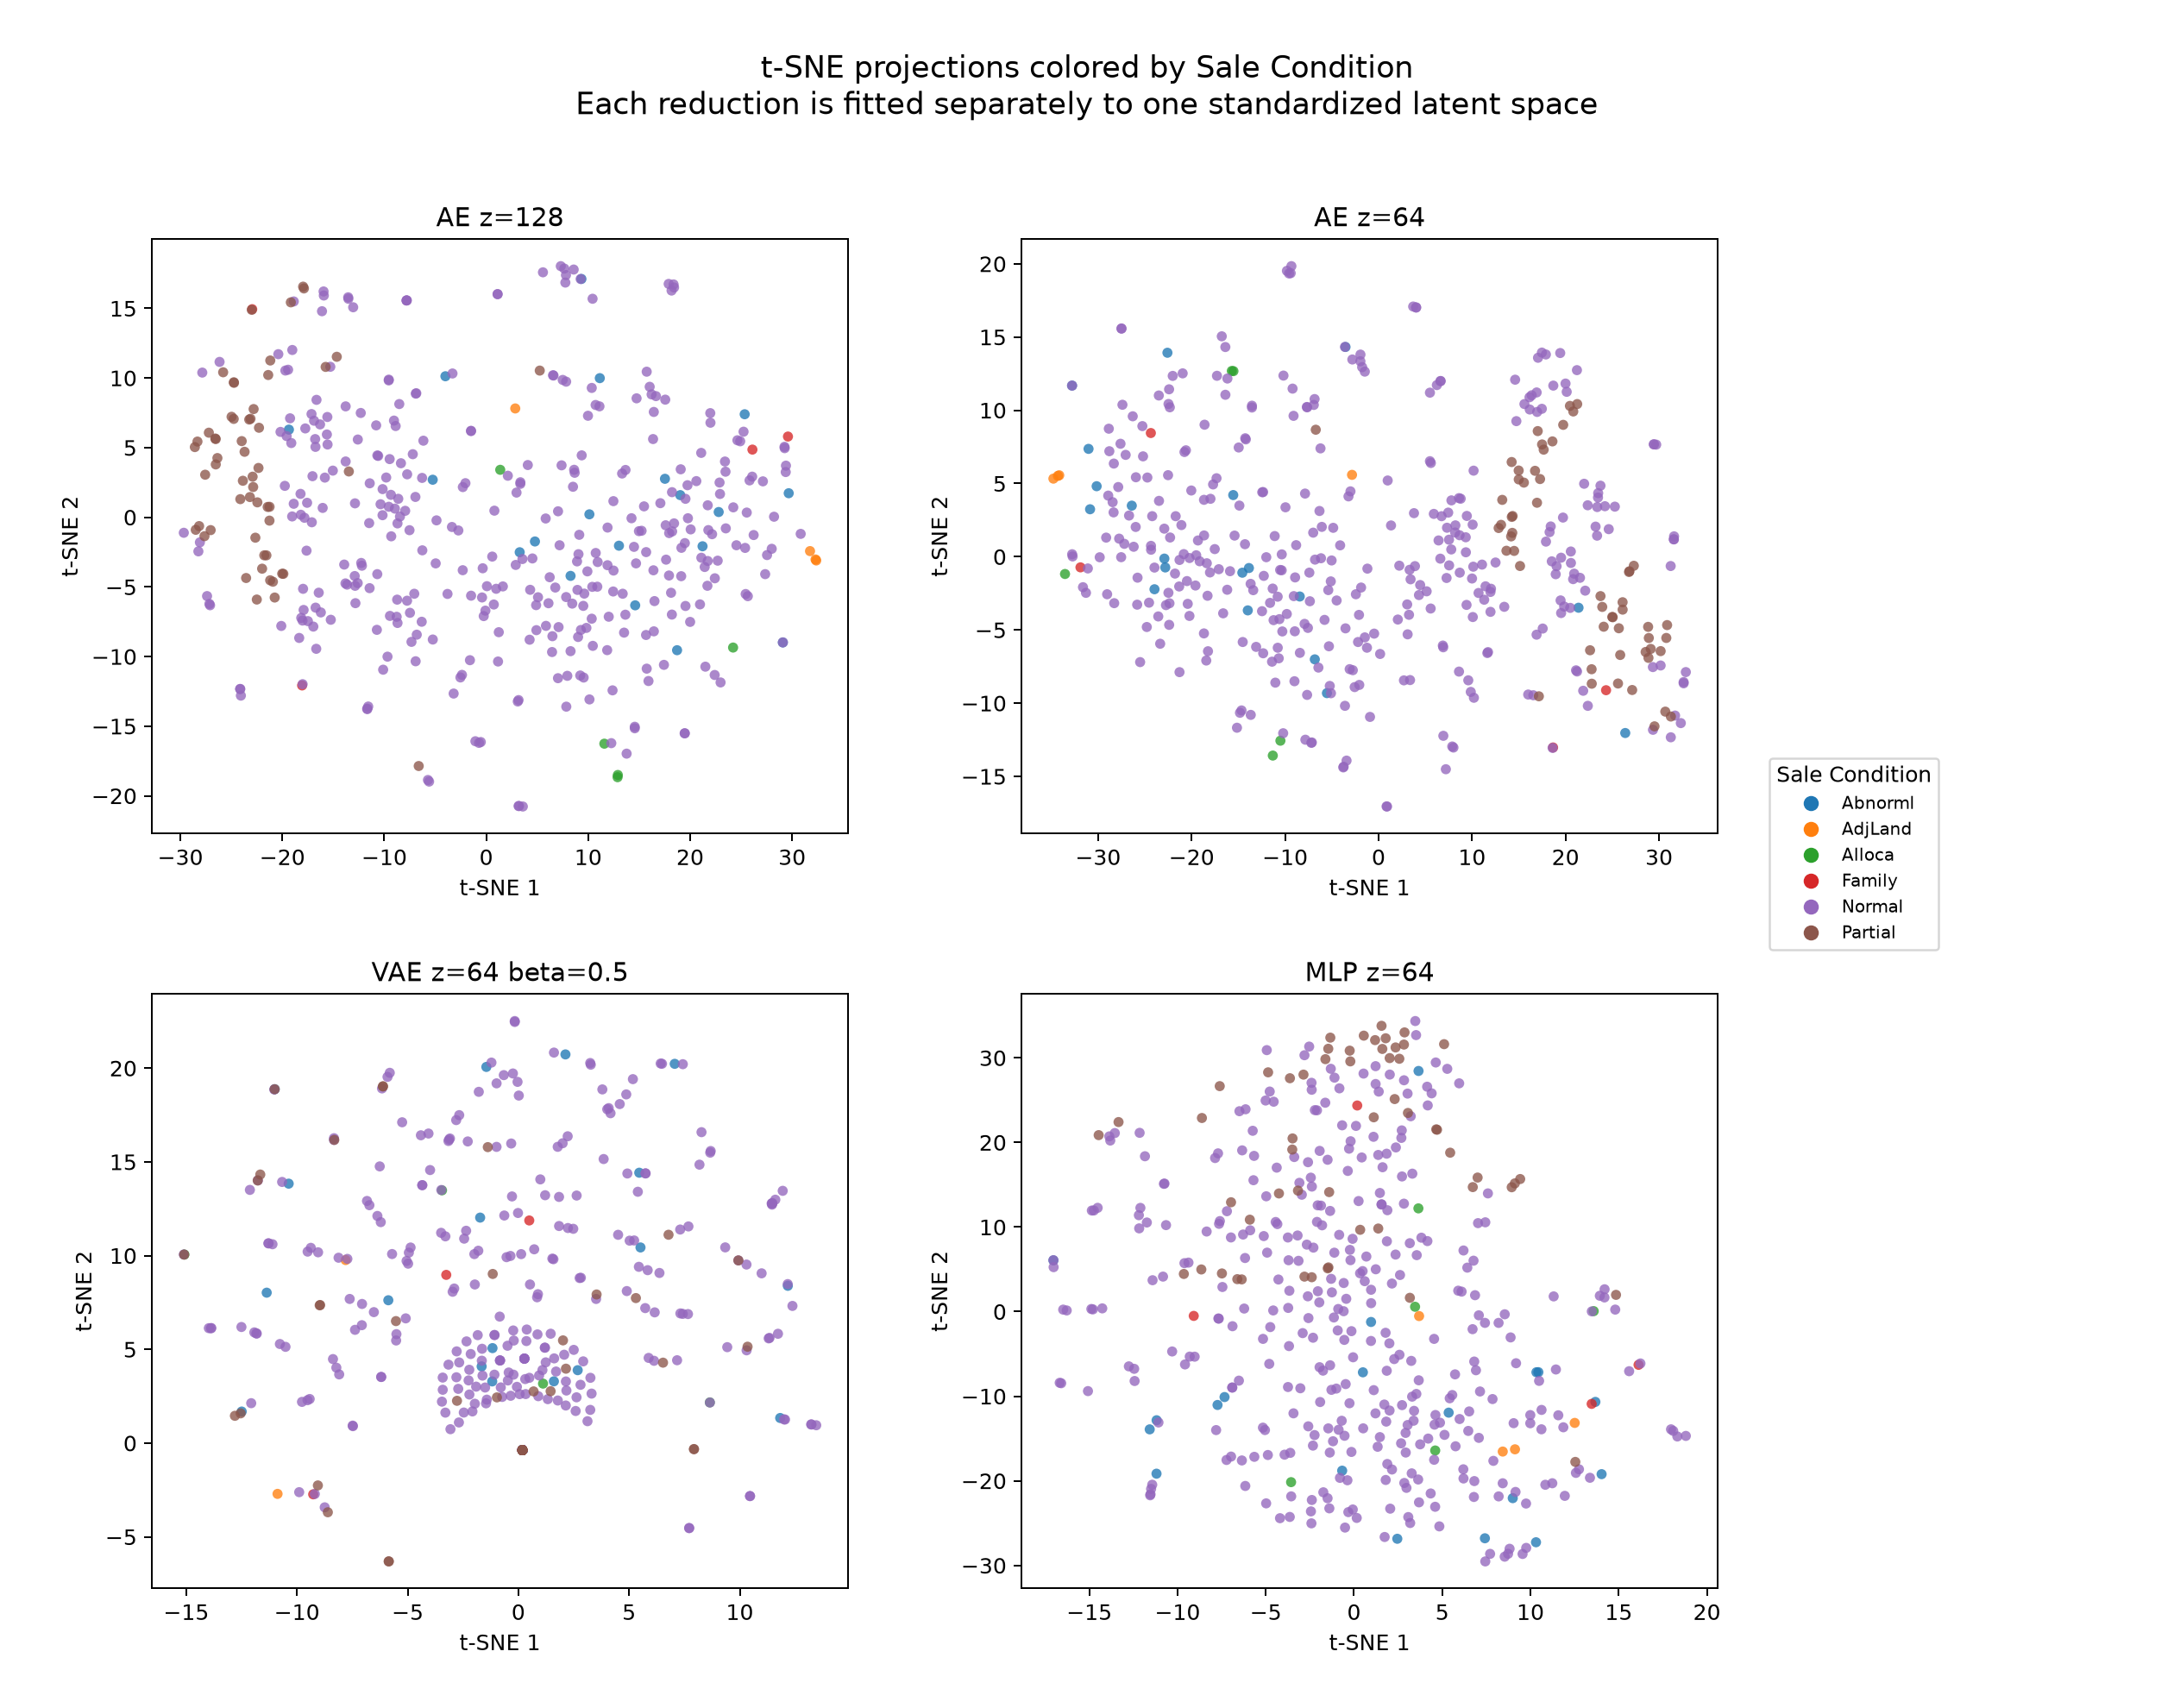

In [11]:
latent_metadata = read_json(RESULTS / "latent_embedding_metadata.json")
with np.load(RESULTS / "latent_representations.npz") as archive:
    latent_shapes = {name: archive[name].shape for name in ["AE z=128", "AE z=64", "VAE z=64 beta=0.5", "MLP z=64"]}
with np.load(RESULTS / "latent_tsne_embeddings.npz") as archive:
    tsne_shapes = {name: archive[name].shape for name in latent_shapes}

display(pd.DataFrame({"Representation": latent_shapes.keys(), "Latent shape": latent_shapes.values(), "t-SNE shape": tsne_shapes.values()}))
display(pd.DataFrame([latent_metadata["tsne"]]))

show_images([
    ("t-SNE colored by SalePrice", FIGURES / "latent" / "tsne_saleprice.png"),
    ("t-SNE colored by Overall Qual", FIGURES / "latent" / "tsne_overall_quality.png"),
    ("t-SNE colored by Neighborhood", FIGURES / "latent" / "tsne_neighborhood.png"),
    ("t-SNE colored by Sale Condition", FIGURES / "latent" / "tsne_sale_condition.png"),
])

## 12. Latent Space Analysis with UMAP

UMAP uses 15 neighbors, minimum distance 0.1, Euclidean distance, random state
42, and one execution thread. Like t-SNE, it is fitted separately to each
standardized latent space. The saved UMAP panels reinforce the supervised MLP
price gradient and show more locally continuous AE manifolds. The VAE forms a
compact concentration with separated branches and weaker price/quality
organization. Axes, rotations, scale, and inter-cluster distances are not
comparable across separately fitted panels.

,Representation,UMAP shape
0,AE z=128,"(440, 2)"
1,AE z=64,"(440, 2)"
2,VAE z=64 beta=0.5,"(440, 2)"
3,MLP z=64,"(440, 2)"


,n_neighbors,min_dist,metric,random_state,n_jobs,fit_separately_per_model
0,15,0.100000,euclidean,42,1,True


**UMAP colored by SalePrice**

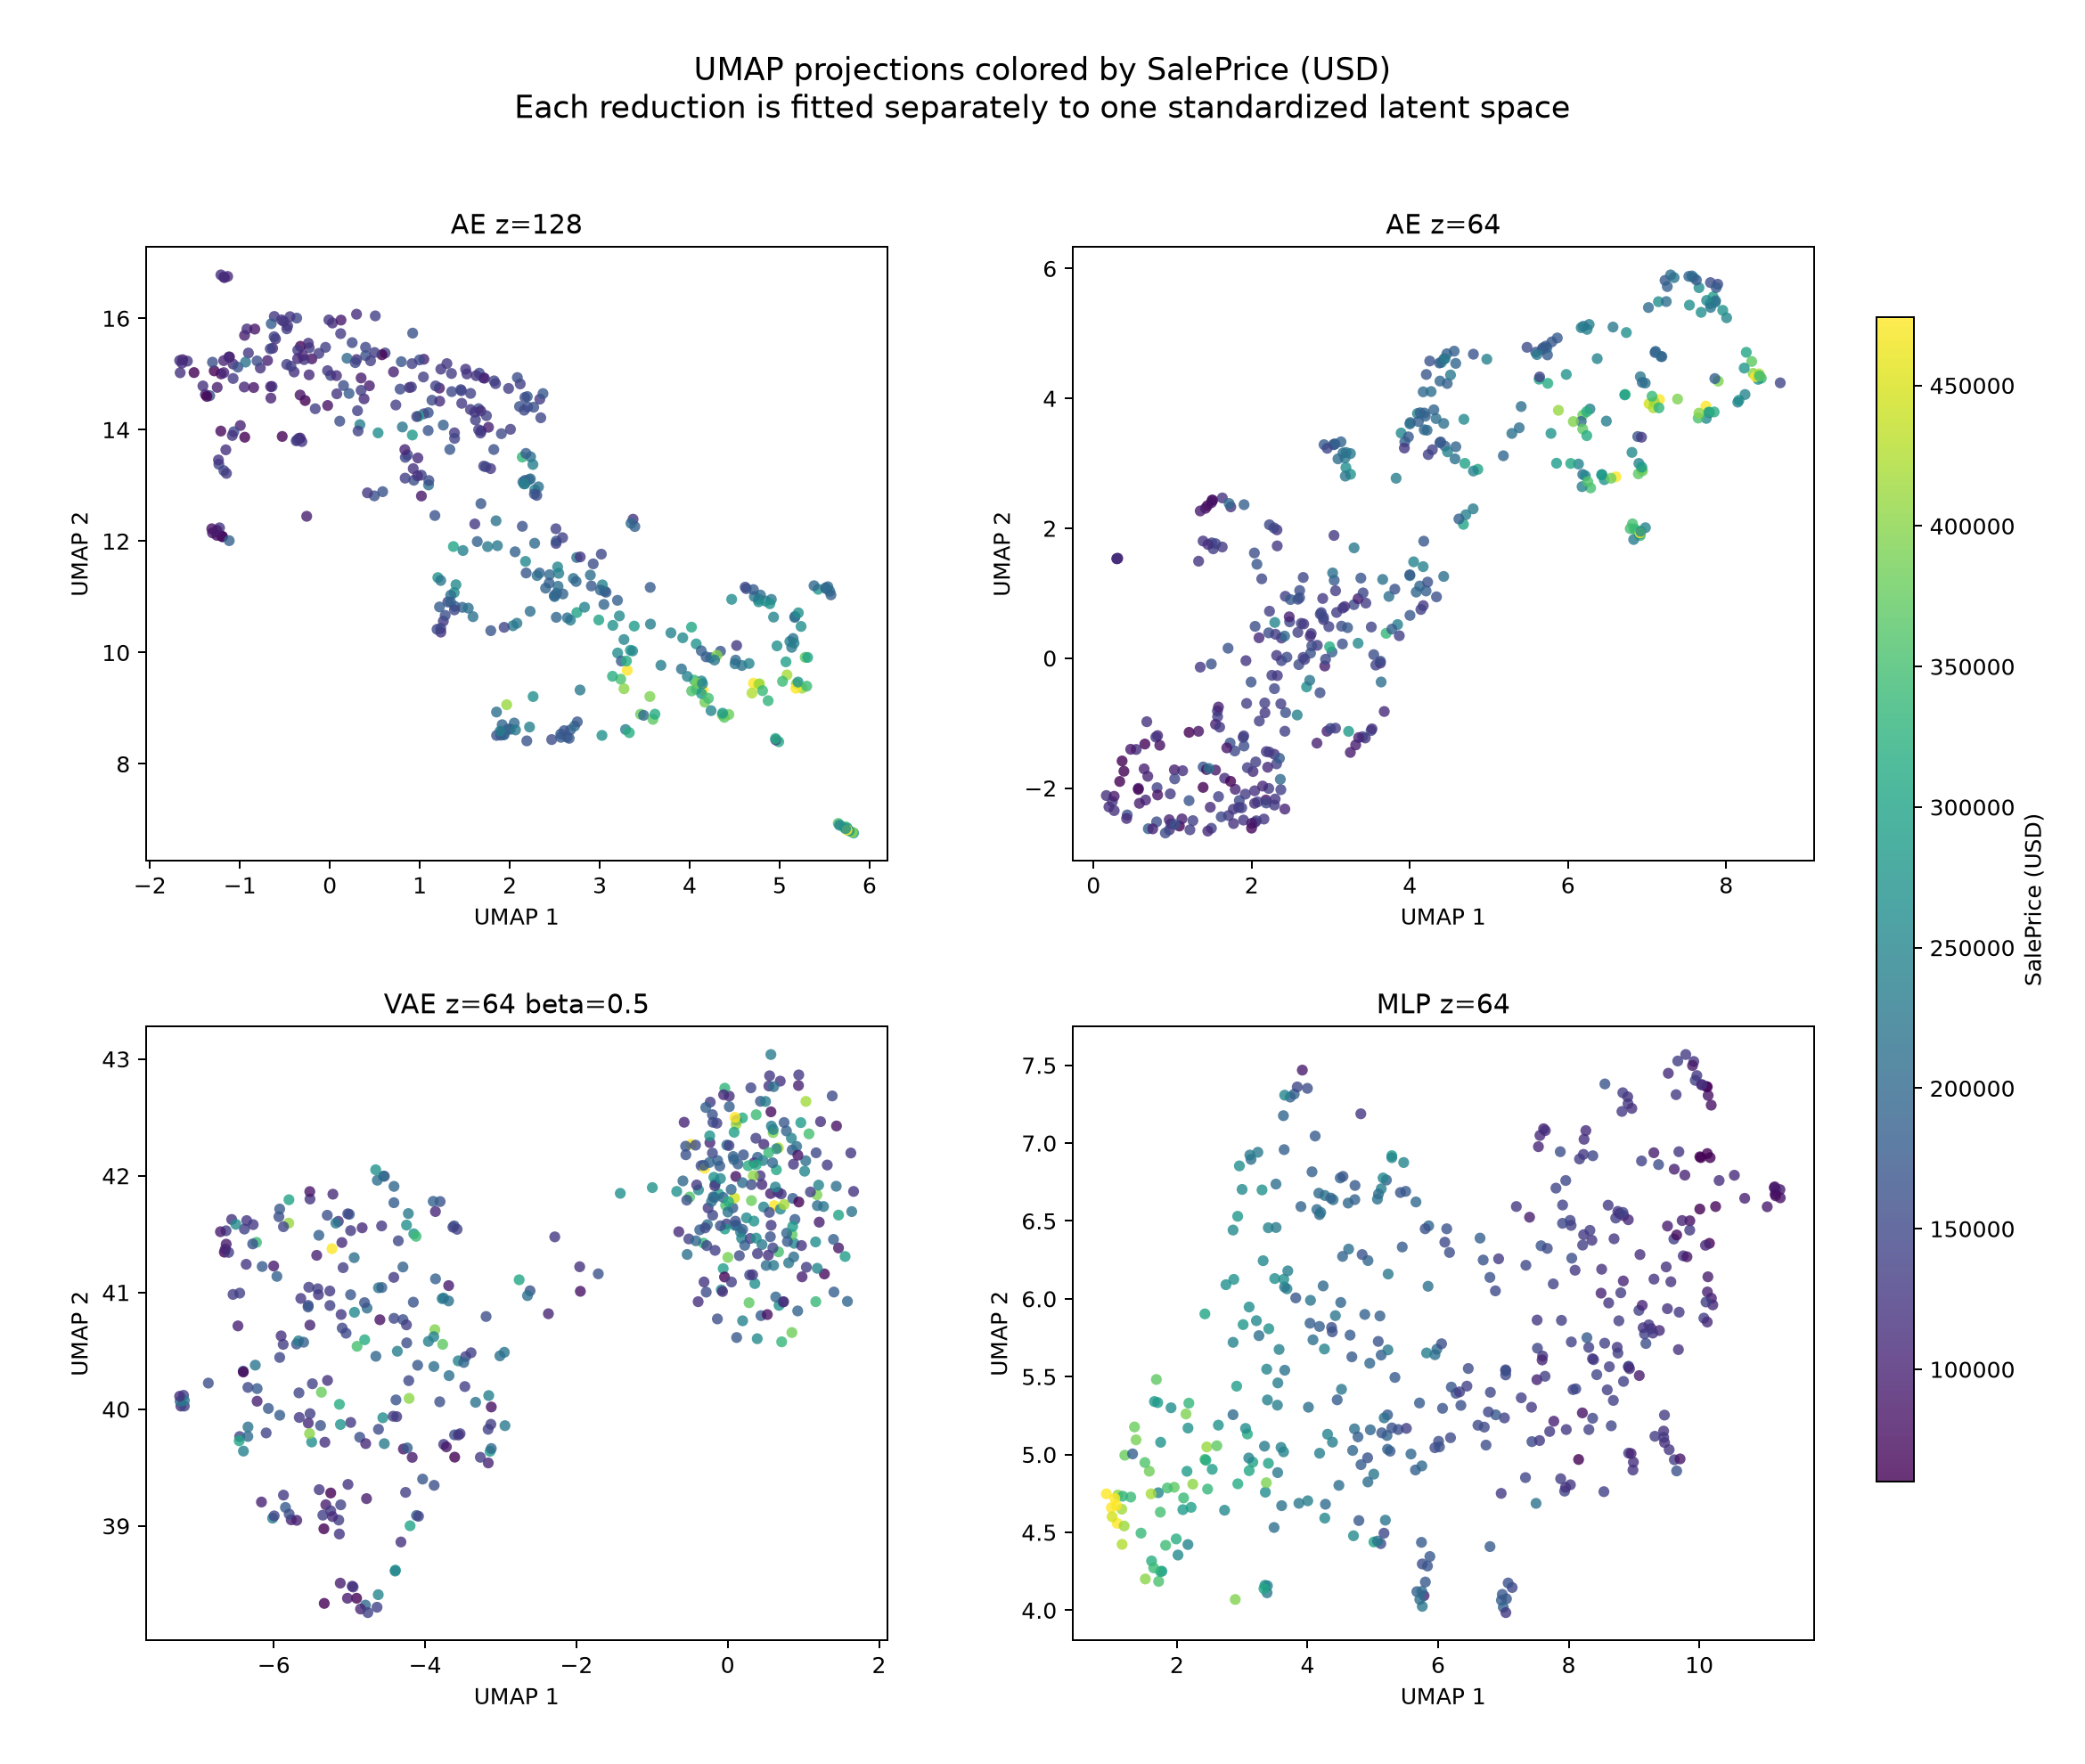

**UMAP colored by Overall Qual**

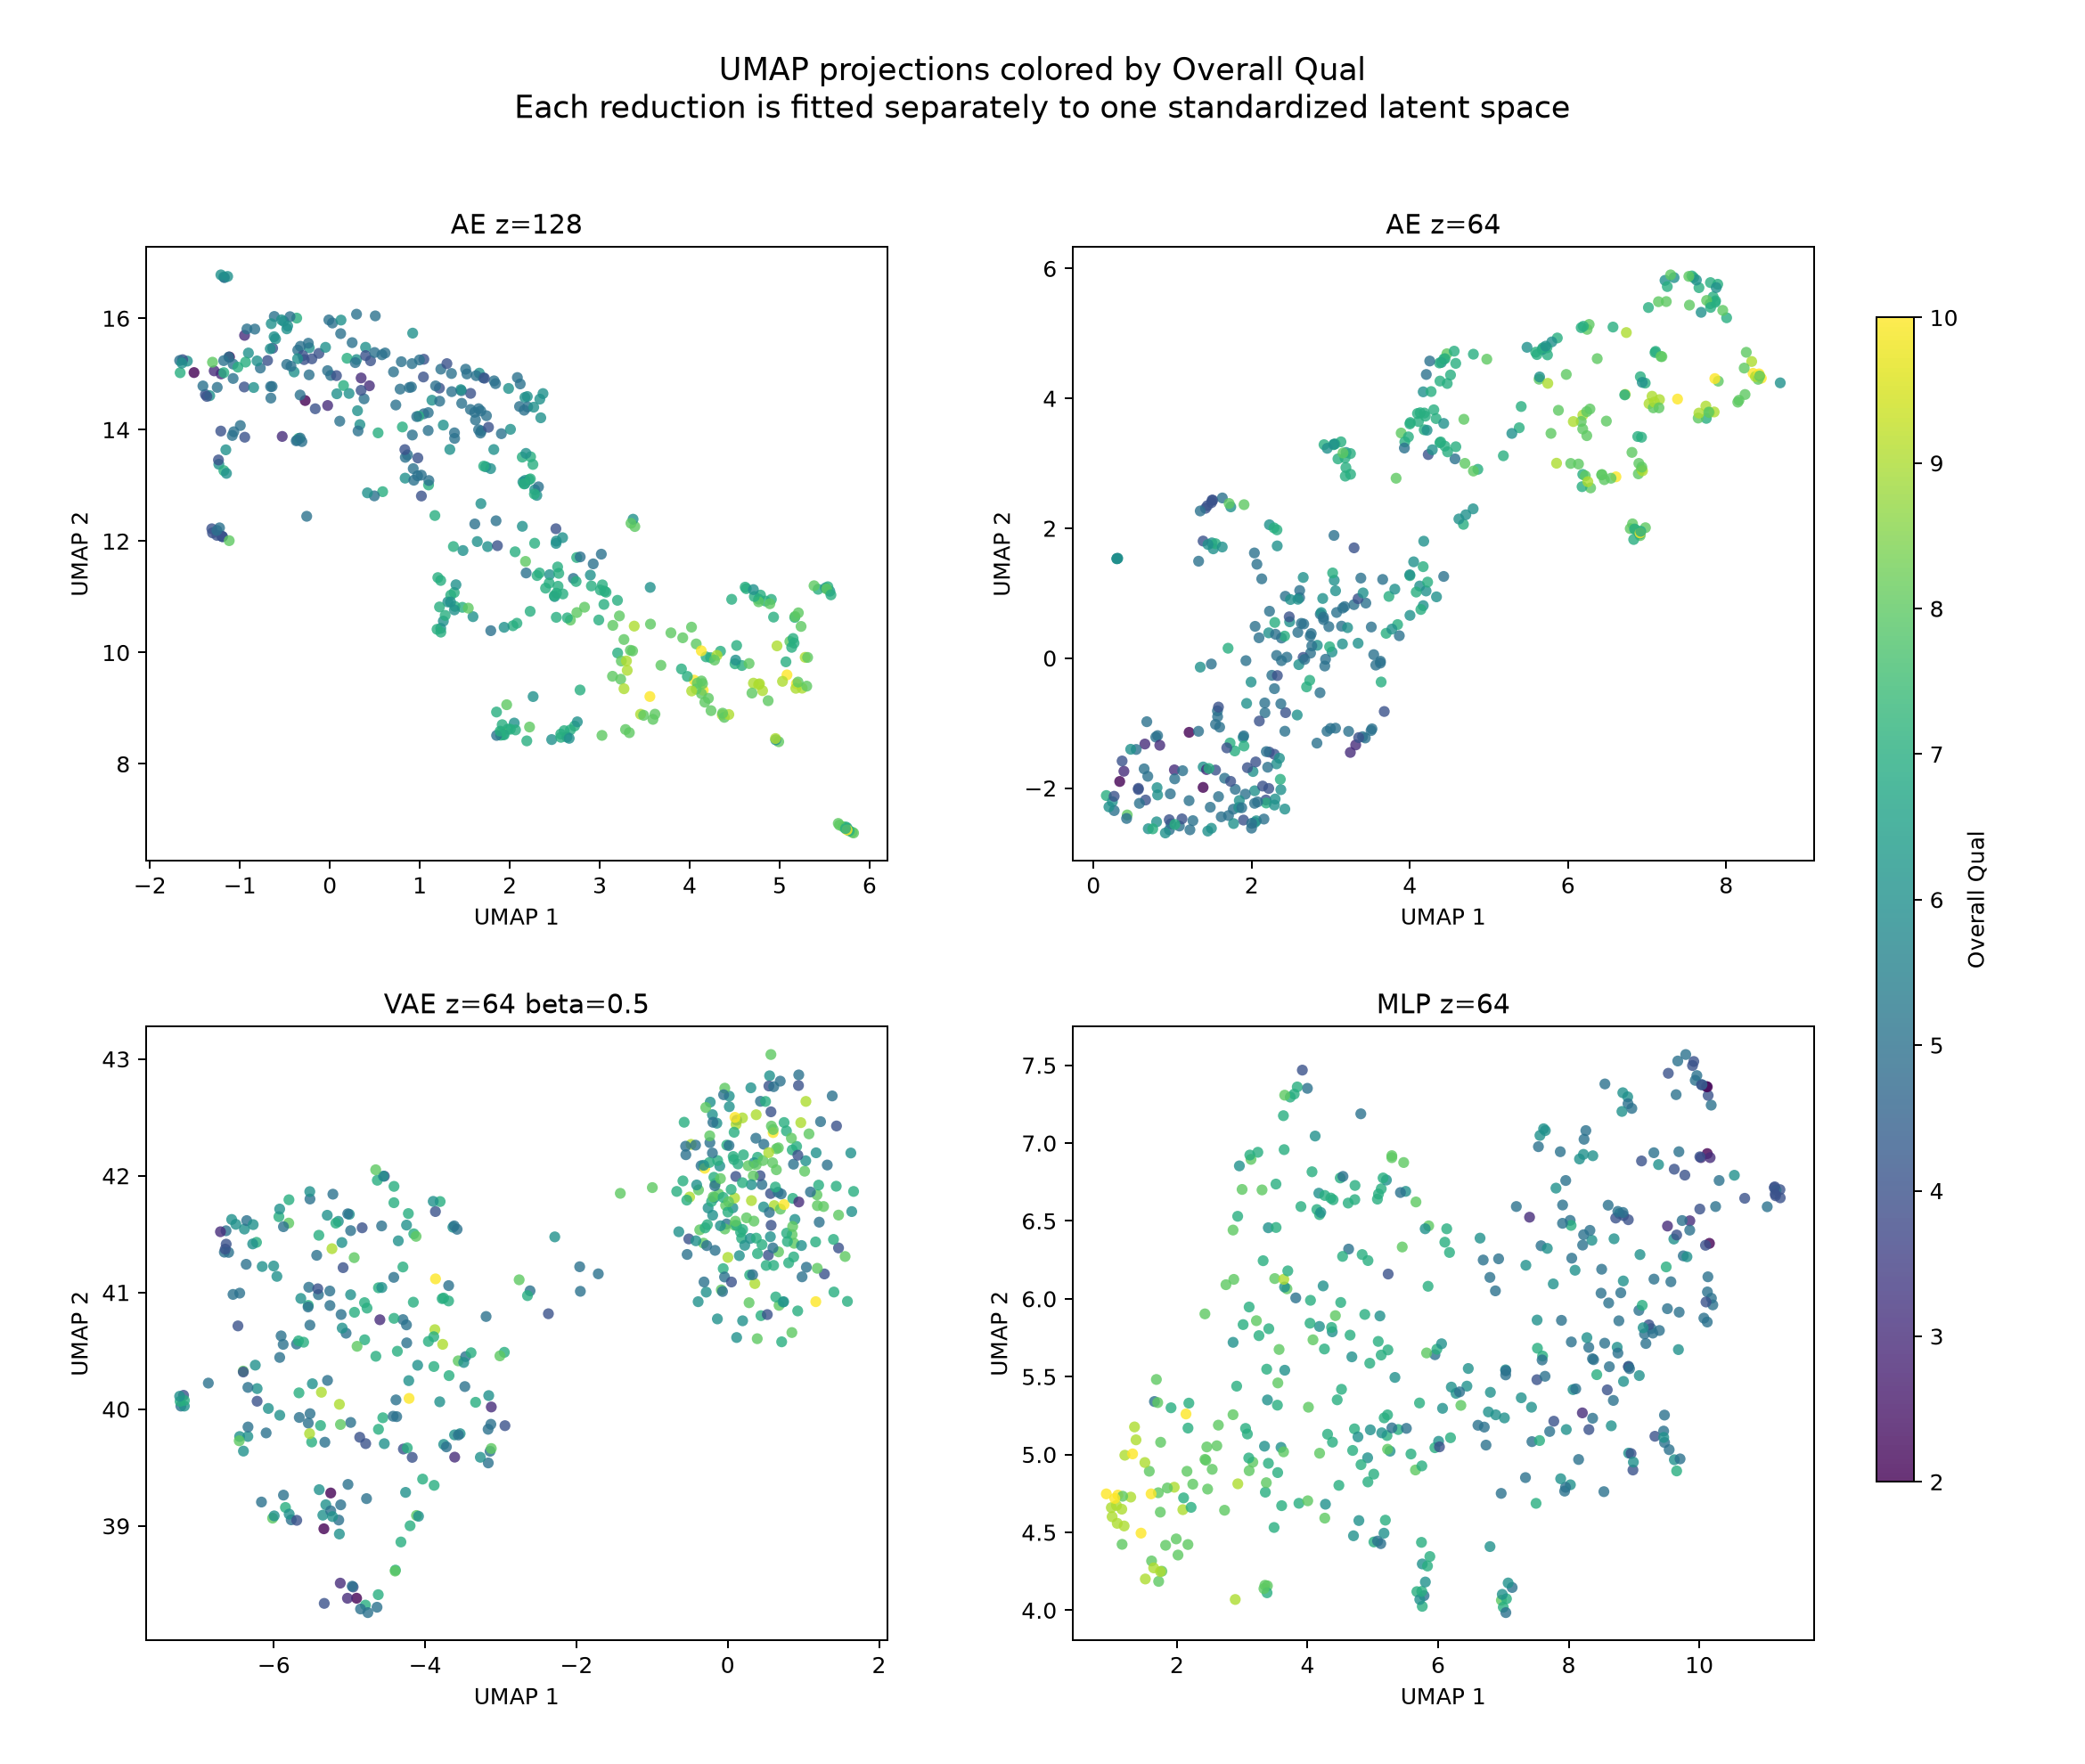

**UMAP colored by Neighborhood**

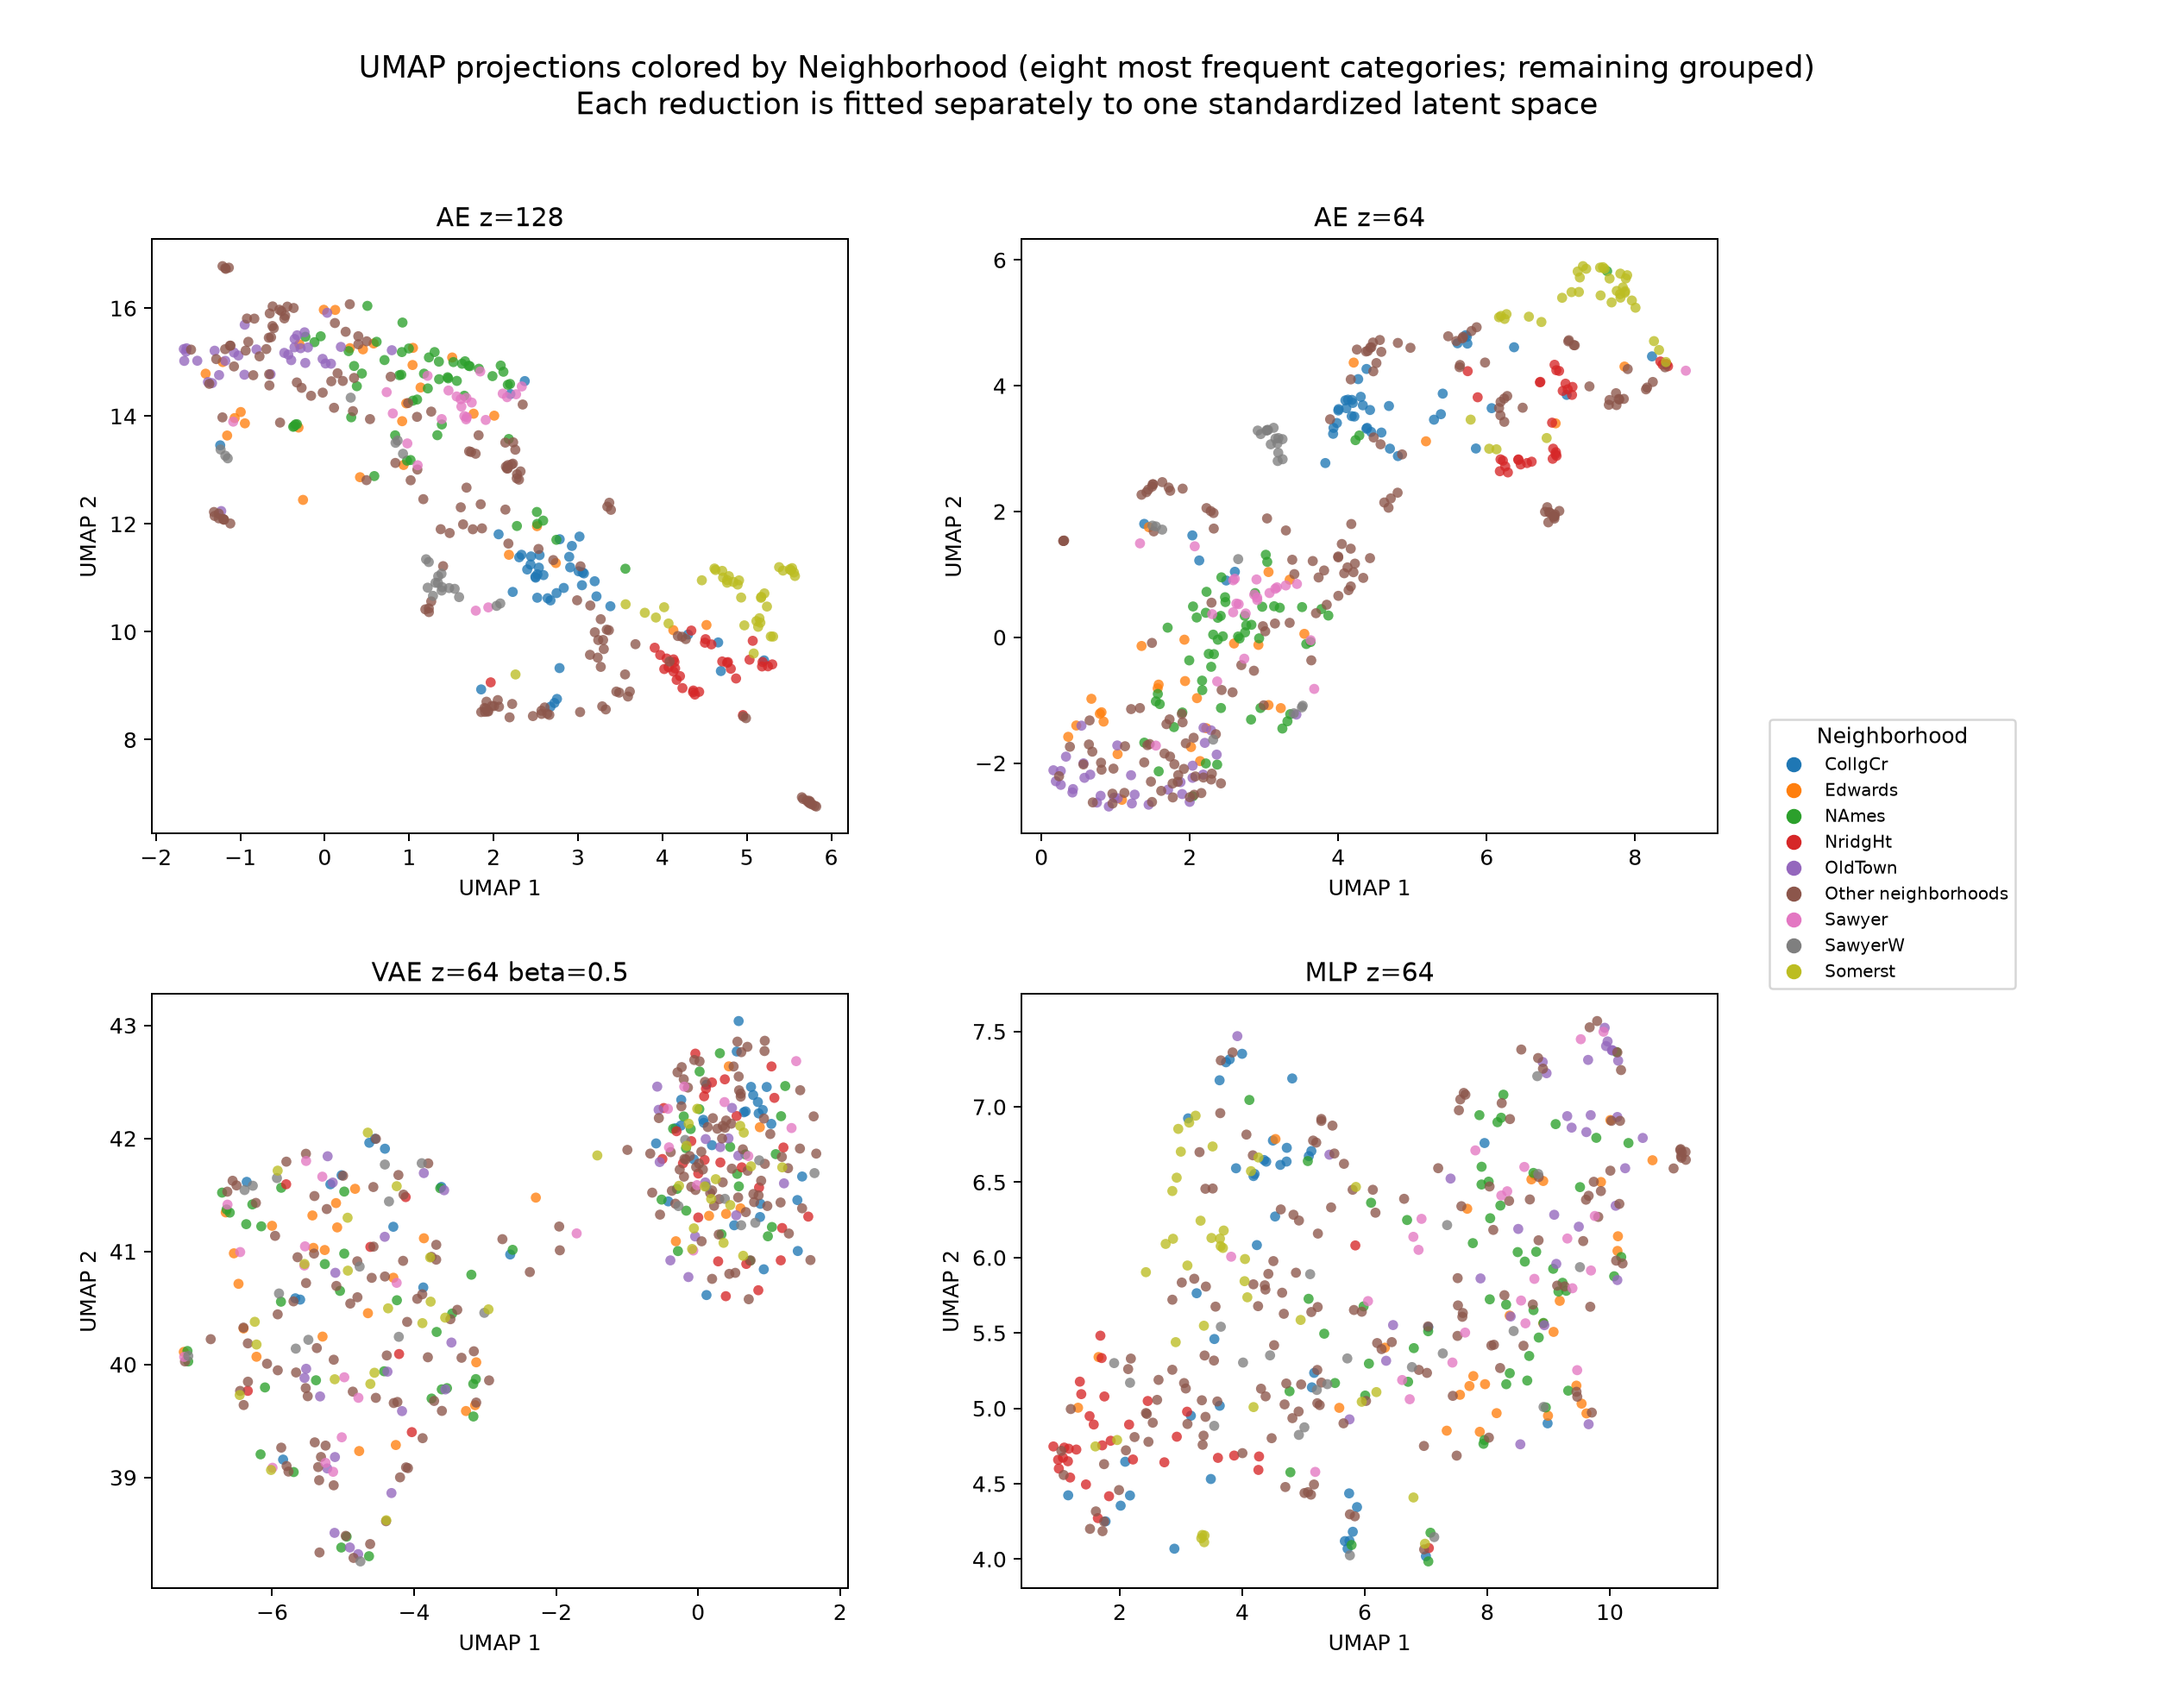

**UMAP colored by Sale Condition**

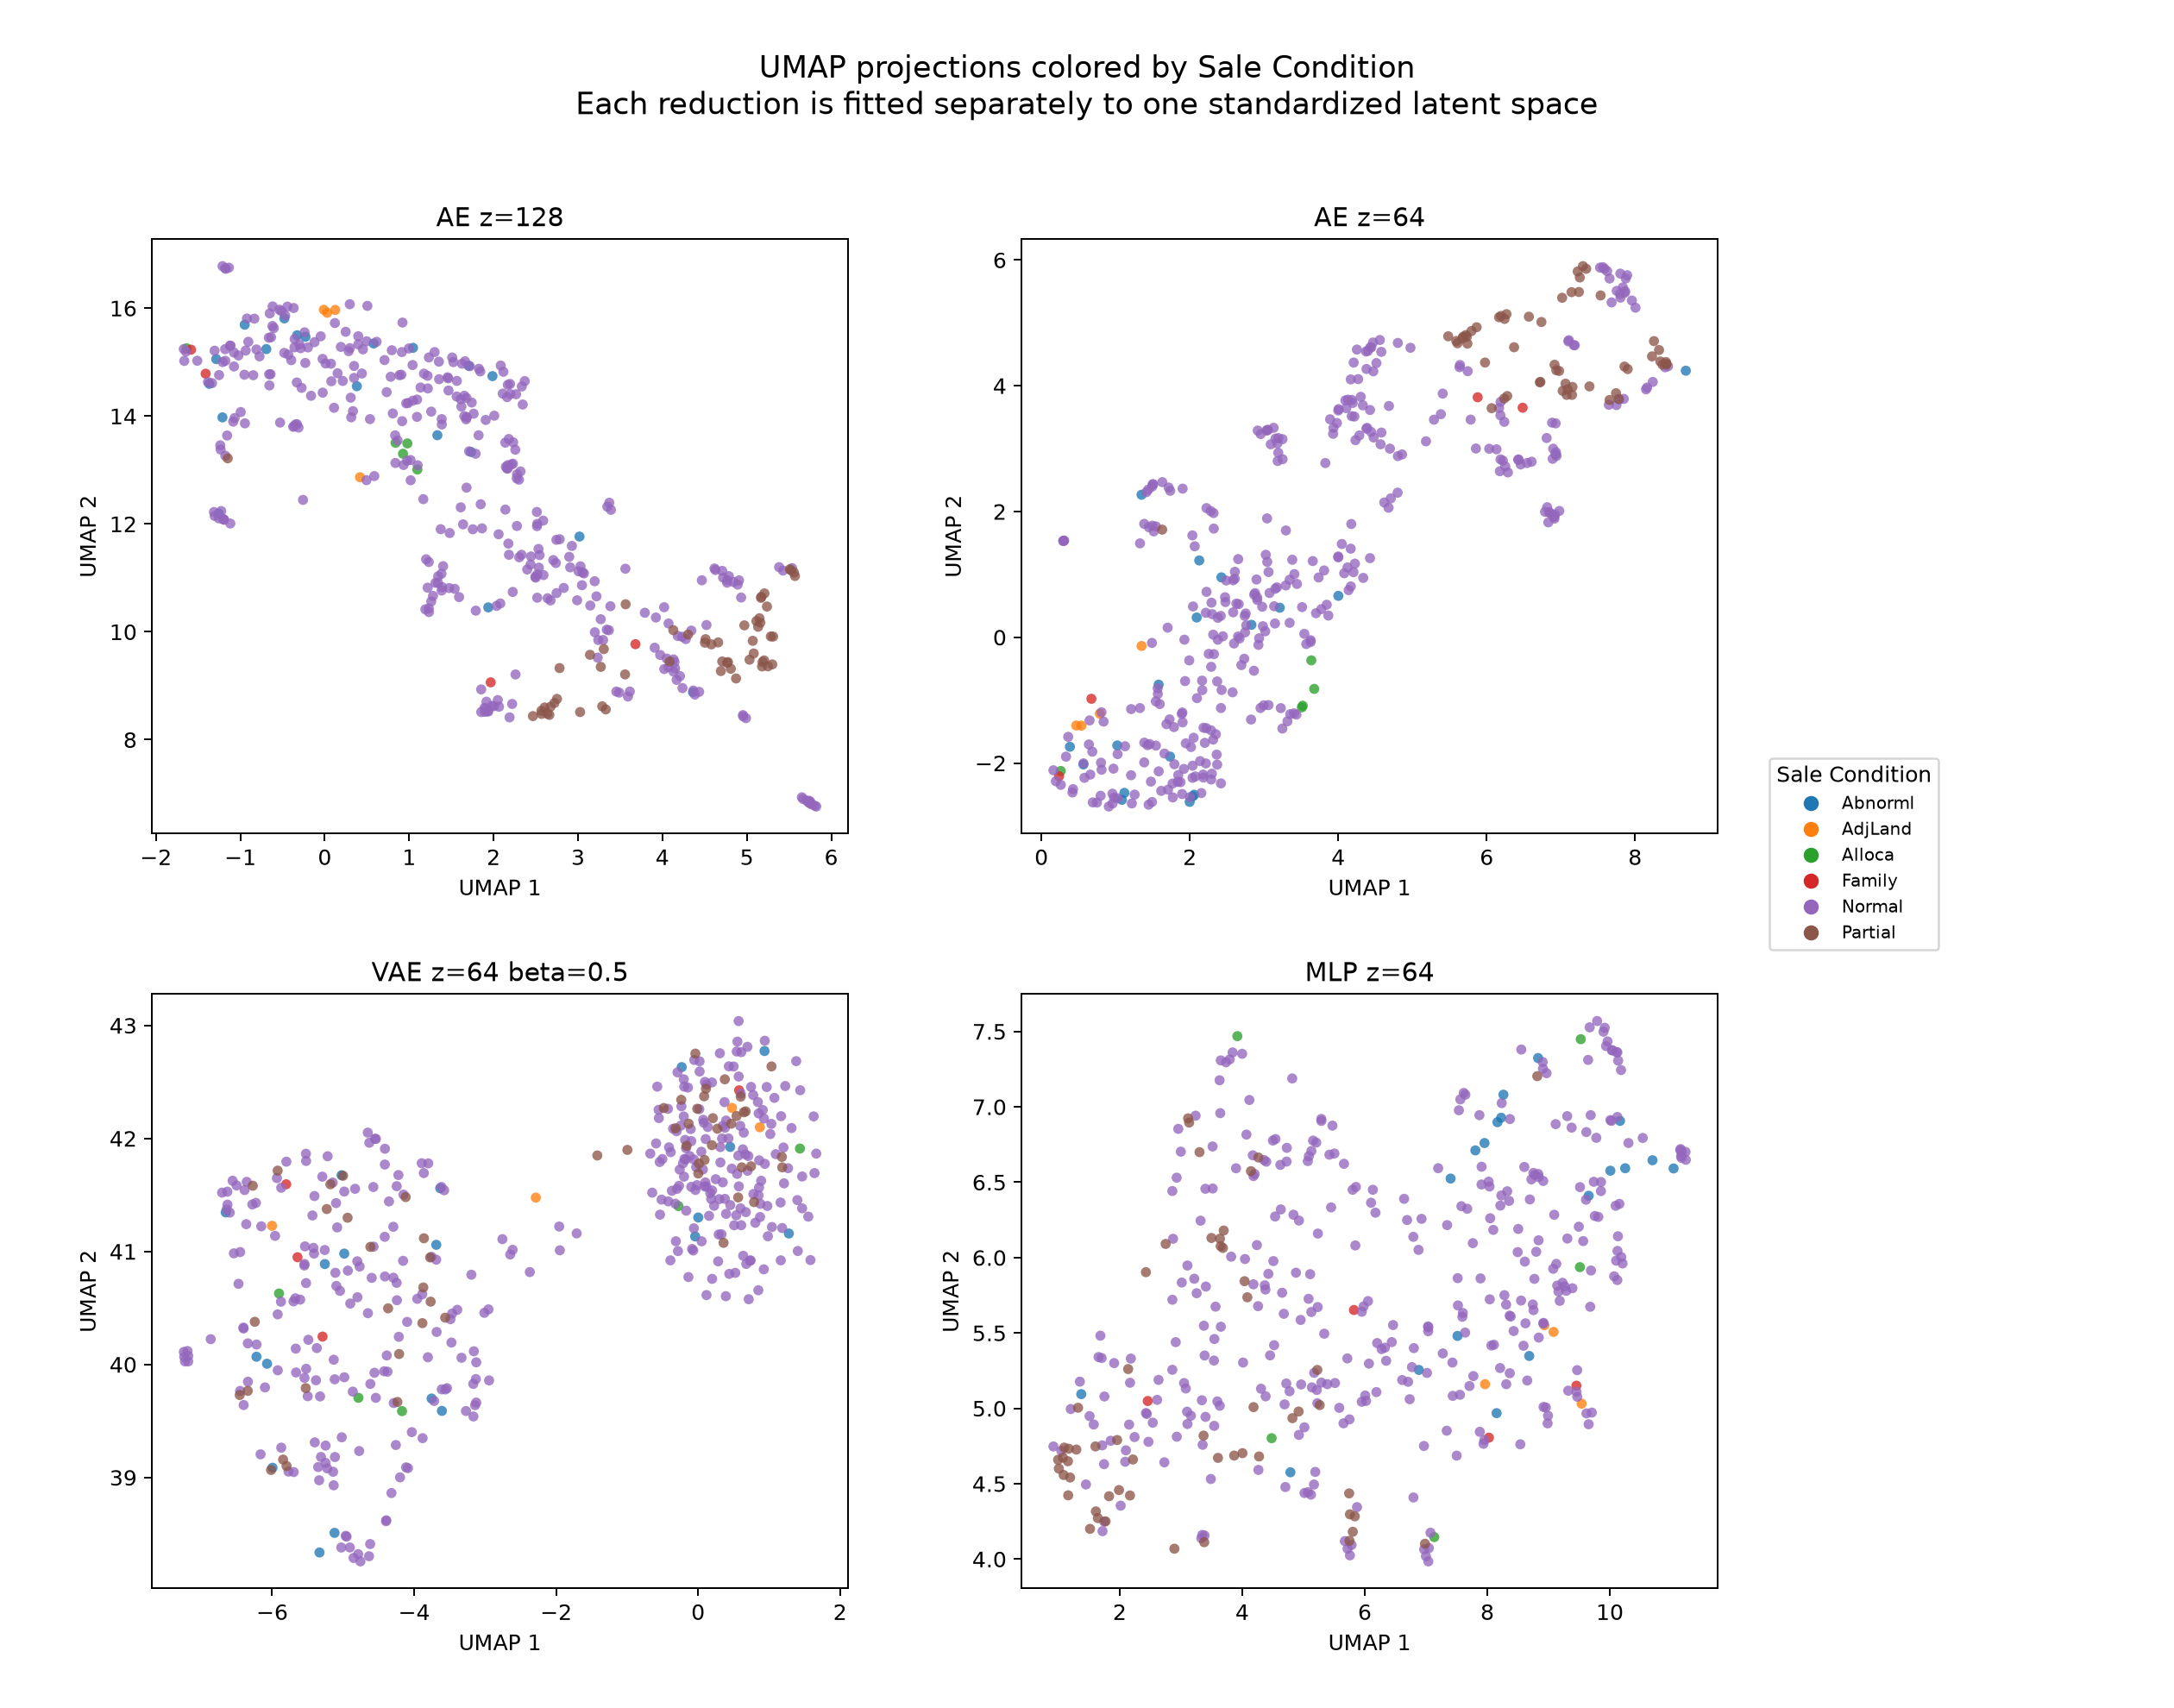

In [12]:
with np.load(RESULTS / "latent_umap_embeddings.npz") as archive:
    umap_shapes = {name: archive[name].shape for name in ["AE z=128", "AE z=64", "VAE z=64 beta=0.5", "MLP z=64"]}
display(pd.DataFrame({"Representation": umap_shapes.keys(), "UMAP shape": umap_shapes.values()}))
display(pd.DataFrame([latent_metadata["umap"]]))

show_images([
    ("UMAP colored by SalePrice", FIGURES / "latent" / "umap_saleprice.png"),
    ("UMAP colored by Overall Qual", FIGURES / "latent" / "umap_overall_quality.png"),
    ("UMAP colored by Neighborhood", FIGURES / "latent" / "umap_neighborhood.png"),
    ("UMAP colored by Sale Condition", FIGURES / "latent" / "umap_sale_condition.png"),
])

## 13. Silhouette Score and Trustworthiness

Silhouette is calculated in each standardized **original latent space**, not
on the 2D coordinates. Overall Qual categories with fewer than five test cases
are excluded. Neighborhoods with fewer than ten cases are grouped as
`Other (<10)`. The transaction-condition analysis uses only `Normal` and
`Abnorml`.

Scores near zero or below zero indicate strong category overlap. The VAE's high
Normal/Abnorml Silhouette is exploratory and does not establish anomaly
detection superiority: only 19 positive observations exist and the earlier VAE
ROC-AUC is modest. Trustworthiness measures local-neighborhood preservation of
the 2D projection; it does not establish predictive quality.

In [13]:
latent_metrics = pd.read_csv(RESULTS / "latent_metrics.csv")
trustworthiness_table = pd.read_csv(RESULTS / "latent_embedding_quality.csv")

silhouette_pivot = latent_metrics.pivot(index="model", columns="grouping", values="silhouette_score")
display(silhouette_pivot)
display(trustworthiness_table.pivot(index="model", columns="method", values="trustworthiness_k15"))

assert not latent_metrics["computed_on_2d_projection"].any()
assert (latent_metrics["space"] == "per-model standardized original latent representation").all()
print("Verified: every Silhouette score uses the original standardized latent representation.")

grouping,Neighborhood,Normal vs Abnorml,Overall Qual
model,,,
AE z=128,-0.016587,0.177495,-0.046525
AE z=64,-0.022167,0.161005,-0.035976
MLP z=64,-0.138004,0.246647,-0.012338
VAE z=64 beta=0.5,-0.466828,0.516616,-0.383551


method,UMAP,t-SNE
model,,
AE z=128,0.812953,0.839473
AE z=64,0.836650,0.859103
MLP z=64,0.812793,0.830595
VAE z=64 beta=0.5,0.617752,0.589749


Verified: every Silhouette score uses the original standardized latent representation.


## 14. Comparison with the Supervised MLP from Workshop 2

The MLP is not fed the Workshop 4 matrix. It uses the original Workshop 2
preprocessing with 261 inputs, hidden layers 128 and 64, dropout 0.05, and the
activation after the second ReLU. Its checkpoint is loaded in evaluation mode
with frozen parameters and no gradient tracking. AE/VAE representations are
optimized for reconstruction; the MLP representation is optimized for
standardized log-price prediction.

The MLP has the least-negative Overall Qual Silhouette and the clearest visual
price gradient, but weaker Neighborhood separation than the AEs. AE z=64 has
the highest t-SNE/UMAP trustworthiness. The VAE has the weakest projection
trustworthiness and the most negative quality/neighborhood Silhouette, while
showing the highest exploratory Normal/Abnorml Silhouette. These different
criteria answer different questions and do not define a global ranking.

In [14]:
model_comparison = pd.DataFrame(
    [
        ["AE z=128", "Unsupervised reconstruction", 262, 128,
         ae_results.set_index("latent_dim").loc[128, "best_validation_mse"],
         reconstruction.query("model == 'AE' and feature_group == 'all'")["reconstruction_mse"].iloc[0],
         trustworthiness_table.query("model == 'AE z=128' and method == 't-SNE'")["trustworthiness_k15"].iloc[0],
         trustworthiness_table.query("model == 'AE z=128' and method == 'UMAP'")["trustworthiness_k15"].iloc[0]],
        ["AE z=64", "Unsupervised reconstruction", 262, 64,
         ae_results.set_index("latent_dim").loc[64, "best_validation_mse"], np.nan,
         trustworthiness_table.query("model == 'AE z=64' and method == 't-SNE'")["trustworthiness_k15"].iloc[0],
         trustworthiness_table.query("model == 'AE z=64' and method == 'UMAP'")["trustworthiness_k15"].iloc[0]],
        ["VAE z=64 beta=0.5", "Variational reconstruction + KL", 262, 64,
         vae_results.set_index("target_beta").loc[0.5, "validation_reconstruction_mse"],
         reconstruction.query("model == 'VAE' and feature_group == 'all'")["reconstruction_mse"].iloc[0],
         trustworthiness_table.query("model == 'VAE z=64 beta=0.5' and method == 't-SNE'")["trustworthiness_k15"].iloc[0],
         trustworthiness_table.query("model == 'VAE z=64 beta=0.5' and method == 'UMAP'")["trustworthiness_k15"].iloc[0]],
        ["MLP z=64", "Supervised log-price regression", 261, 64, np.nan, np.nan,
         trustworthiness_table.query("model == 'MLP z=64' and method == 't-SNE'")["trustworthiness_k15"].iloc[0],
         trustworthiness_table.query("model == 'MLP z=64' and method == 'UMAP'")["trustworthiness_k15"].iloc[0]],
    ],
    columns=["Representation", "Training objective", "Inputs", "Latent dimension", "Validation reconstruction MSE", "Test reconstruction MSE", "t-SNE trustworthiness", "UMAP trustworthiness"],
)
display(model_comparison)

checkpoint_audit = pd.DataFrame(
    {
        "Representation": list(latent_metadata["checkpoint_paths"]),
        "Checkpoint": list(latent_metadata["checkpoint_paths"].values()),
        "SHA-256": list(latent_metadata["checkpoint_hashes"].values()),
    }
)
display(checkpoint_audit)

,Representation,Training objective,Inputs,Latent dimension,Validation reconstruction MSE,Test reconstruction MSE,t-SNE trustworthiness,UMAP trustworthiness
0,AE z=128,Unsupervised reconstruction,262,128,0.452771,0.399277,0.839473,0.812953
1,AE z=64,Unsupervised reconstruction,262,64,0.492260,NaN,0.859103,0.836650
2,VAE z=64 beta=0.5,Variational reconstruction + KL,262,64,1.012741,0.940321,0.589749,0.617752
3,MLP z=64,Supervised log-price regression,261,64,NaN,NaN,0.830595,0.812793


,Representation,Checkpoint,SHA-256
0,AE z=128,workshop4_autoencoders\checkpoints\ae_best.pt,91bfadc0949319edcb1eb60c8980235d26c7eb5222d9e6...
1,AE z=64,workshop4_autoencoders\checkpoints\ae_latent_6...,011f181f9c9caead994abd7c29d54aa53160287a230dbe...
2,VAE z=64 beta=0.5,workshop4_autoencoders\checkpoints\vae_best.pt,3c916aeb8da593cba3f8adb21884e82c4d2d60d7df1d73...
3,MLP z=64,checkpoints\part_a\model_e4_wide_128_64_seed42.pt,3ed12f21a70ca642bf443d5e22aaf7656ff20d87e1d42c...


## 15. Discussion and Limitations

The standard AE is the strongest reconstruction model in both validation and
test. Expanding its latent dimension from 32 to 128 reduces validation MSE, but
the z=64/z=128 latent comparison is not a causal dimensionality experiment
because the networks were trained independently. The selected VAE sacrifices
substantial reconstruction fidelity. Beta 1 and beta 4 show severe posterior
collapse, while beta 0.5 retains more active units but remains seed-sensitive.

Reconstruction error provides only weak detection of `Abnorml` transactions.
The label describes sale circumstances rather than structural defects, the
positive test class has only 19 observations, and bootstrap intervals are wide.
A low reconstruction MSE therefore does not imply strong anomaly ranking.

t-SNE and UMAP are nonlinear visualization tools sensitive to hyperparameters,
local density, and stochastic initialization. Separate fits can be compared
qualitatively using consistent colors, but their coordinates and distances are
not shared. Silhouette depends on label imbalance, scaling, and category
definitions. The high VAE Normal/Abnorml value must be considered together with
the modest anomaly AUC, not treated as proof of superiority.

Finally, all experiments use one fixed split and a relatively small tabular
dataset. The observed test partition must not be reused for additional model
selection. Reconstruction errors in standardized feature space are not
comparable with the dollar-scale MAE reported for the Workshop 2 MLP.

## 16. Conclusions

The Workshop 4 experiments support four bounded conclusions:

1. The standard AE benefits from increased latent capacity in the tested range;
   z=128 obtains validation MSE 0.4528 and frozen test MSE 0.3993.
2. VAE beta 0.5 is the only evaluated seed-42 beta without severe collapse, but
   its reconstruction and multi-seed stability are worse than the standard AE.
3. Reconstruction-based detection provides only limited separation of
   `Abnorml` transactions; the AE reaches ROC-AUC 0.6317 with low recall and an
   uncertainty interval that includes chance-level discrimination.
4. The supervised MLP organizes its hidden representation most clearly along
   price and quality gradients, whereas the AEs preserve broader reconstructive
   structure. The VAE's regularized geometry is smoother but less faithful to
   several observed categories.

These findings describe this fixed Ames Housing protocol only. They do not
establish universal superiority of supervised or unsupervised representations.
The saved manifests, hashes, metrics, coordinates, and figures provide a
reproducible basis for the subsequent academic report without rerunning
training or dimensionality reduction.

In [15]:
# Final notebook integrity record: read-only checks only.
assert len(pd.read_csv(RESULTS / "reconstruction_observation_scores.csv")) == 440
assert len(pd.read_csv(RESULTS / "latent_test_labels.csv")) == 440
assert latent_metadata["no_training_performed"] is True
assert latent_metadata["test_results_not_used_for_model_selection"] is True
assert all(
    details["tsne_max_absolute_repeat_difference"] <= 1e-6
    and details["umap_max_absolute_repeat_difference"] <= 1e-6
    for details in latent_metadata["reducer_reproducibility"].values()
)

integrity = pd.DataFrame(
    {
        "Artifact": ["data/splits.json", "ae_best.pt", "vae_best.pt", "Workshop 2 MLP"],
        "SHA-256": [
            sha256(ROOT / "data" / "splits.json"),
            sha256(CHECKPOINTS / "ae_best.pt"),
            sha256(CHECKPOINTS / "vae_best.pt"),
            sha256(ROOT / "checkpoints" / "part_a" / "model_e4_wide_128_64_seed42.pt"),
        ],
    }
)
display(integrity)
print("Notebook completed successfully from saved artifacts.")
print("No training, checkpoint selection, threshold calibration, t-SNE fitting, or UMAP fitting was executed.")

,Artifact,SHA-256
0,data/splits.json,cb2572a0e61676c02c5957107a59975353cbaffd2750f5...
1,ae_best.pt,91bfadc0949319edcb1eb60c8980235d26c7eb5222d9e6...
2,vae_best.pt,3c916aeb8da593cba3f8adb21884e82c4d2d60d7df1d73...
3,Workshop 2 MLP,3ed12f21a70ca642bf443d5e22aaf7656ff20d87e1d42c...


Notebook completed successfully from saved artifacts.
No training, checkpoint selection, threshold calibration, t-SNE fitting, or UMAP fitting was executed.
